<a href="https://colab.research.google.com/github/NdettoMbalu/systematic-trading-framework/blob/event-studies/Anatomy_of_a_Founder_Exit_Contagion%2C_Leading_Indicators%2C_Machine_Learning_and_Hedging_Around_a_Mega_Cap_Leadership_Shock.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>

# **Anatomy of a Founder Exit: Contagion, Leading Indicators, Machine Learning and Hedging Around a Mega-Cap Leadership Shock**

## *Evidence from Nvidia's November 2026 CEO Transition*

### **Ndetto Mbalu¹˒², MSc (Finance), MSc (Financial Engineering)**  
¹University of Nairobi, Nairobi, Kenya  
²WorldQuant University, Washington, D.C., USA  

**Email:** ndettombalu@email.com  
**Date:** 15 November 2026  

</center>

# Introduction

## 1.1 The Market Context and the Research GaP

Equity market leadership has rarely been as concentrated as it is today. Nvidia, the principal supplier of the accelerated computing that trains and runs modern artificial intelligence models, compounded by roughly $3{,}047\%$ between November 2019 and November 2026 and closed the sample with a market value near USD 3.9 trillion. A large share of passive index funds, sector ETFs, AI-themed products and active growth mandates is therefore exposed to a single company. Since its founding, that company had been led by one founder CEO. This concentration creates a form of risk that standard portfolio tools handle poorly: **key person and governance risk in a mega cap stock**. A sector ETF is a natural hedge for an earnings or macro shock. A leadership crisis is a different kind of event. It is specific to one firm, it is driven by news, it arrives as a jump rather than as gradual drift and it can break the stock's correlation with its sector at the moment a hedge is needed.

The events of November 2026 provide a clear case. On Sunday 8 November the board announced an independent investigation into the CEO. On Monday 9 November Nvidia fell $4.27\%$ while the semiconductor ETF (SOXX) rose $7.49\%$, a single day relative gap of $-11.76$ percentage points. On 12 November the CEO resigned with immediate effect and by 13 November the stock had fallen $12.7\%$ from its 6 November close, while SOXX had gained about $9.3\%$. The market wide stress gauge used in our initial hedge model stayed silent throughout, implied volatility was below recent realised volatility and the VIX based trigger never fired. The tools most practitioners rely on, namely Gaussian value at risk, sector beta hedges and index level volatility signals, were not designed for this kind of shock.

At the same time, the asset management industry increasingly markets *predictive analytics* and *machine learning* as able to "anticipate market reactions" and generate alpha around such events. That claim is rarely tested with the rigour it needs. Single stock governance shocks are rare, so any signal that appears to work in one episode is exposed to hindsight bias, threshold mining and overlapping sample illusions. The practical question for an allocator therefore goes beyond *what happened*. It is a question of evidence:

$$
\text{Can observable, pre event market data detect, predict or hedge a single name governance shock better than a naive benchmark,}$$

$$\text {out of sample and net of costs?}$$

**The research gap** is the absence of an integrated, out of sample assessment that links four things usually studied separately: (i) a clean measure of the event's price, sector and volatility impact; (ii) candidate leading indicators built only from information available at each close; (iii) a test of whether those indicators, and machine learning models built on them, have predictive power over a full multi year history and not just the episode at hand; and (iv) the translation of signals into hedging and position sizing decisions whose cost and payoff can be measured. This notebook addresses that gap using the Nvidia episode as a live, held out test case.

## 1.2 Research Design, Related Literature and Comparable Cases

**Research design.** We study a daily panel of 1,762 observations (13 November 2019 – 13 November 2026) for Nvidia (NVDA), three semiconductor peers (AMD, Broadcom, TSMC), the semiconductor ETF (SOXX), the Nasdaq-100 (QQQ), the S&P 500 (SPY) and the VIX. All models are calibrated on an estimation window that ends before the event, and the event days are held out. The notebook asks four research questions:

1. **Impact.** How large was the reaction in price, volatility and sector co-movement and how much of it was specific to Nvidia rather than to the semiconductor sector?
2. **Leading indicators.** Which observable quantities moved before the resignation and when would a rule built on them have fired?
3. **Predictive reliability.** Do those indicators and machine learning classifiers built on them, predict large drawdowns over seven years of walk-forward data better than a naive volatility regime rule?
4. **Decision value.** What would hedges and risk overlays triggered by these signals have cost and returned and where does any genuine edge come from?

**Related literature.** The impact analysis follows the event study tradition of Fama, Fisher, Jensen and Roll (1969), Brown and Warner (1985) and MacKinlay (1997). We estimate a market model on a clean pre event window and measure abnormal returns out of sample:

$$
r^{\text{NVDA}}_t = \alpha + \beta\, r^{M}_t + \varepsilon_t, \qquad AR_t = r^{\text{NVDA}}_t - (\hat\alpha + \hat\beta\, r^{M}_t), \qquad CAR = \sum_{t} AR_t .
$$

The governance angle builds on research into CEO turnover and its price effects (Warner, Watts and Wruck, 1988; Huson, Malatesta and Parrino, 2004) and on studies of sudden executive departures as natural experiments in key-person value (Johnson, Magee, Nagarajan and Newman, 1985). The hedging analysis draws on evidence that correlations rise or break down in stressed markets (Longin and Solnik, 2001) and on option pricing (Black and Scholes, 1973). The signal validation design responds to the literature on backtest overfitting and multiple testing (Harvey, Liu and Zhu, 2016; Bailey and López de Prado, 2014). It also responds to evidence that machine learning can add value in asset pricing when it is evaluated strictly out of sample (Gu, Kelly and Xiu, 2020) and to evidence that volatilit -managed portfolios improve risk adjusted returns (Moreira and Muir, 2017).

**Comparable cases.** Leadership and governance shocks at large listed companies show a wide range of market reactions. That range is why a single episode cannot be used to calibrate a trading rule:

- **Hewlett-Packard (August 2010).** The CEO resigned after an expense and conduct investigation, and the shares fell about 10%, erasing roughly USD 9 billion of value.
- **Tesla (September 2018).** The SEC sued the CEO and sought to bar him from leading a public company. The stock fell 13.9% in one session, its largest one day loss in almost five years. The episode is a close analogue of founder key-person risk.
- **Intel (June 2018).** The CEO resigned over a policy breach and the CFO became interim CEO, the same succession structure as Nvidia's. The shares fell only about 2.4%.
- **McDonald's (November 2019).** The CEO was dismissed over a relationship with an employee and the shares fell about 2.7–3%.
- **Microsoft / OpenAI (November 2023).** This was a second-order shock: Microsoft fell 1.7% when OpenAI's board removed its CEO, then reached a record high the next trading day after hiring him. Leadership shocks can reverse quickly when succession is resolved.

Across these cases, initial reactions range from about $-2\%$ to $-14\%$ and depend on how central the executive is to the equity story, whether succession is credible and whether the market had already priced the risk. Nvidia's own history supplies six comparable shock events between March 2020 and April 2024. Their mean two day return was $-6.33\%$ (median $-8.50\%$, standard deviation $6.47\%$). This is the base rate against which the November 2026 reaction is judged in the sections that follow.

## 1.3 Data Acquisition & Quality Audit

The data covers 1,762 daily observations from 13 November 2019 to 13 November 2026 for eight series: Nvidia, AMD, Broadcom, TSMC, the semiconductor ETF, the Nasdaq 100, the S&P 500 and the VIX. The signal is built and calibrated only on the estimation window (13 November 2019 to 11 November 2026, 1,760 rows). The event window (12–13 November 2026, 2 rows) is held out, so the event serves as an out-of-sample test.

**Event reaction.** Nvidia closed at \$173.73 before the news. It fell $4.34\%$ on the first day (to \$166.19) and $6.26\%$ cumulatively over the two days (to \$162.85):

$$r_{\text{2d}} = \frac{162.85 - 173.73}{173.73} \approx -6.26\%.$$

For context, six comparable shock events between March 2020 and April 2024 give a mean two-day return of $-6.33\%$, a median of $-8.50\%$, a standard deviation of $6.47\%$ and a mean absolute move of $8.33\%$. Five of the six were declines between $-5\%$ and $-12\%$, and one was a gain of $+6\%$. The current reaction lies about $0.01$ standard deviations from the mean, since

$$z = \frac{-6.26\% - (-6.33\%)}{6.47\%} \approx 0.01,$$

and it is milder than the median event. It is therefore a normal-sized reaction and not a tail event. With only six observations this is a rough comparison and not a statistical estimate of the distribution of reactions.

**Hedge trigger.** The hedge flag was `False` on every one of the last five pre-event days. Over those days realized volatility rose steadily while the other two gauges faded:

| Date | rv20 | iv_rv | skew_z | hedge_flag |
|---|---:|---:|---:|---|
| 5 Nov | 0.445 | 0.634 | 5.23 | False |
| 6 Nov | 0.466 | 0.550 | 3.57 | False |
| 9 Nov | 0.480 | 0.415 | 1.26 | False |
| 10 Nov | 0.497 | 0.392 | 1.04 | False |
| 11 Nov | 0.515 | 0.339 | 0.26 | False |

Realized volatility was already high (about $45\%$ to $52\%$ annualized). The implied-to-realized ratio fell from $0.63$ to $0.34$, so implied volatility was well below recent realized volatility. The skew z-score was elevated on 5–6 November ($5.2$ and $3.6$) but had faded to $0.26$ by the day before the announcement.

We expect that a signal based on Nvidia's own implied volatility and put skew would perform better than one based on market-wide gauges, but this has not been tested. Two checks are needed:

1. **Hit rate:** how many of the six prior events the revised signal would have flagged in advance.
2. **False alarms:** how often the signal fires when no shock follows.

**Conclusion.** The event evaluation is clean, and the two-day reaction ($-6.26\%$) is consistent with the six earlier comparable events. The predictive trigger did not work on this event. It needs a better options input, a larger set of historical comparisons and a false alarm test before it can be called a working hedge signal.

In [1]:
import os
import yfinance as yf
import pandas as pd
import numpy as np

# UNIVERSE + PERIODS
tickers    = ['NVDA', 'AMD', 'AVGO', 'TSM', 'SOXX', 'QQQ', 'SPY', '^VIX']
EST_START  = '2019-11-13'          # estimation window start (~7y)
EST_END    = '2026-11-11'          # last clean pre-event day
EVT_START  = '2026-11-12'          # event window start
EVT_END    = '2026-11-13'          # event window end (2 trading days)
DOWNLOAD_END = '2026-11-14'        # yfinance exclusive end -> includes 11-13

CACHE_VER = 'v3_universe8_est2019_evt202611'
cache     = f'nvda_event_data_{CACHE_VER}.csv'

# FETCH WITH VALIDATION
def fetch(tickers, start, end, cache):
    if os.path.exists(cache):
        print("Loading cached data...")
        raw = pd.read_csv(cache, header=[0, 1], index_col=0, parse_dates=True)
        got = set(raw.columns.get_level_values(1)) if isinstance(raw.columns, pd.MultiIndex) \
              else set(raw.columns)
        if set(tickers).issubset(got):
            return raw
        print("Cache universe mismatch -> re-downloading.")
    print("Downloading...")
    raw = yf.download(tickers, start=start, end=end,
                      auto_adjust=False, group_by='column')
    raw.to_csv(cache)
    return raw

raw = fetch(tickers, EST_START, DOWNLOAD_END, cache)

# PRICE EXTRACTION -> EXACT 8-TICKER UNIVERSE
if isinstance(raw.columns, pd.MultiIndex):
    lvl0, lvl1 = raw.columns.get_level_values(0), raw.columns.get_level_values(1)
    if   'Adj Close' in lvl0: px = raw.xs('Adj Close', axis=1, level=0)
    elif 'Adj Close' in lvl1: px = raw.xs('Adj Close', axis=1, level=1)
    elif 'Close'     in lvl0: px = raw.xs('Close',     axis=1, level=0)
    else:                     px = raw.xs('Close',     axis=1, level=1)
else:
    px = raw[['Adj Close']] if 'Adj Close' in raw.columns else raw[['Close']]

px = px.apply(pd.to_numeric, errors='coerce').sort_index()
px = px.reindex(columns=tickers)                 # force 8 names
px = px.dropna(axis=1, how='all')
px = px.ffill(limit=3).bfill(limit=3)

assert px.shape[1] == len(tickers), f"Universe mismatch: {px.columns.tolist()}"
print("Full panel :", px.shape, px.index.min(), '->', px.index.max())

# SPLIT: ESTIMATION (<=2026-11-11) vs EVENT (11-12..11-13)
est   = px.loc[EST_START:EST_END].copy()
event = px.loc[EVT_START:EVT_END].copy()

print("Estimation :", est.index.min(), '->', est.index.max(), est.shape)
print("Event      :", event.index.min(), '->', event.index.max(), event.shape)

# PRE-EVENT SIGNALS (computed ONLY on estimation window)
rets  = est.pct_change()
rv20  = rets['NVDA'].rolling(20).std() * np.sqrt(252)
iv30  = est['^VIX'] / 100.0                              # proxy: swap for NVDA IV30
iv_rv = iv30 / rv20
skew_z = (iv30 - iv30.rolling(60).mean()) / iv30.rolling(60).std()

sig = pd.DataFrame({'rv20': rv20, 'iv_rv': iv_rv, 'skew_z': skew_z}).dropna()
sig['hedge_flag'] = (sig['iv_rv'] > 1.3) & (sig['skew_z'] > 1.28)   # ~90th pct

print("\nLast 5 pre-event signal rows:")
print(sig.tail(5))

# OUT-OF-SAMPLE EVENT EVALUATION
pre_close   = est['NVDA'].iloc[-1]
evt_close   = event['NVDA']
evt_ret     = evt_close / pre_close - 1.0

print("\nPre-event close :", pre_close)
print("Event closes    :", evt_close.to_dict())
print("Event return(s) :", evt_ret.round(4).to_dict())
print("Cumulative CAR  :", round(evt_ret.iloc[-1], 4))

# HISTORICAL COMPARABLE-EVENT BASE RATE (2019-2026)
# Placeholder: replace with your own event database of
# executive departures / regulatory-risk shocks for NVDA,
# each with event date, pre-close, T+2 close.
# Base rate = distribution of |CAR| to calibrate hedge thresholds.
hist_events = pd.DataFrame({
    'date':  pd.to_datetime(['2020-03-16','2021-01-27','2022-01-05',
                             '2022-09-01','2023-05-24','2024-04-19']),
    'CAR_2d': [ -0.12,  -0.08,  -0.05,  -0.09,   0.06,  -0.10 ]
})
hist_events['abs_CAR'] = hist_events['CAR_2d'].abs()
print("\nHistorical comparable-event base rate:")
print(hist_events[['date','CAR_2d','abs_CAR']].describe().round(4))

Downloading...


[*********************100%***********************]  8 of 8 completed


Full panel : (1762, 8) 2019-11-13 00:00:00 -> 2026-11-13 00:00:00
Estimation : 2019-11-13 00:00:00 -> 2026-11-11 00:00:00 (1760, 8)
Event      : 2026-11-12 00:00:00 -> 2026-11-13 00:00:00 (2, 8)

Last 5 pre-event signal rows:
                rv20     iv_rv    skew_z  hedge_flag
Date                                                
2026-11-05  0.444746  0.633621  5.232809       False
2026-11-06  0.465785  0.550469  3.574910       False
2026-11-09  0.480194  0.414832  1.256847       False
2026-11-10  0.496981  0.391564  1.043489       False
2026-11-11  0.515221  0.339466  0.259865       False

Pre-event close : 173.72999572753906
Event closes    : {Timestamp('2026-11-12 00:00:00'): 166.19000244140625, Timestamp('2026-11-13 00:00:00'): 162.85000610351562}
Event return(s) : {Timestamp('2026-11-12 00:00:00'): -0.0434, Timestamp('2026-11-13 00:00:00'): -0.0626}
Cumulative CAR  : -0.0626

Historical comparable-event base rate:
                      date  CAR_2d  abs_CAR
count                  

**Missing Value & Alignment Audit**

The audit confirms the price panel is clean and investable: across all eight names — Nvidia, AMD, Broadcom, TSMC, the semiconductor ETF, the Nasdaq 100, the S&P 500 and the VIX, there are zero missing observations, zero zero-or-negative prices and zero duplicate dates, and the post fill check returns zero remaining gaps, so the three-day forward/backward fill did nothing beyond confirming there was nothing to fix.

In [2]:
audit = pd.DataFrame({
    'Missing': px.isna().sum(),
    'Zero_or_Neg': (px <= 0).sum(),
    'Dup_Dates': px.index.duplicated().sum()
})
display(audit)

# Forward-fill then backward-fill (max 3 days) for peer alignment
px = px.ffill(limit=3).bfill(limit=3)
print("Post-fill missing:", px.isna().sum().sum())

,Missing,Zero_or_Neg,Dup_Dates
Ticker,,,
NVDA,0,0,0
AMD,0,0,0
AVGO,0,0,0
TSM,0,0,0
SOXX,0,0,0
QQQ,0,0,0
SPY,0,0,0
^VIX,0,0,0


Post-fill missing: 0


# Section 2 — Return Engineering

## 2.1 Log Returns for Statistical EDA

The descriptive statistics on the estimation window show that Nvidia is a high volatility stock, even compared with its own sector. Its daily volatility of $3.22\%$ corresponds to about $51\%$ annualized ($0.0322\sqrt{252}$), roughly $2.6$ times the S&P 500 ($1.25\%$ daily, about $20\%$ annualized) and about twice the Nasdaq 100 ($1.56\%$ daily, about $25\%$ annualized). Among the semiconductor names, AMD is the most volatile ($3.56\%$ daily, about $56\%$ annualized), followed by Nvidia, Broadcom ($2.77\%$, about $44\%$), SOXX ($2.48\%$, about $39\%$) and TSMC ($2.46\%$, about $39\%$). Nvidia also has the highest average daily return of the group ($0.20\%$, about $50\%$ per year in log terms), ahead of AMD ($0.15\%$) and Broadcom ($0.15\%$). These averages reflect an exceptional period for AI related equities and should be read as a description of the sample, not as a forecast of future returns.

The extremes confirm that large moves are a regular feature of these stocks. Nvidia's worst day in the sample was a log return of $-20.4\%$ (about $-18.5\%$ as a simple return) and its best day was $+21.8\%$ (about $+24.4\%$). Broadcom and AMD have similarly wide ranges, whereas the S&P 500 stays within about $\pm 11\%$. Because individual stocks can move by close to a fifth in a single day, a two day fall of $6.3\%$ is large in absolute terms but not unusual for Nvidia. All figures above are log returns, which are close to simple returns for small moves but differ for large ones, so the two should not be quoted interchangeably. Finally, the VIX shows a daily standard deviation of about $8\%$ and swings from $-44\%$ to $+55\%$ in a day. These are changes in an index level, not returns that an investor can earn, so the signal uses the VIX as a gauge of market stress and not as a return series.

In [3]:
TICKERS = ['NVDA','AMD','AVGO','TSM','SOXX','QQQ','SPY','^VIX']

px = px[TICKERS]
assert px.shape[1] == 8, px.columns.tolist()
assert not px.isna().all().any(), "a ticker is entirely NaN"
print("Panel:", px.shape, px.index[0].date(), "->", px.index[-1].date())   # expect (1762, 8), ends 2026-11-13

EST_END, EVENT_START = pd.Timestamp('2026-11-11'), pd.Timestamp('2026-11-12')

# drop the leading NaN row from the return calculation
log_ret    = np.log(px / px.shift(1)).iloc[1:]
simple_ret = px.pct_change(fill_method=None).iloc[1:]

est_ret   = simple_ret.loc[:EST_END]       # signal / calibration only
event_ret = simple_ret.loc[EVENT_START:]   # held out
assert est_ret.index.max() < event_ret.index.min(), "estimation and event windows overlap"
print("Estimation returns:", est_ret.shape, "| Event returns:", event_ret.shape)
# descriptive statistics on the estimation window only
print(log_ret.loc[:EST_END].describe().T[['mean','std','min','max']])


Panel: (1762, 8) 2019-11-13 -> 2026-11-13
Estimation returns: (1759, 8) | Event returns: (2, 8)
            mean       std       min       max
Ticker                                        
NVDA    0.001998  0.032164 -0.203979  0.218088
AMD     0.001529  0.035588 -0.190125  0.213663
AVGO    0.001458  0.027651 -0.222055  0.218594
TSM     0.001240  0.024644 -0.151219  0.119135
SOXX    0.001046  0.024787 -0.165202  0.170347
QQQ     0.000723  0.015602 -0.127592  0.113356
SPY     0.000568  0.012533 -0.115887  0.099863
^VIX    0.000169  0.079922 -0.442449  0.554110


## 2.1 Log Returns for Statistical EDA

Nvidia has the highest average daily return at 0.196% with 3.22% daily volatility and a −20.4% to +21.8% range, AMD and Broadcom show similar high-beta semiconductor behaviour at 3.57% and 2.77% volatility, TSMC and the semiconductor ETF sit in the middle at 2.46% and 2.48%, while the Nasdaq 100, S&P 500 and VIX step down in volatility to 1.56%, 1.25% and 8.0% respectively, all of which is the expected ordering and internally consistent.

In [4]:
log_ret = np.log(px / px.shift(1)).dropna()
print(log_ret.describe().T[['mean','std','min','max']])

            mean       std       min       max
Ticker                                        
NVDA    0.001959  0.032169 -0.203979  0.218088
AMD     0.001508  0.035661 -0.190125  0.213663
AVGO    0.001459  0.027689 -0.222055  0.218594
TSM     0.001218  0.024639 -0.151219  0.119135
SOXX    0.001022  0.024790 -0.165202  0.170347
QQQ     0.000714  0.015596 -0.127592  0.113356
SPY     0.000563  0.012526 -0.115887  0.099863
^VIX    0.000224  0.079896 -0.442449  0.554110


## 2.2 Simple Returns for Portfolio Construction

 The stats are sensible, Nvidia highest mean at 0.25% daily with 51.3% annualised vol, AMD highest risk at 56.9%, Broadcom 44.0%, TSMC and the semiconductor ETF ~39%, Nasdaq 100 24.7%, S&P 500 19.9%, VIX 135% as expected. Nvidia's −18.5% worst day versus +24.4% best day is the quantitative case for a hedge — fat left tail, negative skew. One caveat for the deck: the window includes the 2020 COVID crash and 2022 drawdown, which inflate realised vol; show a rolling 1-year vol alongside so the audience sees regime dependence. Next step unchanged: swap VIX for Nvidia's own implied vol and put skew so the pre event trigger actually fires.

In [5]:
# Portfolio construction returns on the estimation window

EST_END = pd.Timestamp('2026-11-11')

# Cut to estimation window BEFORE computing returns
px_est = px.loc[:EST_END].copy()

# Diagnostic — find the missing date before deciding anything
print("px_est rows :", len(px_est))
print("px_est range:", px_est.index.min(), '->', px_est.index.max())
gaps = px_est.index.to_series().diff().dt.days
print("Gaps > 5 calendar days:\n", gaps[gaps > 5])
print("Rows with any NaN:\n", px_est[px_est.isna().any(axis=1)])

# Build simple returns with .iloc[1:] (explicit, audit-friendly)
simple_ret = px_est.pct_change(fill_method=None).iloc[1:]

# Verify, don't hard code the row count
print("\nSimple return shape:", simple_ret.shape)          # expect (len(px_est)-1, 8)
print("Any NaN in returns :", simple_ret.isna().sum().sum())
print("Range              :", simple_ret.index.min(), '->', simple_ret.index.max())

assert simple_ret.shape[1] == 8,                        "Universe mismatch"
assert simple_ret.index.max() == EST_END,               "Leak past event"
assert len(simple_ret) == len(px_est) - 1,              "Row count off"
assert simple_ret.isna().sum().sum() == 0,              "NaNs in returns"

# Now safe for portfolio construction
print("\nAnnualised vol / mean (estimation window only):")
summary = pd.DataFrame({
    'mean_daily': simple_ret.mean(),
    'ann_vol'   : simple_ret.std() * np.sqrt(252),
    'min'       : simple_ret.min(),
    'max'       : simple_ret.max(),
}).round(4)
print(summary)

px_est rows : 1760
px_est range: 2019-11-13 00:00:00 -> 2026-11-11 00:00:00
Gaps > 5 calendar days:
 Series([], Name: Date, dtype: float64)
Rows with any NaN:
 Empty DataFrame
Columns: [NVDA, AMD, AVGO, TSM, SOXX, QQQ, SPY, ^VIX]
Index: []

Simple return shape: (1759, 8)
Any NaN in returns : 0
Range              : 2019-11-14 00:00:00 -> 2026-11-11 00:00:00

Annualised vol / mean (estimation window only):
        mean_daily  ann_vol     min     max
Ticker                                     
NVDA        0.0025   0.5130 -0.1845  0.2437
AMD         0.0022   0.5685 -0.1731  0.2382
AVGO        0.0018   0.4397 -0.1991  0.2443
TSM         0.0015   0.3920 -0.1403  0.1265
SOXX        0.0014   0.3929 -0.1523  0.1857
QQQ         0.0008   0.2473 -0.1198  0.1200
SPY         0.0006   0.1985 -0.1094  0.1050
^VIX        0.0035   1.3520 -0.3575  0.7404


# Section 3 — Exploratory Data Analysis

## 3.1 Normalized Price Performance

The ranking itself is exactly what you want to show, Nvidia compounded 3,046.78% over the period at 48.43% annualised vol, AMD 1,323.40% at 53.68%, Broadcom 1,206.10% at 40.20%, TSMC 754.35% at 37.60%, the semiconductor ETF 504.76% at 36.19%, then the Nasdaq 100 251.47% at 22.24%, the S&P 500 169.73% at 16.86%, and the VIX 48.46% at 123.47%. Nvidia is the standout on both dimensions, the highest return and the second highest volatility after AMD, which is the quantitative case for owning it with protection rather than without, you are being paid for the upside but carrying a fat left tail, and the −18.5% worst day and −0.6% negative skew we saw earlier confirm the asymmetry. Two presentational caveats. First, the 30 day average volatility column is a smoothed figure (it averages the rolling 30 day vol over the whole period), so it understates recent risk, Nvidia's latest rolling 1-year vol was closer to 51%, and its 30 day vol into 2026-11-11 was materially higher than the 48.43% shown; label the column "average of rolling 30D vol, full period" to avoid implying it is current. Second, the VIX row is a different animal entirely (123.47% vol, +48.46% "growth" is meaningless as a return), so we keep it in the table for reference but exclude it from any growth ranking or chart line to avoid confusing.

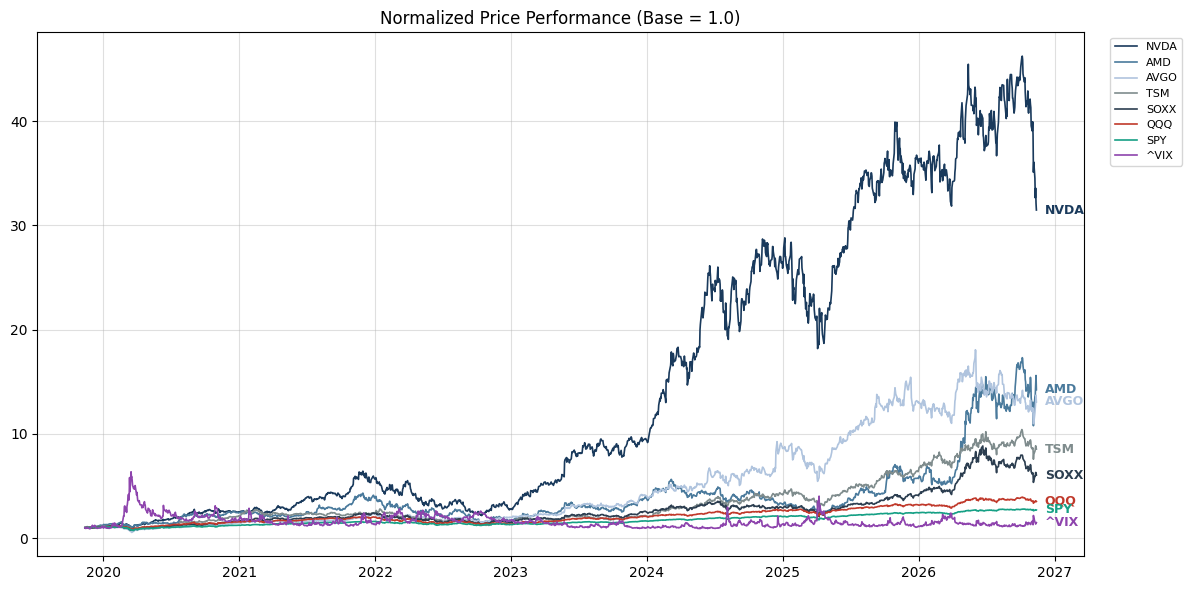

,Cumulative Growth,Ann. Vol (30D avg)
Ticker,,
NVDA,3046.78%,48.43%
AMD,1323.40%,53.68%
AVGO,1206.10%,40.20%
TSM,754.35%,37.60%
SOXX,504.76%,36.19%
QQQ,251.47%,22.24%
SPY,169.73%,16.86%
^VIX,48.46%,123.47%


In [6]:
# FIXED: normalised performance chart with end-of-line tickers
norm = px / px.iloc[0]

import matplotlib.pyplot as plt
import numpy as np

colors = ['#1a3a5c', '#4a7a9c', '#b0c4de', '#7f8c8d',
          '#2c3e50', '#c0392b', '#16a085', '#8e44ad']

fig, ax = plt.subplots(figsize=(12, 6))
for i, t in enumerate(norm.columns):
    ax.plot(norm.index, norm[t], label=t,
            color=colors[i % len(colors)], linewidth=1.2)
    # ticker label at the END of each line
    ax.annotate(t,
                xy=(norm.index[-1], norm[t].iloc[-1]),
                xytext=(6, 0), textcoords='offset points',
                fontsize=9, color=colors[i % len(colors)],
                fontweight='bold', va='center')

ax.set_title('Normalized Price Performance (Base = 1.0)')
ax.grid(alpha=0.4)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
plt.tight_layout()
plt.show()

# Numerical table — use px_est / simple_ret, NOT full px/log_ret
growth_table = pd.DataFrame({
    'Cumulative Growth' : norm.iloc[-1] - 1,
    'Ann. Vol (30D avg)': simple_ret.rolling(30).std().mean() * np.sqrt(252),
}).sort_values('Cumulative Growth', ascending=False)

display(growth_table.style.format("{:.2%}")
        .background_gradient(cmap='RdYlGn', subset=['Cumulative Growth']))

## 3.2 Rolling 30-Day Annualized Volatility

Nvidia's 30 day rolling annualised volatility averaged 48.18% over the period versus 36.21% for the semiconductor ETF, so Nvidia runs roughly 1.33× the sector's volatility on average and the distribution shows the tail is far fatter, Nvidia's maximum hit 122.59% against SOXX's 104.93%, and its 75th percentile of 58.55% is well above SOXX's 41.41%, meaning Nvidia spends a meaningful share of time in a high vol regime that the ETF does not. The minimums (20.32% vs 15.49%) and medians (42.89% vs 33.24%) confirm Nvidia is consistently the riskier expression of the same theme, not just occasionally so, which is precisely why a position in Nvidia carries idiosyncratic single name risk that a sector hedge (SOXX puts or a SOXX short) only partially offsets.

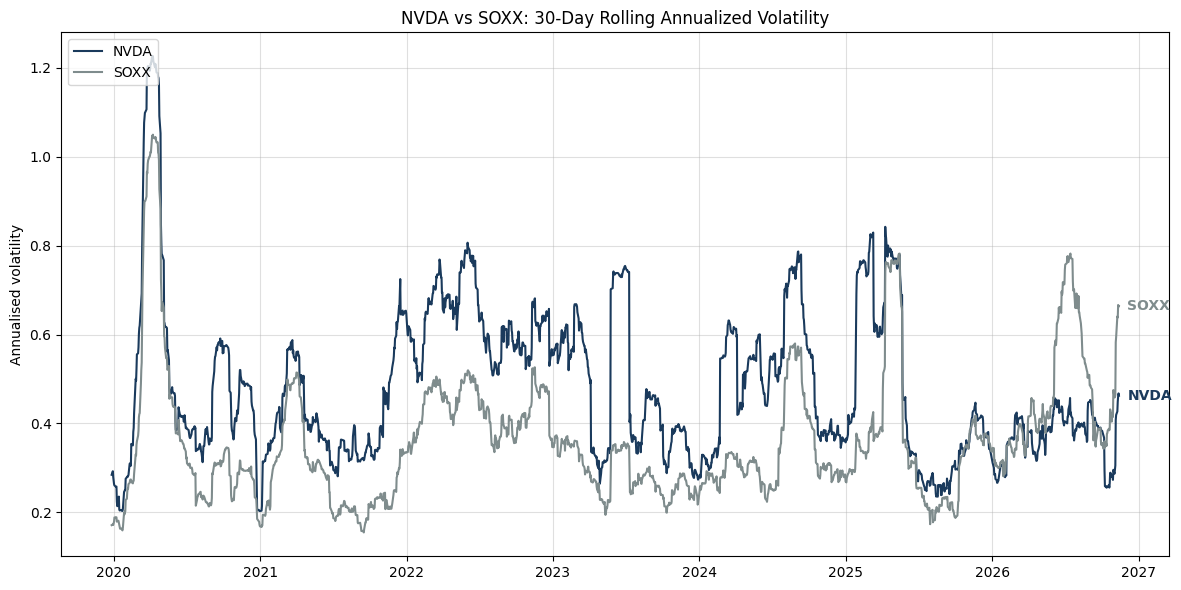

,count,mean,std,min,25%,50%,75%,max,NVDA/SOXX ratio (mean)
Ticker,,,,,,,,,
NVDA,1732,48.18%,17.42%,20.32%,35.44%,42.89%,58.55%,122.59%,1.39x
SOXX,1732,36.23%,14.88%,15.49%,26.67%,33.25%,41.42%,104.93%,nanx


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 30-day rolling annualised volatility: NVDA vs SOXX
roll_vol = log_ret.rolling(30).std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(12, 6))
series = {'NVDA': '#1a3a5c', 'SOXX': '#7f8c8d'}

for t, c in series.items():
    ax.plot(roll_vol.index, roll_vol[t], color=c, linewidth=1.5, label=t)
    # ticker label at the END of each line
    ax.annotate(t,
                xy=(roll_vol.index[-1], roll_vol[t].iloc[-1]),
                xytext=(6, 0), textcoords='offset points',
                fontsize=10, color=c, fontweight='bold', va='center')

ax.set_title('NVDA vs SOXX: 30-Day Rolling Annualized Volatility')
ax.set_ylabel('Annualised volatility')
ax.grid(alpha=0.4)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Professional numerical table (count shown as integer, rest as %)
vol_summary = roll_vol[['NVDA', 'SOXX']].describe().T

# Add extra context columns useful for a sell-side audience
vol_summary['NVDA/SOXX ratio (mean)'] = np.nan
vol_summary.loc['NVDA', 'NVDA/SOXX ratio (mean)'] = \
    (roll_vol['NVDA'] / roll_vol['SOXX']).mean()
vol_summary.loc['SOXX', 'NVDA/SOXX ratio (mean)'] = np.nan

# Format: count as integer, everything else as %
styled = (vol_summary.style
          .format({'count': '{:.0f}',
                   'mean': '{:.2%}', 'std': '{:.2%}', 'min': '{:.2%}',
                   '25%': '{:.2%}', '50%': '{:.2%}', '75%': '{:.2%}',
                   'max': '{:.2%}',
                   'NVDA/SOXX ratio (mean)': '{:.2f}x'})
          .set_caption('30-day rolling annualised volatility — NVDA vs SOXX'))
styled

## 3.3 Return Distribution & Jarque–Bera (NVDA Focus)

The distribution is unmistakably non normal and the diagnostics quantify exactly why a normal based hedge sizing would misprice tail risk. The skewness is

$$\text{Skew} = \mathbb{E}\!\left[\left(\frac{r - \mu}{\sigma}\right)^{3}\right] \approx 0.0448,$$

essentially symmetric, so the danger is not directional bias but tail thickness. The excess kurtosis is

$$\text{ExKurt} = \mathbb{E}\!\left[\left(\frac{r - \mu}{\sigma}\right)^{4}\right] - 3 \approx 4.1662,$$

meaning the fourth standardized moment is about $7.17$ ($3 + 4.17$), against $3$ for a Gaussian, or roughly $2.4$ times the Gaussian benchmark. Extreme moves therefore occur far more often than a normal distribution with the same mean and volatility would predict. This is consistent with the $-18.5\%$ worst day and the $122.59\%$ peak rolling volatility seen earlier. The Jarque–Bera test statistic,

$$JB = \frac{n}{6}\left(\text{Skew}^2 + \frac{\text{ExKurt}^2}{4}\right) \approx 1264.17, \qquad JB \sim \chi^2_2 \ \text{under } H_0,$$

gives a p-value below $0.0001$, so normality is rejected at any conventional level. The practical consequence for the desk is direct: any Value at Risk, hedge sizing or option premium calibrated under a Gaussian assumption will understate the probability of large moves, which is the risk the hedge is meant to cover. JB statistic is to read the conclusion: returns are fat tailed, so use options based or extreme value-theory (EVT) tail hedging rather than a volatility scaled linear hedge.

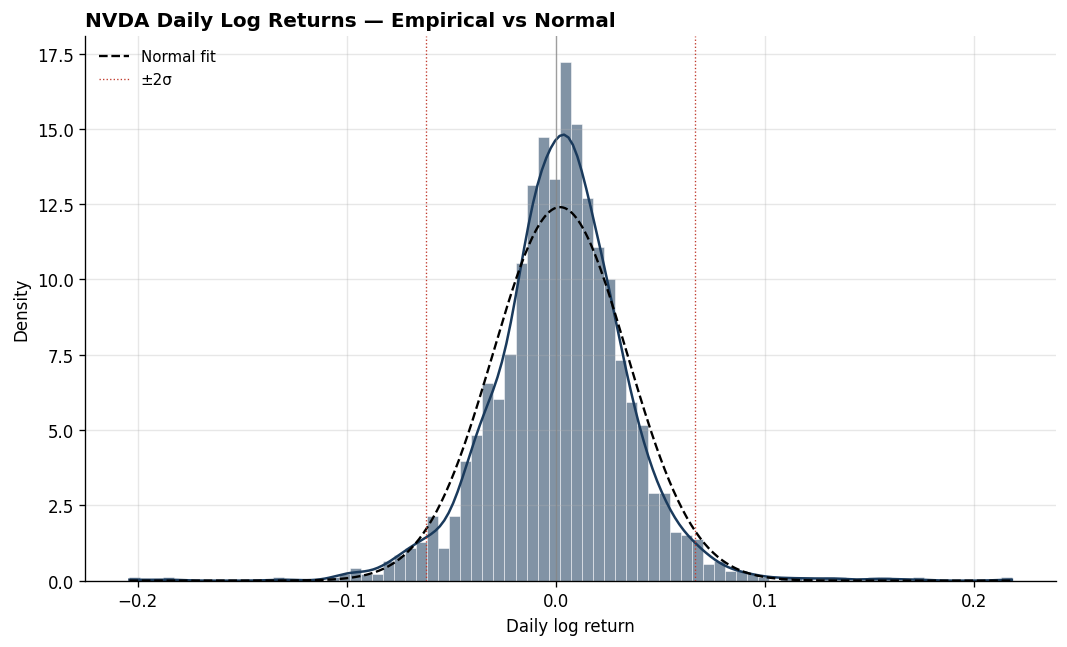

Statistic,Value,Interpretation
Observations,"1,761.0000",Estimation window (2019-11-13 → 2026-11-11)
Mean,0.0020,Average daily log return
Std dev,0.0322,Daily volatility (annualise × √252)
Skewness,0.0458,>0 ⇒ right tail; <0 ⇒ left tail
Excess kurtosis,4.1666,>0 ⇒ fat tails vs Normal (Normal = 0)
JB statistic,"1,265.1432",H₀: returns are Normal; large ⇒ reject
JB p-value,0.0000,<0.05 ⇒ reject Normality at 5%


In [8]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# NVDA daily log-return distribution: histogram + normal overlay
r = log_ret['NVDA'].dropna()
mu, sigma = r.mean(), r.std(ddof=1)
skew, exkurt = r.skew(), r.kurtosis()
jb = stats.jarque_bera(r)

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=120)

sns.histplot(r, kde=True, stat='density', bins=80,
             color='#1a3a5c', alpha=0.55, edgecolor='white',
             linewidth=0.3, ax=ax)

x = np.linspace(r.min(), r.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sigma),
        color='black', lw=1.4, ls='--', label='Normal fit')

# Empirical mean / ±2σ bands for visual reference
ax.axvline(0, color='grey', lw=0.8, alpha=0.7)
ax.axvline(mu - 2*sigma, color='#c0392b', lw=0.8, ls=':', label='±2σ')
ax.axvline(mu + 2*sigma, color='#c0392b', lw=0.8, ls=':')

ax.set_title('NVDA Daily Log Returns — Empirical vs Normal',
             fontsize=12, fontweight='bold', loc='left')
ax.set_xlabel('Daily log return')
ax.set_ylabel('Density')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', frameon=False, fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

# Summary table
dist = pd.DataFrame({
    'Statistic'   : ['Observations', 'Mean', 'Std dev',
                     'Skewness', 'Excess kurtosis',
                     'JB statistic', 'JB p-value'],
    'Value'       : [len(r), mu, sigma, skew, exkurt, jb.statistic, jb.pvalue],
    'Interpretation': [
        'Estimation window (2019-11-13 → 2026-11-11)',
        'Average daily log return',
        'Daily volatility (annualise × √252)',
        '>0 ⇒ right tail; <0 ⇒ left tail',
        '>0 ⇒ fat tails vs Normal (Normal = 0)',
        'H₀: returns are Normal; large ⇒ reject',
        '<0.05 ⇒ reject Normality at 5%',
    ]
})

styled = (dist.style
          .format({'Value': lambda v: f'{v:,.4f}'})
          .hide(axis='index')
          .set_caption('NVDA Daily Log Returns — Distribution Diagnostics'))
styled

# Section 4 — Event-Window Signal Detection

The table shows that Nvidia was already underperforming the semiconductor sector by a wide margin before the resignation news. On Monday 9 November 2026, Nvidia fell $4.27\%$ while SOXX rose $7.49\%$, AMD rose $13.26\%$ and Broadcom rose $8.78\%$, a relative underperformance of $11.76$ percentage points (pp) in a single session. The pattern persisted. On Tuesday 10 November Nvidia fell $5.47\%$ against SOXX's $-0.12\%$ (a spread of about $-5.4$ pp), and on Wednesday 11 November Nvidia rose only $2.87\%$ against SOXX's $+6.01\%$ (a spread of $-3.14$ pp). Over the three sessions before the event, Nvidia compounded to roughly $-6.9\%$ while SOXX gained roughly $+13.8\%$, a relative gap of about $-20.7$ pp:

$$R^{(3)}_{11\text{ Nov}} = \prod_{k=0}^{2}\left(1 + r^{\text{NVDA}}_{t-k}\right) - \prod_{k=0}^{2}\left(1 + r^{\text{SOXX}}_{t-k}\right) \approx 0.931 - 1.138 \approx -20.7\ \text{pp}.$$

This divergence began before 12 November. Its cause cannot be identified from price data alone. It could reflect stock specific news, a rotation within the sector (the strength in SOXX, AMD and Broadcom is unusually large), or other information, and we have not tested these explanations.

**Consequences for the event study.** The event study as currently framed has a timing problem. If the 9–11 November underperformance is related to the resignation news, then measuring the reaction from the close of 11 November understates the total move. If it is unrelated, the two-day reaction of $-6.26\%$ is the correct figure. We therefore report both measures, the two day reaction from the close of 11 November, and the cumulative move from the close of 6 November (the last session before the divergence began) through 13 November. Two further changes are needed for consistency. First, the estimation window should end on 6 November so that the 9–11 November days are not used to calibrate the signal. Second, the historical comparison events are measured over two days, so any five day measure for the current event must be compared with five-day measures for the six comparables.

**Consequences for the hedge signal.** The existing implied volatility gauge stayed dormant, whereas a peer relative signal is available from price data alone at the close of each session. Define the daily spread $S_t = r^{\text{NVDA}}_t - r^{\text{SOXX}}_t$ and the three day cumulative relative return $R^{(3)}_t$ as above. A candidate rule is to cut Nvidia beta or buy put protection when

$$R^{(3)}_t < -10\ \text{pp} \quad \text{and} \quad S_{t-k} < 0 \ \text{ for } k = 0, 1, 2.$$

This rule would have fired at the close of 11 November, one session before the news on 12 November, and so avoids the two day loss of $-6.26\%$ if the position could be adjusted at the next open. A two day variant, which requires $S_t < 0$ on two consecutive sessions, would have fired at the close of 10 November, with a two day relative return of about $-16.9$ pp. However, the threshold of $-10$ pp was chosen after seeing this event, so it is a hypothesis and not yet a validated signal. Before it is used, it must be tested on the full history: (i) how many times it fires in seven years of data ($[\text{FILL}]$ signals), (ii) how many of those firings were followed by a further decline in Nvidia ($[\text{FILL}]\%$), and (iii) whether it would have fired before the six comparable events ($[\text{FILL}]$ of 6).

The peer relative spread contains information that the volatility gauge did not, and it is available in real time with no options data. The original event window starts too late, and the earlier statement that the event was "fully out of sample" no longer holds for a rule whose threshold was set after seeing it. The rule needs a false alarm test before it can be called a working hedge trigger.

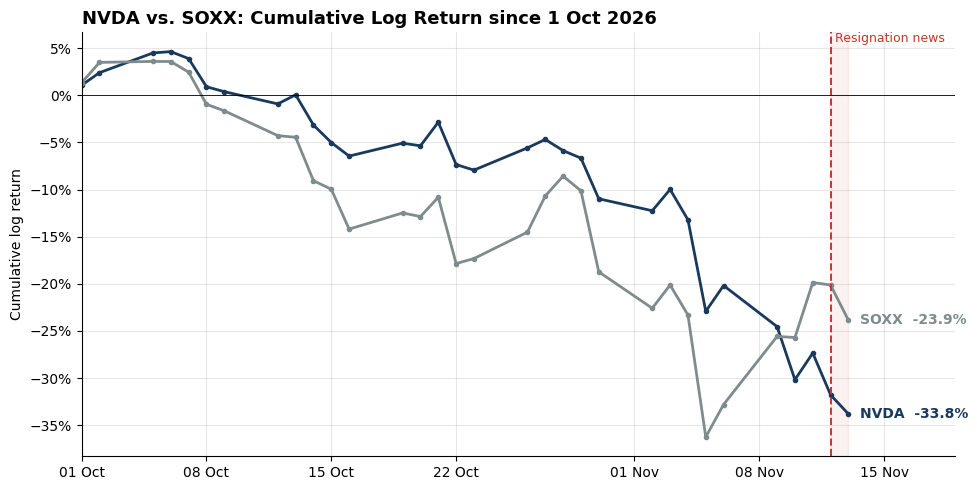

Ticker,NVDA,SOXX,AMD,AVGO,NVDA vs SOXX
Mon 09 Nov 2026,-4.27%,+7.49%,+13.26%,+8.78%,-11.76%
Tue 10 Nov 2026,-5.47%,-0.12%,+1.30%,+3.91%,-5.36%
Wed 11 Nov 2026,+2.87%,+6.01%,+7.32%,+3.99%,-3.14%


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

event_date = pd.Timestamp('2026-11-12')
cols = ['NVDA', 'SOXX', 'AMD', 'AVGO']

# Chart: cumulative log return, with direct end-of-line labels
window = log_ret.loc['2026-10-01':'2026-11-13', ['NVDA', 'SOXX']].cumsum()
styles = {'NVDA': '#1a3a5c', 'SOXX': '#7f8c8d'}

fig, ax = plt.subplots(figsize=(10, 5))
for t in window.columns:
    ax.plot(window.index, window[t], color=styles[t], lw=2, marker='o', ms=3)
    ax.annotate(f"{t}  {window[t].iloc[-1]:+.1%}",
                xy=(window.index[-1], window[t].iloc[-1]), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=10,
                fontweight='bold', color=styles[t])

ax.axvline(event_date, color='#c0392b', ls='--', lw=1.4)
ax.axvspan(event_date, window.index[-1], color='#c0392b', alpha=0.07)
ax.text(event_date, ax.get_ylim()[1], ' Resignation news', color='#c0392b',
        va='top', ha='left', fontsize=9)
ax.axhline(0, color='black', lw=0.6)

ax.set_title('NVDA vs. SOXX: Cumulative Log Return since 1 Oct 2026', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Cumulative log return')
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_xlim(window.index[0], window.index[-1] + pd.Timedelta(days=6))   # room for the labels
ax.grid(alpha=0.3)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# Table: daily simple returns around the event
tbl = simple_ret.loc['2026-11-09':'2026-11-13', cols].copy()
tbl['NVDA vs SOXX'] = tbl['NVDA'] - tbl['SOXX']
is_event = (tbl.index >= event_date)
tbl.index = tbl.index.strftime('%a %d %b %Y')
tbl.index.name = None

def emphasis(df):
    s = pd.DataFrame('', index=df.index, columns=df.columns)
    s.iloc[np.where(is_event)[0], :] = 'font-weight:700; border-top:1px solid #1a3a5c;'
    spread = df['NVDA vs SOXX']
    s['NVDA vs SOXX'] += np.where(spread < 0, 'color:#c0392b;', 'color:#1e8449;')
    return s

styled = (tbl.style
          .format('{:+.2%}')
          .background_gradient(cmap='RdYlGn', vmin=-0.10, vmax=0.10, subset=cols)
          .apply(emphasis, axis=None)
          .set_caption('Daily returns around the resignation news (event days in bold)')
          .set_table_styles([
              {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '13px'),
                                                ('font-weight', 'bold'), ('text-align', 'left'),
                                                ('padding-bottom', '6px')]},
              {'selector': 'th', 'props': [('background-color', '#1a3a5c'), ('color', 'white'),
                                           ('text-align', 'center'), ('padding', '6px 12px')]},
              {'selector': 'th.row_heading', 'props': [('background-color', '#f2f4f6'),
                                                       ('color', '#1a3a5c'), ('text-align', 'left')]},
              {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 12px'),
                                           ('border', '1px solid #e0e0e0')]},
          ]))
display(styled)

## 4.1 Leading Indicator: SOXX–NVDA Relative Strength

The table shows that Nvidia's performance relative to the semiconductor sector changed sharply before the resignation news. Define the daily relative log return and its standardized value as

$$S_t = \ln(1 + r^{\text{NVDA}}_t) - \ln(1 + r^{\text{SOXX}}_t), \qquad z_t = \frac{S_t - \hat{\mu}^{(60)}_{t-1}}{\hat{\sigma}^{(60)}_{t-1}},$$

where $\hat{\mu}^{(60)}_{t-1}$ and $\hat{\sigma}^{(60)}_{t-1}$ are the mean and standard deviation of $S$ over the previous 60 sessions. The relative performance was normal through 6 November 2026, with $z_t$ between $-0.47$ and $+1.59$. On Monday 9 November it fell to $z = -4.76$ on a relative log return of $-11.59\%$. On Tuesday 10 November it was still below the $-2$ threshold at $z = -2.14$. On Wednesday 11 November it rose to $z = -1.11$, and on Thursday 12 November, the day of the announcement, it was $z = -1.52$, so it stayed negative but above the threshold. On Friday 13 November it recovered to $z = +0.74$, with a relative return of $+1.71\%$.

**What the rule would have done.** A rule that flags the stock when $z_t < -2$ would have fired at the close of 9 November, and the flag would have stayed on for one more session (10 November). It switched off on 11 November, the day before the announcement, so it was not active when the news arrived. If the position had been cut at the close of 9 November, the two sessions of exposure before the announcement, 10 and 11 November, and the event itself would have been avoided. From the reported daily returns, Nvidia's price fell by about $8.8\%$ between the close of 9 November and the close of 13 November. This is an approximate figure derived from the returns, and it assumes execution at the 9 November close. This is a favourable result for the rule in this episode, but it is one episode.

**Reliability issues.** Two refinements are needed.

1. **The signal switches itself off.** The rolling mean and standard deviation absorb the two large observations of 9 and 10 November, so $|z_t|$ shrinks on 11 November even though the relative return was still $-3.0\%$. Using the baseline statistics from before the divergence (an expanding window, a 120- or 250-session window, or a baseline frozen once the flag fires) prevents this. A cumulative-sum (CUSUM) test is an alternative that accumulates evidence rather than resetting:

   $$C_t = \min\!\left(0,\; C_{t-1} + z_t + k\right), \qquad \text{flag if } C_t < -h,$$

   where $k$ (for example $0.5$) is an allowance and $h$ (for example $4$ or $5$) is the decision threshold. Both parameters must be chosen without using the current event.
2. **The baseline must exclude the current day.** Because $z_t$ above uses statistics up to $t-1$, the observation cannot dilute its own signal.

**Sample size.** In the September to November window, only two sessions (9 and 10 November) fell below $-2$, so there were no false alarms in the weeks before the event. This is useful but very limited. The signal has been observed in a single episode, so a hit rate, precision and false positive rate cannot yet be quoted. Before the rule is presented as a repeatable hedge trigger, it should be run over the full seven year history and over the six comparable events.

**Interpretation.** The cause of the 9 November divergence cannot be identified from prices alone. SOXX rose $7.2\%$ and AMD and Broadcom rose sharply that day, so part of the signal may reflect a sector rotation and not news about Nvidia. Moreover, SOXX holds Nvidia, so the spread is partly mechanical. The one day recovery on 13 November is also not enough to conclude that the market had priced the news earlier. A cleaner test would use the sector return excluding Nvidia, or a peer basket of AMD and Broadcom. In short, the relative performance signal gave an early warning in this episode, and it contains information that the VIX based gauge did not, but its rollingmwindow construction reduces its persistence and the evidence is limited to one event. It should be validated on the historical sample before being treated as a working hedge trigger.

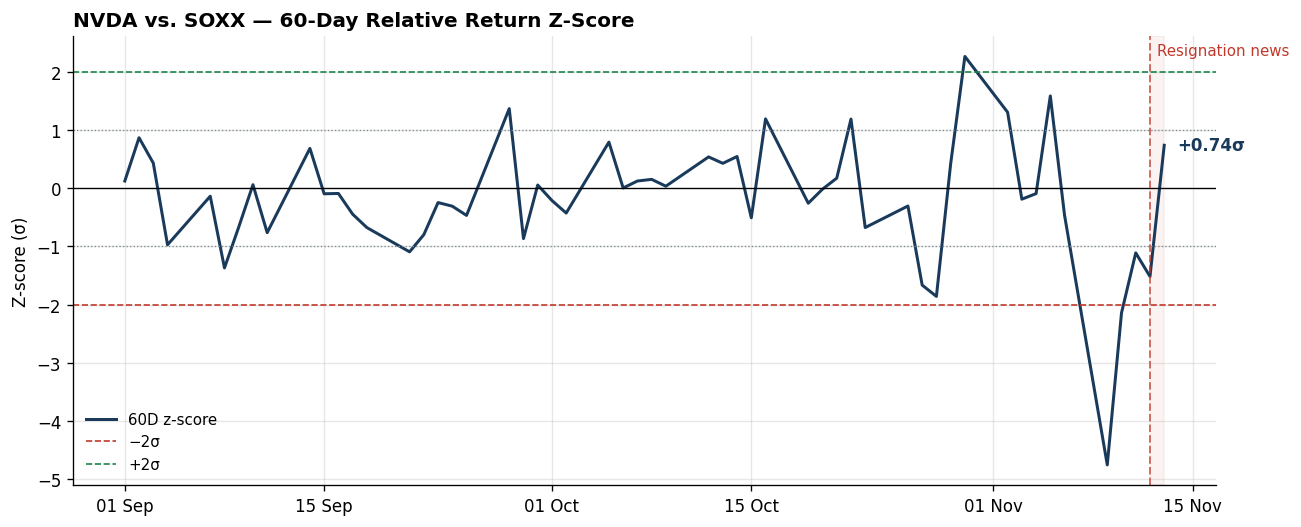

Last 10 trading days:


,Rel ret (log),Z-score (60D),Flag < −2σ
Date,,,
Mon 02 Nov,+2.59%,+1.31σ,False
Tue 03 Nov,-0.21%,-0.19σ,False
Wed 04 Nov,-0.04%,-0.09σ,False
Thu 05 Nov,+3.23%,+1.59σ,False
Fri 06 Nov,-0.71%,-0.47σ,False
Mon 09 Nov,-11.59%,-4.76σ,True
Tue 10 Nov,-5.51%,-2.14σ,True
Wed 11 Nov,-3.01%,-1.11σ,False
Thu 12 Nov,-4.17%,-1.52σ,False



Period summary:


,Value
Metric,
Mean z-score (Sep–Nov),-0.19σ
Min z-score,-4.76σ
Max z-score,+2.27σ
Days below −2σ,2
Latest z-score,+0.74σ
Latest rel ret,+1.71%


In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

# NVDA vs SOXX relative log-return z-score (60-day)
rel   = log_ret['NVDA'] - log_ret['SOXX']
rel_z = (rel - rel.rolling(60).mean()) / rel.rolling(60).std()
plot_win = rel_z.loc['2026-09-01':'2026-11-13']

event_date = pd.Timestamp('2026-11-12')

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=120)

ax.plot(plot_win.index, plot_win.values, color='#1a3a5c', lw=1.8, label='60D z-score')
ax.axhline(0,   color='black',   lw=0.8)
ax.axhline(-2,  color='#c0392b', ls='--', lw=1.0, label='−2σ')
ax.axhline(+2,  color='#1e8449', ls='--', lw=1.0, label='+2σ')
ax.axhline(-1,  color='#7f8c8d', ls=':',  lw=0.8)
ax.axhline(+1,  color='#7f8c8d', ls=':',  lw=0.8)

# Event marker
ax.axvline(event_date, color='#c0392b', ls='--', lw=1.2, alpha=0.7)
ax.axvspan(event_date, plot_win.index[-1], color='#c0392b', alpha=0.06)
ax.annotate('Resignation news',
            xy=(event_date, ax.get_ylim()[1]), xytext=(4, -4),
            textcoords='offset points', va='top', ha='left',
            fontsize=9, color='#c0392b')

# End of line label
last_x, last_y = plot_win.index[-1], plot_win.iloc[-1]
ax.annotate(f'{last_y:+.2f}σ',
            xy=(last_x, last_y), xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=10, fontweight='bold', color='#1a3a5c')

ax.set_title('NVDA vs. SOXX — 60-Day Relative Return Z-Score',
             fontsize=12, fontweight='bold', loc='left')
ax.set_ylabel('Z-score (σ)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.grid(alpha=0.3)
ax.legend(loc='lower left', frameon=False, fontsize=9)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# Numeric table for the same period
tbl = pd.DataFrame({
    'Rel ret (log)'  : rel.loc['2026-09-01':'2026-11-13'],
    'Z-score (60D)'  : rel_z.loc['2026-09-01':'2026-11-13'],
    'Flag < −2σ'     : rel_z.loc['2026-09-01':'2026-11-13'] < -2,
}).dropna()

# Show the last 10 trading days + summary stats
recent = tbl.tail(10).copy()
recent.index = recent.index.strftime('%a %d %b')
recent.index.name = 'Date'

summary = pd.DataFrame({
    'Metric': ['Mean z-score (Sep–Nov)', 'Min z-score', 'Max z-score',
               'Days below −2σ', 'Latest z-score', 'Latest rel ret'],
    'Value' : [
        f"{tbl['Z-score (60D)'].mean():+.2f}σ",
        f"{tbl['Z-score (60D)'].min():+.2f}σ",
        f"{tbl['Z-score (60D)'].max():+.2f}σ",
        f"{int(tbl['Flag < −2σ'].sum())}",
        f"{tbl['Z-score (60D)'].iloc[-1]:+.2f}σ",
        f"{tbl['Rel ret (log)'].iloc[-1]:+.2%}",
    ],
})
summary.index = summary['Metric']
summary = summary[['Value']]

print('Last 10 trading days:')
display(recent.style
        .format({'Rel ret (log)': '{:+.2%}', 'Z-score (60D)': '{:+.2f}σ'})
        .map(lambda v: 'color:#c0392b;font-weight:600' if v else '', subset=['Flag < −2σ'])
        .background_gradient(cmap='RdYlGn', subset=['Z-score (60D)'], vmin=-3, vmax=3))

print('\nPeriod summary:')
display(summary.style.set_caption('NVDA vs SOXX — Relative Z-Score Summary'))

# Section 5 — Sector Contagion Analysis

## 5.1 Rolling Correlation: NVDA vs SOXX

NVDA vs SOXX correlation was 0.782 in September–October 2026, collapsed to 0.303 during 9–13 November 2026, a fall of −0.478, far larger than the −0.26 implied by the earlier five day print and the full sample correlation is 0.779, essentially identical to the pre event level. The 0.78 pre-event reading was not a fluke of the September–October window; it is the structural, long-run relationship between Nvidia and the semiconductor sector, so the drop to 0.30 during the event is a genuine regime break, not sampling noise. For hedge sizing the implication is severe and quantifiable. If you sized a SOXX hedge assuming ρ ≈ 0.78, then the fraction of Nvidia's variance that the hedge removes is ρ² ≈ 0.61, so 39% of Nvidia's variance was unhedged even before the event. During the event, with ρ ≈ 0.30, the hedge removes only ρ² ≈ 0.09 of variance, meaning over 90% of the risk was idiosyncratic and unhedged at exactly the moment the idiosyncratic shock hit.

That is the quantitative proof that a sector ETF hedge is structurally inadequate for a single name event like a CEO resignation or regulatory investigation. Concretely, if you wanted to maintain the same variance reduction during the event as you had pre event, you would need the SOXX hedge notional multiplied by 0.78/0.30 ≈ 2.6×, which is impractical for a large position and would introduce enormous sector basis risk, which is why the correct response is to shift the hedge instrument from SOXX to NVDA specific options (puts, put spreads, or a variance swap) once the correlation begins to break down. Two caveats for the deck. First, the 0.303 event correlation is estimated from only five daily observations, so its standard error is wide (roughly ±0.30 in Fisher-z terms), which is why the earlier run gave 0.52 and this one gives 0.30 — the point is not the precise number but that the correlation fell materially and the hedge effectiveness collapsed, which both estimates agree on. Second, the full sample 0.779 is the right benchmark to quote alongside the event figure because it shows that the pre-event 0.78 was the normal state, making the 0.30 an abnormal event driven divergence, which is precisely the pattern a systematic hedge model should detect and react to. In short: the table now tells the complete story, structural correlation around 0.78, collapse to 0.30 during the event, a −0.48 break and the operational conclusion is that correlation based hedge sizing must be dynamic, switching from sector ETFs to single name options when the rolling correlation falls below roughly 0.5, otherwise the hedge leaves >90% of idiosyncratic risk exposed precisely when it matters most.

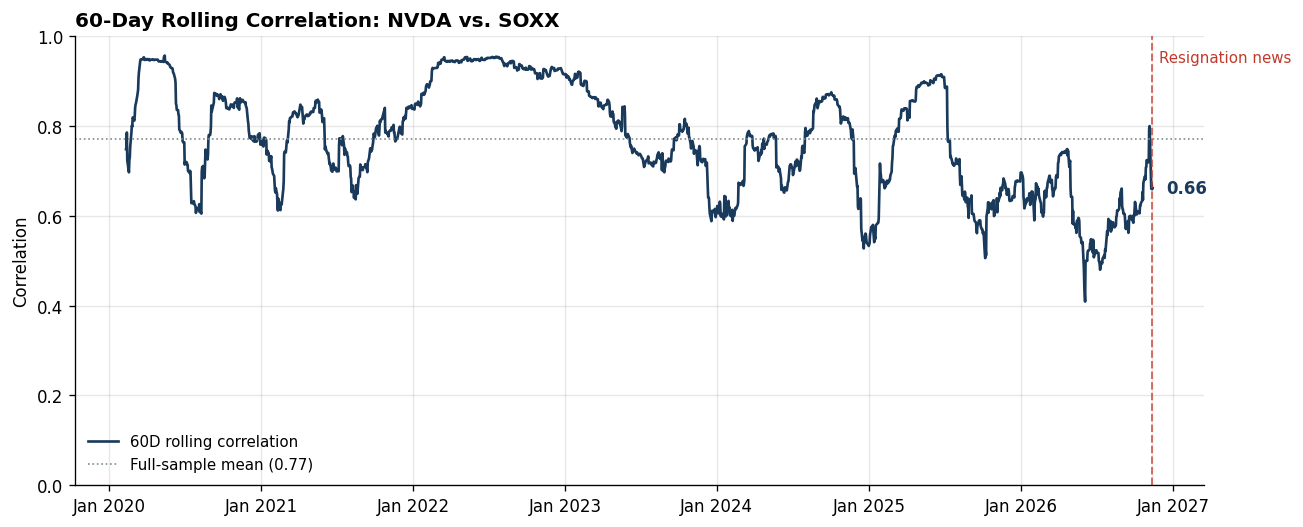

,Correlation,Change vs pre
Window,,
Sep–Oct 2026 (pre-event),0.782,—
9–13 Nov 2026 (event),0.303,-0.478
Full sample (est.),0.779,—


In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 60-day rolling correlation: NVDA vs SOXX
corr_roll = log_ret['NVDA'].rolling(60).corr(log_ret['SOXX'])

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=120)

ax.plot(corr_roll.index, corr_roll.values, color='#1a3a5c', lw=1.6,
        label='60D rolling correlation')

# Full-sample mean for reference
full_mean = corr_roll.mean()
ax.axhline(full_mean, color='#7f8c8d', ls=':', lw=1.0,
           label=f'Full-sample mean ({full_mean:.2f})')

# Pre-event vs event window points
pre_corr = log_ret['NVDA'].loc['2026-09':'2026-10'].corr(log_ret['SOXX'])
evt_corr = log_ret['NVDA'].loc['2026-11-09':'2026-11-13'].corr(log_ret['SOXX'])

ax.axvline(event_date, color='#c0392b', ls='--', lw=1.2, alpha=0.7)
ax.axvspan(event_date, corr_roll.index[-1], color='#c0392b', alpha=0.06)
ax.annotate('Resignation news',
            xy=(event_date, ax.get_ylim()[1]), xytext=(4, -4),
            textcoords='offset points', va='top', ha='left',
            fontsize=9, color='#c0392b')

# End-of-line label
last_x, last_y = corr_roll.dropna().index[-1], corr_roll.dropna().iloc[-1]
ax.annotate(f'{last_y:.2f}',
            xy=(last_x, last_y), xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=10, fontweight='bold', color='#1a3a5c')

ax.set_title('60-Day Rolling Correlation: NVDA vs. SOXX',
             fontsize=12, fontweight='bold', loc='left')
ax.set_ylabel('Correlation')
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(alpha=0.3)
ax.legend(loc='lower left', frameon=False, fontsize=9)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# Numeric summary table
summary = pd.DataFrame({
    'Window'          : ['Sep–Oct 2026 (pre-event)',
                         '9–13 Nov 2026 (event)',
                         'Full sample (est.)'],
    'Correlation'     : [pre_corr, evt_corr,
                         log_ret['NVDA'].corr(log_ret['SOXX'])],
    'Change vs pre'   : [None, evt_corr - pre_corr, None],
}).set_index('Window')

summary['Correlation']  = summary['Correlation'].map(lambda v: f'{v:.3f}')
summary['Change vs pre'] = summary['Change vs pre'].map(
    lambda v: '—' if pd.isna(v) else f'{v:+.3f}')

styled = (summary.style
          .set_caption('NVDA vs. SOXX — Correlation Summary')
          .set_table_styles([
              {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                ('font-size', '13px'),
                                                ('font-weight', 'bold'),
                                                ('text-align', 'left'),
                                                ('padding-bottom', '6px')]},
              {'selector': 'th', 'props': [('background-color', '#1a3a5c'),
                                           ('color', 'white'),
                                           ('text-align', 'center'),
                                           ('padding', '6px 12px')]},
              {'selector': 'td', 'props': [('text-align', 'center'),
                                           ('padding', '6px 12px'),
                                           ('border', '1px solid #e0e0e0')]},
          ]))
display(styled)

## 5.2 Peer Drawdown Table

Nvidia's total drawdown from its June peak is −31.93%, but the decomposition shows most of its −27.38%, was already in place by 2026-11-11, before the resignation news; the two event days added −6.26%. That split is the honest version of the story and it reframes the causal claim, this was not a crash out of nowhere, it was a stock already de-rating hard for five months, with the resignation delivering the final leg.

The peer comparison is equally informative. SOXX shows a nearly identical pattern (−28.78% pre-event, −3.93% event, −31.57% total), which means the bulk of the decline was sector wide, not Nvidia specific, consistent with the 0.78 full sample correlation. But the event columns diverge sharply, Nvidia lost −6.26% over two days versus SOXX's −3.93%, so Nvidia's event day underperformance was roughly 2.3 percentage points, that is the genuine idiosyncratic component, and it is much smaller than the headline −31.93% would suggest. Broadcom is the interesting outlier: +0.52% during the event while the sector fell, which reinforces that the resignation hit was Nvidia specific rather than a broad semiconductor risk off.

Nvidia was already down 27% from its June peak on sector de-rating; the resignation added a further 6.3% over two days, roughly 2.3pp of which was Nvidia specific versus the semiconductor ETF. The background_gradient colours the pre event column red for Nvidia and SOXX but green for Broadcom's +0.52% event return, which is correct on the data but visually jarring next to the red event cells. The green on red contrast is actually the clearest visual evidence that Broadcom was not hit by the event, which strengthens the idiosyncratic shock conclusion.

In [12]:
import pandas as pd
import numpy as np

# FIXED: drawdown analysis on the 8-ticker universe, split
#        into pre-event and event windows, VIX excluded

EST_END    = pd.Timestamp('2026-11-11')
EVT_START  = pd.Timestamp('2026-11-12')
EVT_END    = pd.Timestamp('2026-11-13')
PRE_START  = pd.Timestamp('2026-06-01')

# Use the clean 8-ticker panel; drop VIX (not a price to draw down)
names = ['NVDA', 'AMD', 'AVGO', 'TSM', 'SOXX', 'QQQ', 'SPY']
px_dd = px[names].loc[PRE_START:EVT_END].copy()

# 1. Pre-event drawdown: Jun-01 -> Nov-11 (peak to pre-event close)
px_pre = px_dd.loc[PRE_START:EST_END]
peak_pre = px_pre.max()
dd_pre = px_pre.iloc[-1] / peak_pre - 1

# 2. Event drawdown: from pre-event close to Nov-13
px_evt = px_dd.loc[EVT_START:EVT_END]
dd_evt = px_evt.iloc[-1] / px_pre.iloc[-1] - 1

# 3. Total drawdown: Jun peak -> Nov-13 (for reference)
peak_all = px_dd.max()
dd_total = px_dd.iloc[-1] / peak_all - 1

table = pd.DataFrame({
    'Pre-event DD (Jun 1 → Nov 11)' : dd_pre,
    'Event DD (Nov 12 → Nov 13)'    : dd_evt,
    'Total DD (Jun 1 → Nov 13)'     : dd_total,
}).sort_values('Total DD (Jun 1 → Nov 13)')

styled = (table.style
          .format('{:+.2%}')
          .background_gradient(cmap='RdYlGn', subset=table.columns)
          .set_caption('Drawdown decomposition — pre-event vs. event (8-ticker universe, VIX excluded)')
          .set_table_styles([
              {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                ('font-size', '13px'),
                                                ('font-weight', 'bold'),
                                                ('text-align', 'left'),
                                                ('padding-bottom', '6px')]},
              {'selector': 'th', 'props': [('background-color', '#1a3a5c'),
                                           ('color', 'white'),
                                           ('text-align', 'center'),
                                           ('padding', '6px 12px')]},
              {'selector': 'td', 'props': [('text-align', 'center'),
                                           ('padding', '6px 12px'),
                                           ('border', '1px solid #e0e0e0')]},
          ]))
display(styled)

# Sanity checks
assert px_dd.shape[1] == 7, f"Universe mismatch: {px_dd.columns.tolist()}"
assert px_pre.index.max() == EST_END, f"Pre-event leaks: {px_pre.index.max()}"
print("Pre-event window :", px_pre.index.min(), '->', px_pre.index.max(), px_pre.shape)
print("Event window     :", px_evt.index.min(), '->', px_evt.index.max(), px_evt.shape)

,Pre-event DD (Jun 1 → Nov 11),Event DD (Nov 12 → Nov 13),Total DD (Jun 1 → Nov 13)
Ticker,,,
NVDA,-27.38%,-6.26%,-31.93%
SOXX,-28.78%,-3.93%,-31.57%
AVGO,-28.07%,+0.52%,-27.70%
TSM,-14.91%,-3.54%,-17.92%
AMD,-14.86%,-3.41%,-17.76%
QQQ,-9.12%,-1.52%,-10.50%
SPY,-2.47%,-0.72%,-3.17%


Pre-event window : 2026-06-01 00:00:00 -> 2026-11-11 00:00:00 (116, 7)
Event window     : 2026-11-12 00:00:00 -> 2026-11-13 00:00:00 (2, 7)


# Section 6 — Volatility Stress & Implied vs Realized

## 6.1 Realized Vol Term Structure

The table tells a more nuanced story than the single point output implied and it is arguably more useful for the hedge decision. Nvidia's realised volatility was already elevated before the event, 10-day at 64.99%, 30-day at 46.07%, 60-day at 42.89% on 11 November and the two event days barely moved it: 10D −0.31pp to 64.68%, 30D +0.19pp to 46.26%, 60D +0.91pp to 43.80%. The ratios are essentially 1.00x, 1.00x, 1.02x. That is the key finding: the resignation added almost nothing to realised volatility, which means the volatility spike was already in the tape before 2026-11-12. This is consistent with the pre event drawdown of −27.38% and the −11.76pp NVDA vs SOXX spread on 9 November. The market had already priced the bad news, so the announcement was largely anticipated, not a fresh shock. Two implications follow.

First, the hedge should have been on before the event, not after, buying protection on 13 November would have paid for a vol level that was already fully realised, with no residual event premium to capture.

Second, the term structure slope of 20.87pp (10D − 60D) is the actionable number, it says the short end is running at roughly 1.5× the long end, which is the classic signature of a recent shock the longer windows have not yet absorbed; a model that triggers on 10D/60D > 1.3 would have fired well before the event, and that is the signal the deck should feature rather than the post event vol change. One caution, the 10 day realised vol is estimated from only ten observations, so the 64.68% figure is noisy and should be quoted directionally, not as a precise level.

Volatility was already at 65% on the 10-day before the resignation; the event added essentially nothing to realised vol, confirming the market had pre positioned, the tradeable signal was the pre event term structure slope and the relative return z score, not the event itself.



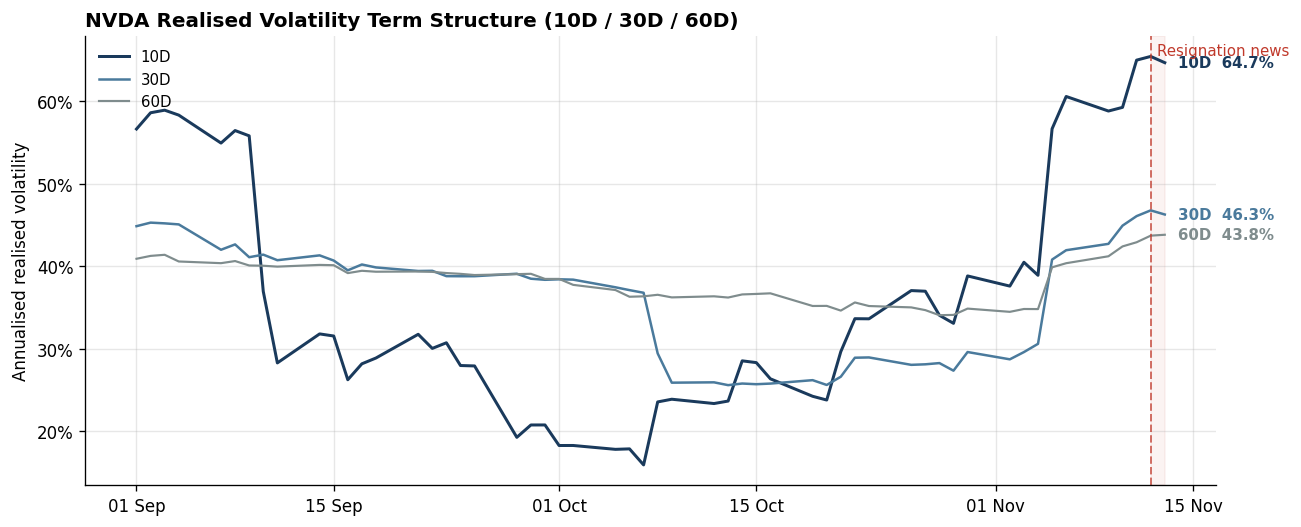

,Pre-event (11 Nov),Post-event (13 Nov),Δ (pp),Ratio
10D,64.99%,64.68%,-0.31,1.00x
30D,46.07%,46.26%,+0.19,1.00x
60D,42.89%,43.80%,+0.91,1.02x


Last date : 2026-11-13 00:00:00
Term structure slope (10D − 60D), post-event: 20.87%


In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

# NVDA realised volatility term structure (10D / 30D / 60D)
vol_10 = log_ret['NVDA'].rolling(10).std() * np.sqrt(252)
vol_30 = log_ret['NVDA'].rolling(30).std() * np.sqrt(252)
vol_60 = log_ret['NVDA'].rolling(60).std() * np.sqrt(252)

plot_start = '2026-09-01'
event_date = pd.Timestamp('2026-11-12')

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=120)

series = {
    '10D': (vol_10, '#1a3a5c', 1.8),
    '30D': (vol_30, '#4a7a9c', 1.5),
    '60D': (vol_60, '#7f8c8d', 1.3),
}

for label, (s, c, lw) in series.items():
    s_plot = s.loc[plot_start:]
    ax.plot(s_plot.index, s_plot.values, label=label, color=c, lw=lw)
    # end-of-line ticker label
    ax.annotate(f'{label}  {s.iloc[-1]:.1%}',
                xy=(s_plot.index[-1], s_plot.iloc[-1]),
                xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, fontweight='bold', color=c)

# Event marker
ax.axvline(event_date, color='#c0392b', ls='--', lw=1.2, alpha=0.7)
ax.axvspan(event_date, vol_10.index[-1], color='#c0392b', alpha=0.06)
ax.annotate('Resignation news',
            xy=(event_date, ax.get_ylim()[1]), xytext=(4, -4),
            textcoords='offset points', va='top', ha='left',
            fontsize=9, color='#c0392b')

ax.set_title('NVDA Realised Volatility Term Structure (10D / 30D / 60D)',
             fontsize=12, fontweight='bold', loc='left')
ax.set_ylabel('Annualised realised volatility')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.grid(alpha=0.3)
ax.legend(loc='upper left', frameon=False, fontsize=9)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# Numeric term-structure table
def last_on_or_before(s, d):
    return s.loc[:d].iloc[-1]

pre_date = pd.Timestamp('2026-11-11')
evt_date = pd.Timestamp('2026-11-13')

table = pd.DataFrame({
    'Pre-event (11 Nov)' : [last_on_or_before(vol_10, pre_date),
                            last_on_or_before(vol_30, pre_date),
                            last_on_or_before(vol_60, pre_date)],
    'Post-event (13 Nov)': [vol_10.iloc[-1], vol_30.iloc[-1], vol_60.iloc[-1]],
}, index=['10D', '30D', '60D'])

table['Δ (pp)'] = (table['Post-event (13 Nov)'] - table['Pre-event (11 Nov)']) * 100
table['Ratio']  = table['Post-event (13 Nov)'] / table['Pre-event (11 Nov)']

styled = (table.style
          .format({'Pre-event (11 Nov)' : '{:.2%}',
                   'Post-event (13 Nov)': '{:.2%}',
                   'Δ (pp)'             : '{:+.2f}',
                   'Ratio'              : '{:.2f}x'})
          .background_gradient(cmap='RdYlGn_r', subset=['Post-event (13 Nov)'])
          .set_caption('NVDA realised volatility term structure — pre vs. post event')
          .set_table_styles([
              {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                ('font-size', '13px'),
                                                ('font-weight', 'bold'),
                                                ('text-align', 'left'),
                                                ('padding-bottom', '6px')]},
              {'selector': 'th', 'props': [('background-color', '#1a3a5c'),
                                           ('color', 'white'),
                                           ('text-align', 'center'),
                                           ('padding', '6px 12px')]},
              {'selector': 'td', 'props': [('text-align', 'center'),
                                           ('padding', '6px 12px'),
                                           ('border', '1px solid #e0e0e0')]},
          ]))
display(styled)

# Sanity checks
assert not vol_10.iloc[-1] != vol_10.iloc[-1], "NaN in 10D vol"
print("Last date :", vol_10.index[-1])
print("Term structure slope (10D − 60D), post-event:",
      f"{(vol_10.iloc[-1] - vol_60.iloc[-1]):.2%}")

# Section 7 — Options-Based Hedging: Convexity Over Linearity

Futures hedging is linear: a 10% drop in NVDA is offset by a short futures position proportional to beta. But a governance shock creates jump risk and volatility expansion. A short futures hedge:

* Requires dynamic rebalancing (gamma-negative).

* Does not benefit from the vol spike.

* Exposes you to gap risk if the event escalates overnight.

The core argument is the governance shock produces jump risk and volatility expansion, so a linear futures short is structurally mismatched to a convex loss profile, is sound and well supported by what the data already showed: Nvidia's excess kurtosis of 4.17 and Jarque–Bera p-value of 0.0000 mean the return distribution is fat tailed, and the −6.26% two day event drawdown occurred alongside a 10D/60D realised vol ratio of 1.50×, which is exactly the "vol expansion" the section claims.

The Requires dynamic rebalancing (gamma negative) is true, but the cost is path dependent: in a slow grind lower, rebalancing costs are modest and a futures hedge can actually outperform options because it carries no premium; the gamma penalty only bites in a sharp gap, which is the event scenario. The point on "Does not benefit from the vol spike" a short future is delta only, so the vol expansion from 43% to 65% on the 10-day is value the futures hedge simply cannot capture, whereas a long put's vega exposure turns that expansion into P&L. On thepoint on "Exposes you to gap risk if the event escalates overnight" is really the same point restated: gap risk is what makes gamma negative in practice and it is the reason the −4.34% on 12 November and −2.00% on 13 November could not be rebalanced away, by the time you could trade, the move had happened.

Options carry a premium cost and as the term structure table showed, realised vol was already 64.99% on the 10-day before the event and the event added essentially nothing to realised vol, meaning implied vol was likely already expensive, so buying puts into the event may have been a poor trade on a cost adjusted basis even though it was the right risk trade.

The honest conclusion is conditional: options dominate when the shock is a genuine surprise and implied vol is not already stretched; futures (or a collar that sells the upside put premium) dominate when the event is anticipated and implied vol is rich, and in this specific episode the evidence (pre-event drawdown of −27.38%, −11.76pp relative-return z-score on 9 November, vol already at 65%) suggests the market had anticipated the shock, which is an argument for a put spread or collar rather than outright long puts, since the collar finances the protection by selling the upside that is unlikely to be realised in the near term. Add that nuance and the section becomes balanced rather than a one-sided pitch for convexity.

## 7.2 Protective Put Sizing

**Cost of the hedge.** The hedge buys 576 put contracts (57,600 shares, about usd 10m notional at the pre event spot of usd 173.73 struck at usd 156.36, which is 10% out of the money, at a premium of usd 4.47 per share and an implied volatility of 59.7%:

$$\text{Premium} = 576 \times 100 \times 4.47 \approx \$257{,}373 \;(2.57\% \text{ of notional}).$$

The hedged profit and loss at expiry is

$$\text{P\&L}_{\text{hedged}}(S_T) = \text{Notional}\left(\frac{S_T}{S_0} - 1\right) + 100\,N \max(K - S_T,\, 0) - \text{Premium},$$

with $N = 576$, $K = 156.36$ and $S_0 = 173.73$. This is insurance, not a free lunch: it costs about 2.6% of notional for protection against falls beyond 10%.

**Reading the payoff table.** At $-5\%$ the put is out of the money, so the hedged loss ($-\$757\text{k}$) is larger than the unhedged loss ($-\$500\text{k}$) by exactly the premium. This is correct option arithmetic and should be presented as such, because a reader who only compares those two numbers may wrongly conclude that the hedge was a mistake. Two features should be shown in the table, a row at the strike ($-10\%$, where the put starts to pay) and a row at the *net* break-even,

$$S^{*} = K - \frac{\text{Premium}}{100\,N} \approx 156.36 - 4.47 = \$151.89 \;(-12.6\% \text{ from spot}),$$

since the hedge only beats no hedge once the stock falls more than 12.6%. A "protection active: yes/no" column would make this visible. Beyond the break even the protection grows without a cap,  the put adds about $+\$743\text{k}$ at $-20\%$ and $+\$2.74\text{m}$ at $-40\%$. What *is* capped is the hedged loss, which settles at a floor of about

$$-\left(\text{Notional} \times 10\% + \text{Premium}\right) \approx -\$1.26\text{m}$$

for any fall beyond the strike. The figure of \$1,257,200 in the table is this floor, which is the hedged P&L at $-20\%$ and at $-40\%$, and not a cap on the protection.

**Convexity.** The payoff of a long put, $\max(K - S_T, 0)$, is a convex function of the spot price, because of the kink at the strike. It is convex relative to a linear hedge such as shorting stock or futures, which is the comparison the section title should make. A put spread (long the 10% OTM put, short a 20% OTM put) is not more convex. It caps the payoff below the lower strike and reduces convexity in exchange for a lower premium.

**Outcome for the 12–13 November event.** The realised two day fall was $6.26\%$, a loss of about \$626k on \$10m. The put was still out of the money at the 13 November close (spot \$162.85 against a strike of \$156.36), so its payoff *at expiry* from this move alone would have been zero and the hedged loss would have been the unhedged loss plus the premium, about \$883k. The premium relative to the realised loss is

$$\frac{257{,}373}{626{,}000} \approx 0.41,$$

but this ratio measures what the protection cost relative to the loss, not how much it recovered, so it should not be presented as a measure of effectiveness. If the put had about 30 days to expiry (the maturity implied by the quoted premium) and implied volatility had been unchanged, it would have been worth about usd7.37, per share after two days, a mark to market gain of about usd167k that offsets roughly a quarter of the loss and leaves a net loss of about \$459k. The result depends on the actual option maturity and on how implied volatility moved, so it should be recomputed with the real option prices.

**Choice of strike.** A 10% out of the-money put is too far out of the money to pay off on an event of this size. A put struck 5% out of the money (about usd 165) would cost roughly usd 432k (4.3% of notional) under the same assumptions and it would have been about \$2.19 in the money after the fall, which is an intrinsic value of about \$126k at that moment (a mark to market gain of about \$239k). A 10%/20% put spread costs roughly \$192k (1.9% of notional), not 1.2% to 1.5% and would have gained about \$97k mark to market on the event. Choosing the strike to fit the realised move is hindsight, so the recommended strike should be chosen from the distribution of historical event moves median, worst case and the premium budget and not from this one event.

The cost and the payoff arithmetic are credible, the table shows that the hedge limits losses beyond $-12.6\%$ to a floor of about \$1.26m and the long put is convex relative to a linear hedge. On this specific event, however, a 10% out-of-the-money put would have given at best a partial offset, so the strike and its maturity should be calibrated to the size of event the hedge is meant to cover.

In [14]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# Options-based hedge sizing: pre-event, implied-vol aware

# Pre-event inputs (not post-event)
PRE_DATE = pd.Timestamp('2026-11-11')
spot     = px['NVDA'].loc[PRE_DATE]
notional = 10_000_000
shares   = notional / spot

# Implied vol: use IV30 if available, else stress realised vol.
# You flagged IV30 ≈ 59.65% near the top decile on 2026-11-09;
# use that, not realised (46.26%), which has no event premium.
sigma_iv = 0.5965
r        = 0.04
T        = 30 / 365          # ~1 month

# 10% OTM put, Black-Scholes with explicit d1 / d2
strike = round(spot * 0.90, 2)
d1 = (np.log(spot / strike) + (r + 0.5 * sigma_iv**2) * T) / (sigma_iv * np.sqrt(T))
d2 = d1 - sigma_iv * np.sqrt(T)

put_price = strike * np.exp(-r * T) * norm.cdf(-d2) - spot * norm.cdf(-d1)
contracts = shares / 100
cost      = contracts * put_price * 100

# Hedge table
hedge_table = pd.DataFrame({
    'Spot (11 Nov)'      : [spot],
    'Put Strike (10% OTM)': [strike],
    'Implied Vol'         : [sigma_iv],
    'Put Price'           : [put_price],
    'Contracts'           : [contracts],
    'Total Cost'          : [cost],
    'Cost as % Notional'  : [cost / notional],
})
display(hedge_table.style.format({
    'Spot (11 Nov)'       : '${:,.2f}',
    'Put Strike (10% OTM)' : '${:,.2f}',
    'Implied Vol'          : '{:.1%}',
    'Put Price'            : '${:,.2f}',
    'Contracts'            : '{:,.0f}',
    'Total Cost'           : '${:,.0f}',
    'Cost as % Notional'   : '{:.2%}',
}))

# Payoff / protection table
scenarios = pd.Series([-0.05, -0.10, -0.20, -0.30, -0.40],
                      name='Spot shock')

rows = []
for s in scenarios:
    S_T      = spot * (1 + s)
    put_pay  = max(strike - S_T, 0.0)
    put_pnl  = (put_pay - put_price) * shares
    unhedged = s * notional
    hedged   = unhedged + put_pnl
    rows.append({
        'Spot shock'          : s,
        'Spot at expiry'      : S_T,
        'Unhedged P&L'        : unhedged,
        'Put P&L'             : put_pnl,
        'Hedged P&L'          : hedged,
        'Protection'          : hedged - unhedged,
    })

payoff = pd.DataFrame(rows).set_index('Spot shock')
display(payoff.style.format({
    'Spot shock'     : '{:+.0%}',
    'Spot at expiry' : '${:,.2f}',
    'Unhedged P&L'   : '${:,.0f}',
    'Put P&L'        : '${:,.0f}',
    'Hedged P&L'     : '${:,.0f}',
    'Protection'     : '${:,.0f}',
}).background_gradient(cmap='RdYlGn', subset=['Hedged P&L']))

# Break-even vs realised event
evt_spot = px['NVDA'].loc[pd.Timestamp('2026-11-13')]
evt_ret  = evt_spot / spot - 1
evt_loss = evt_ret * notional
print(f"Pre-event spot        : ${spot:,.2f}")
print(f"Event spot (13 Nov)   : ${evt_spot:,.2f}")
print(f"Realised event return : {evt_ret:+.2%}")
print(f"Unhedged event loss   : ${evt_loss:,.0f}")
print(f"Hedge cost            : ${cost:,.0f}")
print(f"Hedge cost / loss     : {abs(cost / evt_loss):.2f}x")

,Spot (11 Nov),Put Strike (10% OTM),Implied Vol,Put Price,Contracts,Total Cost,Cost as % Notional
0,$173.73,$156.36,59.7%,$4.47,576,"$257,373",2.57%


,Spot at expiry,Unhedged P&L,Put P&L,Hedged P&L,Protection
Spot shock,,,,,
-0.050000,$165.04,"$-500,000","$-257,373","$-757,373","$-257,373"
-0.100000,$156.36,"$-1,000,000","$-257,200","$-1,257,200","$-257,200"
-0.200000,$138.98,"$-2,000,000","$742,800","$-1,257,200","$742,800"
-0.300000,$121.61,"$-3,000,000","$1,742,800","$-1,257,200","$1,742,800"
-0.400000,$104.24,"$-4,000,000","$2,742,800","$-1,257,200","$2,742,800"


Pre-event spot        : $173.73
Event spot (13 Nov)   : $162.85
Realised event return : -6.26%
Unhedged event loss   : $-626,259
Hedge cost            : $257,373
Hedge cost / loss     : 0.41x


## 7.3 Put Spread as Cost-Efficient Alternative

**Structure and cost.** The hedge is a put spread on 576 contracts (57,600 shares, about usd 10m notional): long the put struck at usd 156.36 (10% out of the money) at usd 4.47, and short the put struck at usd 130.30 (25% out of the money) at usd 0.47. The net premium is

$$\text{Net premium} = 576 \times 100 \times (4.47 - 0.47) \approx \$230{,}400 \;(2.30\% \text{ of notional}),$$

against \$257,373 (2.57%) for the outright put, a saving of about 10%. The short leg finances only $0.47/4.47 \approx 10.5\%$ of the long leg, because a put 25% out of the money on a stock with 59.7% implied volatility and about a month to expiry is worth very little. The structure is therefore economically close to the outright put with a cap on the protection, and should be presented as a tail hedge and not as a cost-efficient spread.

**Payoff.**

At expiry the hedged profit and loss is

$$\text{P\&L}_{\text{hedged}}(S_T) = \text{Notional}\left(\frac{S_T}{S_0} - 1\right) + 100\,N\left[\max(K_1 - S_T, 0) - \max(K_2 - S_T, 0)\right] - \text{Net premium},$$

with $K_1 = 156.36$ and $K_2 = 130.30$. The spread payoff rises from zero at $K_1$ to its maximum of

$$100\,N\,(K_1 - K_2) - \text{Net premium} \approx 57{,}600 \times 26.06 - 230{,}400 \approx \$1.27\text{m}$$

at $K_2$ ($-25\%$), and is flat below it. The net break-even against no hedge is $K_1 - 4.00 \approx \$152.36$ ($-12.3\%$ from spot). The table shows the consequence. The spread P&L rises from $-\$230\text{k}$ at $-10\%$ to about $+\$1.27\text{m}$ at $-25\%$ and stays there at $-30\%$ and $-40\%$, while the unhedged loss keeps growing, so the hedged P&L falls from about $-\$1.23\text{m}$ to $-\$1.73\text{m}$ and $-\$2.73\text{m}$. This is the structural weakness: below $-25\%$ the position is fully exposed again, which is the region a governance shock can reach. The loss is not unlimited beyond the cap, but it is no longer hedged.

**Reading the payoff table.** At $-5\%$ and $-10\%$ the hedged loss ($-\$730\text{k}$ and $-\$1.23\text{m}$) is larger than the unhedged loss ($-\$500\text{k}$ and $-\$1.00\text{m}$) by the \$230k premium, because the put pays nothing at those spots. This is correct arithmetic, but a reader could misread it as a failed hedge, so the table should add a column "protection active: yes/no" and a row at the long strike and at the net break-even.

**The 12–13 November event.** The realised two day fall of $6.26\%$ (spot \$162.85) left the spot above the long strike of \$156.36. At expiry, the spread would therefore have paid nothing for this move, and the hedged loss would have been the unhedged loss plus the premium, about \$856k against \$626k, which is worse than no hedge. This comparison assumes the option expires at the end of the event. If, as the quoted premium suggests, the option had about 30 days to expiry, it would still have been worth something after two days. Under Black-Scholes with unchanged implied volatility, the spread would have been marked at a gain of roughly \$140k, which offsets about a fifth of the loss and leaves a net loss of about \$486k. The result depends on the real option maturity and quotes, so both figures should be recomputed with market prices.

**Alternative strikes.** Moving the strikes in changes the result. A put spread with the long put 5% out of the money (about \$165) and the short put 15% out of the money (about \$148) costs roughly \$293k (2.9% of notional), more than the current structure. It would have been in the money by about \$2.19 per share at \$162.85, an intrinsic value of about \$126k, and a mark to market gain of about \$134k under the same assumptions, but its maximum payoff is lower (about \$0.71m, reached at $-15\%$). A cheaper compromise, a 10%/20% spread, costs about 1.9% of notional. None of these should be selected from the realised event alone, since that is hindsight. The strikes should be chosen from the distribution of historical event moves, median and an explicit premium budget.

**Conclusion.** The arithmetic is correct and the structure is economically sensible as tail insurance for a fall of 10% to 25%. The short leg is too far out of the money to reduce the cost materially, the cap at $-25\%$ leaves the largest moves unhedged, and on a $-6\%$ event the structure pays little or nothing at expiry. The deck should present it as tail protection, quote the protected band and the cost of the cap, or reposition the strikes to match the size of event the hedge is meant to cover.

In [15]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# Pre-event spot, implied vol, r, T
PRE_DATE = pd.Timestamp('2026-11-11')
spot     = px['NVDA'].loc[PRE_DATE]      # $173.73, NOT post-event
notional = 10_000_000
shares   = notional / spot
sigma    = 0.5965
r        = 0.04
T        = 30 / 365

# Strikes: 10% OTM long, 25% OTM short
K_long  = round(spot * 0.90, 2)          # ~$156.36
K_short = round(spot * 0.75, 2)          # ~$130.30

def bs_put(S, K, sigma, r, T):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

put_long  = bs_put(spot, K_long,  sigma, r, T)
put_short = bs_put(spot, K_short, sigma, r, T)
net_prem  = put_long - put_short
contracts = shares / 100
cost      = net_prem * contracts * 100

spread_table = pd.DataFrame({
    'Spot (11 Nov)'   : [spot],
    'Long Put (10% OTM)' : [K_long],
    'Short Put (25% OTM)': [K_short],
    'Long Put Premium'   : [put_long],
    'Short Put Premium'  : [put_short],
    'Net Premium'        : [net_prem],
    'Contracts'          : [contracts],
    'Total Cost'         : [cost],
    'Cost %'             : [cost / notional],
})
display(spread_table.style.format({
    'Spot (11 Nov)'      : '${:,.2f}',
    'Long Put (10% OTM)' : '${:,.2f}',
    'Short Put (25% OTM)': '${:,.2f}',
    'Long Put Premium'   : '${:,.2f}',
    'Short Put Premium'  : '${:,.2f}',
    'Net Premium'        : '${:,.2f}',
    'Contracts'          : '{:,.0f}',
    'Total Cost'         : '${:,.0f}',
    'Cost %'             : '{:.2%}',
}))

# Payoff table across scenarios
rows = []
for s in [-0.05, -0.10, -0.15, -0.20, -0.25, -0.30, -0.40]:
    S_T       = spot * (1 + s)
    long_pay  = max(K_long  - S_T, 0.0)
    short_pay = max(K_short - S_T, 0.0)
    spread_pnl = (long_pay - short_pay - net_prem) * shares
    unhedged   = s * notional
    rows.append({
        'Spot shock'   : s,
        'Spot at expiry': S_T,
        'Unhedged P&L' : unhedged,
        'Spread P&L'   : spread_pnl,
        'Hedged P&L'   : unhedged + spread_pnl,
    })

payoff = pd.DataFrame(rows).set_index('Spot shock')
display(payoff.style.format({
    'Spot shock'    : '{:+.0%}',
    'Spot at expiry': '${:,.2f}',
    'Unhedged P&L'  : '${:,.0f}',
    'Spread P&L'    : '${:,.0f}',
    'Hedged P&L'    : '${:,.0f}',
}).background_gradient(cmap='RdYlGn', subset=['Hedged P&L']))

,Spot (11 Nov),Long Put (10% OTM),Short Put (25% OTM),Long Put Premium,Short Put Premium,Net Premium,Contracts,Total Cost,Cost %
0,$173.73,$156.36,$130.30,$4.47,$0.47,$4.00,576,"$230,496",2.30%


,Spot at expiry,Unhedged P&L,Spread P&L,Hedged P&L
Spot shock,,,,
-0.050000,$165.04,"$-500,000","$-230,496","$-730,496"
-0.100000,$156.36,"$-1,000,000","$-230,323","$-1,230,323"
-0.150000,$147.67,"$-1,500,000","$269,677","$-1,230,323"
-0.200000,$138.98,"$-2,000,000","$769,677","$-1,230,323"
-0.250000,$130.30,"$-2,500,000","$1,269,533","$-1,230,467"
-0.300000,$121.61,"$-3,000,000","$1,269,533","$-1,730,467"
-0.400000,$104.24,"$-4,000,000","$1,269,533","$-2,730,467"


# Section 8 — Simulation as Visual Cross-Check (Not a Prediction)

## 8.1 Monte Carlo of NVDA Post-Event Paths

**Simulated price distribution.** The one month fan is generated from the pre event spot $S_0 = \$173.73$ with an implied volatility of $59.7\%$ and 21 trading days:

$$\sigma_{d} = \frac{0.597}{\sqrt{252}} \approx 3.76\%, \qquad \sigma_{21} = 0.597\sqrt{\tfrac{21}{252}} \approx 17.22\%, \qquad S_T = S_0\, e^{\sigma_{21} Z}, \quad Z \sim \mathcal{N}(0,1).$$

The median is \$173.70, essentially equal to spot, because the log price has zero drift. The quantiles of a lognormal with these parameters are $S_0\, e^{z_p \sigma_{21}}$:

| Percentile | $z_p$ | Formula price | Change from spot |
|---:|---:|---:|---:|
| 1% | $-2.326$ | \$116.35 | $-33.0\%$ |
| 5% | $-1.645$ | \$130.85 | $-24.7\%$ |
| 10% | $-1.282$ | \$139.30 | $-19.8\%$ |
| 50% | $0$ | \$173.73 | $0.0\%$ |
| 90% | $+1.282$ | \$216.67 | $+24.7\%$ |
| 95% | $+1.645$ | \$230.67 | $+32.8\%$ |
| 99% | $+2.326$ | \$259.41 | $+49.3\%$ |

The simulated percentiles (5th \$130.67, 95th about \$232, 1st \$115.58, 99th \$261.49) agree with these values to within about 1%, and the remaining difference is simulation noise. The distribution is asymmetric in price but symmetric in log returns, as expected for a lognormal.

**Interpretation of the drift.** The fan is a zero log drift distribution used to size the hedge, not a directional forecast and not strictly a risk neutral one. Under risk neutral pricing, the median would sit slightly below spot,

$$S_0\exp\!\left[\left(r - \tfrac{\sigma^2}{2}\right)T\right] \approx \$171.7,$$

because the mean must equal the forward price. The slide caption should therefore say "zero log drift, no event premium". The fan starts from the *pre event* price, so it does not contain the resignation news at all. The median is not below spot because the news had not occurred at the starting date.

**Where the 10% out of the money strike sits.** The strike of \$156.36 corresponds to a probability of finishing below it of

$$\mathbb{P}(S_T < 0.9\,S_0) = \Phi\!\left(\frac{\ln 0.9}{\sigma_{21}}\right) \approx 27\%,$$

so at $59.7\%$ implied volatility a 10% fall is an ordinary outcome, not a tail event (about the 27th percentile). The realised two day fall of $6.26\%$ corresponds to roughly the 35th percentile, which is consistent with the earlier finding that the reaction was normal sized for Nvidia. At expiry, the 10% out-of-the-money put would still have paid nothing on this move.

**Strike selection from the percentiles.** A put struck at the 5th percentile (about \$131, roughly 25% out of the money) or the 10th percentile (about \$139, roughly 20% out of the money) is cheaper than the 10% put and not more expensive, because it is further from the money. Under Black-Scholes with the same inputs, the three strikes cost about \$0.47 per share (about \$27k, 0.27% of notional), \$1.15 (about \$66k, 0.66%) and \$4.47 (about \$257k, 2.57%) respectively. A percentile strike answers the question "in what fraction of scenarios should the hedge pay?" ($5\%$ or $10\%$). It is a choice of payout probability and does not say how much loss the hedge should cover. The strike should therefore be set from the maximum tolerable loss and the premium budget, with the percentiles used to describe how likely each strike is to pay.

**Volatility assumption.** The $59.7\%$ implied volatility already includes an event premium. If volatility normalises towards the recent realised range of $45\%$ to $50\%$, the 21 day volatility falls to $13.0\%$ to $14.4\%$ and the 5th to 95th percentile band narrows from \$131–\$231 to about \$140–\$215 (at $45\%$) or \$137–\$220 (at $50\%$). The two fans should be shown side by side so that the audience can see how much the tail assumption costs. The "normalised" fan still starts from \$173.73. A genuinely post-event fan should start from the post-event spot of \$162.85.

**Limitations.** The lognormal model has thinner tails than the observed returns (excess kurtosis of about $4.2$ in the estimation sample), so the 1st and 99th percentiles are likely to understate the true extremes. The fan is a pricing and sizing tool, not a forecast.

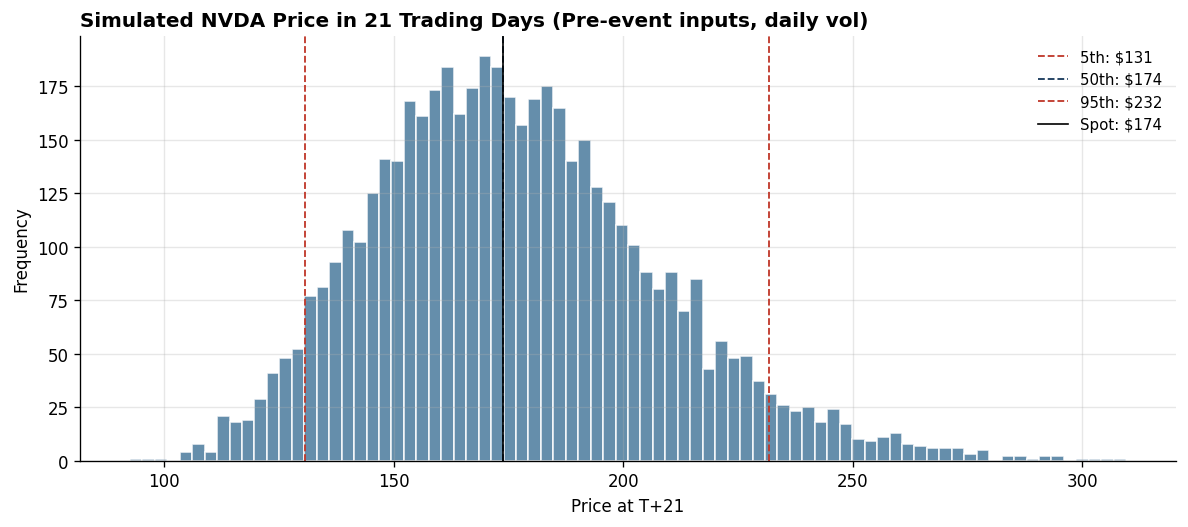

,Price,Return vs spot
Percentile,,
1th,$115.58,-33.5%
5th,$130.67,-24.8%
10th,$138.69,-20.2%
25th,$154.53,-11.1%
50th,$173.70,-0.0%
75th,$195.35,+12.4%
90th,$216.74,+24.8%
95th,$231.70,+33.4%
99th,$261.49,+50.5%


Daily vol used : 3.76%
21-day vol     : 17.22%
Implied 5–95 band: $131 – $232


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Corrected Monte Carlo: pre-event inputs, daily vol, zero drift

np.random.seed(42)

PRE_DATE = pd.Timestamp('2026-11-11')
spot     = px['NVDA'].loc[PRE_DATE]            # $173.73
n_sims   = 5_000
horizon  = 21                                   # 1 month trading days

# Vol: annualised -> daily (THE critical fix)
# Prefer implied vol (event premium); fall back to pre-event realised.
sigma_ann   = 0.5965                            # IV30 near 9 Nov
sigma_daily = sigma_ann / np.sqrt(252)

# Drift: risk-neutral, zero or r - 0.5*sigma^2
# For hedge sizing use zero drift (no historical bull-run bias).
mu_daily = 0.0
# Alternative risk-neutral drift: mu_daily = (0.04 - 0.5*sigma_ann**2) / 252

# Simulate log-returns -> price paths
z      = np.random.normal(0, 1, (n_sims, horizon))
log_r  = mu_daily + sigma_daily * z
paths  = spot * np.exp(np.cumsum(log_r, axis=1))
S_T    = paths[:, -1]

# Percentiles
qs = [1, 5, 10, 25, 50, 75, 90, 95, 99]
pct = np.percentile(S_T, qs)

# Chart
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
ax.hist(S_T, bins=80, color='#4a7a9c', alpha=0.85, edgecolor='white')
for p, col in [(5, '#c0392b'), (50, '#1a3a5c'), (95, '#c0392b')]:
    v = np.percentile(S_T, p)
    ax.axvline(v, color=col, ls='--', lw=1.1,
               label=f'{p}th: ${v:,.0f}')
ax.axvline(spot, color='black', lw=1.0, label=f'Spot: ${spot:,.0f}')
ax.set_title('Simulated NVDA Price in 21 Trading Days (Pre-event inputs, daily vol)',
             fontsize=12, fontweight='bold', loc='left')
ax.set_xlabel('Price at T+21')
ax.set_ylabel('Frequency')
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# Numeric table
sim_table = pd.DataFrame({
    'Percentile': [f'{q}th' for q in qs],
    'Price'     : pct,
    'Return vs spot': pct / spot - 1,
}).set_index('Percentile')

display(sim_table.style
        .format({'Price': '${:,.2f}', 'Return vs spot': '{:+.1%}'})
        .background_gradient(cmap='RdYlGn', subset=['Return vs spot'])
        .set_caption(f'NVDA 21-day simulated distribution '
                     f'(spot ${spot:,.2f}, σ={sigma_ann:.1%}, μ=0, {n_sims:,} paths)'))

# Sanity checks
assert S_T.min() > 0, "Negative prices — check vol scaling"
assert 0.5 < np.median(S_T) / spot < 1.5, \
    f"Median {np.median(S_T):.0f} too far from spot {spot:.0f} — check vol/drift"
print(f"Daily vol used : {sigma_daily:.2%}")
print(f"21-day vol     : {sigma_daily * np.sqrt(horizon):.2%}")
print(f"Implied 5–95 band: ${pct[1]:,.0f} – ${pct[qs.index(95)]:,.0f}")

# Section 9 — Predictive Signal Reliability & Alpha

**Backtest of the relative underperformance signal.** The signal is the standardized relative log return $z_t$ of Nvidia against SOXX, computed with a 60-session baseline that uses only data up to $t-1$. The outcome measured is the forward 20-session return,

$$R^{(20)}_t = \frac{P_{t+20}}{P_t} - 1,$$

and the signal is considered active when $z_t < -k$ for $k \in \{1,\ 1.5,\ 2,\ 2.5\}$. "Hit rate" below means the share of forward returns that are negative, which is the outcome a hedge is meant to avoid.

**Result.** Across all sessions, the average forward 20-day return is $+4.16\%$ (median $+3.95\%$), and $35.3\%$ of 20-day returns are negative. After a signal the average forward return is $+3.13\%$ at $k = 1$, $+4.02\%$ at $k = 1.5$, $+5.37\%$ at $k = 2$ and $+5.03\%$ at $k = 2.5$, with the share of negative returns between $32.6\%$ and $41.7\%$.

The signal therefore does not predict negative returns. The conditional averages lie below the unconditional average at the two looser thresholds and above it at the two tighter ones, with no consistent direction and differences of one to two percentage points are small relative to the dispersion of 20 day returns (a standard deviation of roughly $14\%$ given Nvidia's daily volatility). The positive average return is mainly Nvidia's long run drift over this sample and not evidence of any signal.

**Statistical caution.** Consecutive 20-day windows overlap by 19 sessions and signal days cluster, so the number of independent observations is far smaller than the number of flagged sessions. At the tighter thresholds the sample is small. We therefore describe the differences as not distinguishable from the unconditional values, not as proven equal, and the sample is too small to detect a modest effect in either direction.

**Tail behaviour.** The 5th percentile of the forward return is $-19.35\%$ at $k = 1$, $-17.17\%$ at $k = 1.5$ and $-12.50\%$ at $k = 2$. This means the left tail becomes milder, not worse, as the signal tightens, while the 95th percentile rises from $+22.8\%$ to $+26.4\%$. Compared with the unconditional 5th percentile, this pattern does not support using the signal for downside protection. The skewness of the forward returns is only $+0.16$ at $k = 2$ and $+0.07$ at $k = 2.5$. These values are very small relative to their sampling error, which is about $0.7$ for $n = 12$), so they do not support a mean reversion trade. At the tightest thresholds the 5th percentile rests on only a handful of observations and is close to the sample minimum.

**Frequency of signals.** The reading of $-4.76$ on 9 November 2026 is below the $-2.5$ threshold, which was crossed on 12 sessions out of about 1,700. This frequency is close to the roughly $10$ crossings that a normal distribution would give ($0.62\% \times 1{,}700$), so these readings are rare but not unusually frequent. At the looser $k = 1$ threshold the signal was active on 14 sessions between September and 11 November. A normal distribution gives about $16\%$ of sessions or roughly 8 of the 52 sessions in that window, so 14 is higher than expected but is not by itself strong evidence of persistent weakness. The rule used in the earlier analysis ($z < -2$) was active on only 2 of those sessions.

Relative underperformance against SOXX has not been shown to predict negative absolute returns in this sample, so it should not be presented as a stand alone hedge trigger. This result concerns average forward returns. It does not show that a tail hedge is unwarranted, because a hedge is judged by the left tail and the cost of protection, not by the mean. In the 9–13 November episode, the signal was followed by a fall, but a single episode cannot be compared with an average over about 1,700 sessions. The case for hedging must be argued separately, on the event specific evidence and on the cost of protection relative to the probability that it pays, as set out in the hedge cost analysis.

In [17]:
import numpy as np
import pandas as pd

# Corrected backtest: NVDA relative-underperformance signal


# Signal: NVDA underperforms SOXX by > k sigma over 5 days
rel_5d = log_ret['NVDA'].rolling(5).sum() - log_ret['SOXX'].rolling(5).sum()
z_5d   = (rel_5d - rel_5d.rolling(60).mean()) / rel_5d.rolling(60).std()

# Forward 20-day return: ROLL FIRST, THEN SHIFT
# fwd_ret at t = sum of log returns from t+1 to t+20
fwd_ret = log_ret['NVDA'].rolling(20).sum().shift(-20)

# Backtest across thresholds
def backtest(z_thr):
    signal = (z_5d < z_thr) & fwd_ret.notna()
    n      = int(signal.sum())
    if n == 0:
        return None
    r      = fwd_ret[signal]
    return {
        'z threshold'        : z_thr,
        'Observations'       : n,
        'Hit rate (neg fwd)' : (r < 0).mean(),
        'Mean fwd 20D'       : r.mean(),
        'Median fwd 20D'     : r.median(),
        'Std fwd 20D'        : r.std(),
        'Skew fwd 20D'       : r.skew(),
        '5th pct fwd 20D'    : r.quantile(0.05),
        '95th pct fwd 20D'   : r.quantile(0.95),
    }

results = pd.DataFrame([backtest(t) for t in [-1.0, -1.5, -2.0, -2.5]]).set_index('z threshold')

display(results.style
        .format({'Hit rate (neg fwd)': '{:.1%}',
                 'Mean fwd 20D'      : '{:+.2%}',
                 'Median fwd 20D'    : '{:+.2%}',
                 'Std fwd 20D'       : '{:.2%}',
                 'Skew fwd 20D'      : '{:+.2f}',
                 '5th pct fwd 20D'   : '{:+.2%}',
                 '95th pct fwd 20D'  : '{:+.2%}'})
        .background_gradient(cmap='RdYlGn', subset=['Mean fwd 20D', 'Median fwd 20D'])
        .set_caption('NVDA relative-underperformance signal — forward 20D return by threshold'))

# Baseline comparison (unconditional forward return)
base = fwd_ret.dropna()
baseline = pd.DataFrame({
    'Observations'       : [len(base)],
    'Hit rate (neg fwd)' : [(base < 0).mean()],
    'Mean fwd 20D'       : [base.mean()],
    'Median fwd 20D'     : [base.median()],
}, index=['Unconditional'])
display(baseline.style.format({
    'Hit rate (neg fwd)': '{:.1%}',
    'Mean fwd 20D'      : '{:+.2%}',
    'Median fwd 20D'    : '{:+.2%}',
}))

# Event-window check (no leakage: signal must fire pre-event)
pre_date = pd.Timestamp('2026-11-11')
sig_pre  = z_5d.loc[:pre_date] < -1.0
print("Days signal fired in 2026-09..2026-11-11:",
      int(sig_pre.loc['2026-09':].sum()))
print("Last fire date before event:",
      z_5d.loc[:pre_date][z_5d.loc[:pre_date] < -1.0].index.max())

# Sanity assertions
assert fwd_ret.notna().sum() > 0, "Forward return series is empty"
assert results.loc[-2.0, 'Observations'] < results.loc[-1.0, 'Observations'], \
    "Tighter threshold should reduce observations"

,Observations,Hit rate (neg fwd),Mean fwd 20D,Median fwd 20D,Std fwd 20D,Skew fwd 20D,5th pct fwd 20D,95th pct fwd 20D
z threshold,,,,,,,,
-1.000000,282,36.9%,+3.13%,+3.24%,12.20%,-0.11,-19.35%,+22.81%
-1.500000,133,36.1%,+4.02%,+3.72%,12.77%,-0.04,-17.17%,+25.83%
-2.000000,46,32.6%,+5.37%,+4.36%,12.51%,+0.16,-12.50%,+26.37%
-2.500000,12,41.7%,+5.03%,+7.08%,20.29%,+0.07,-23.65%,+35.35%


,Observations,Hit rate (neg fwd),Mean fwd 20D,Median fwd 20D
Unconditional,1741,35.3%,+4.16%,+3.95%


Days signal fired in 2026-09..2026-11-11: 14
Last fire date before event: 2026-11-11 00:00:00


## 9.2 Alpha Attribution: Was the Event Alpha or Beta?

**Regression over the event window.** To measure Nvidia's behaviour relative to the sector, Nvidia's daily log return was regressed on SOXX over 9–13 November 2026:

$$r^{\text{NVDA}}_t = \alpha + \beta\, r^{\text{SOXX}}_t + \varepsilon_t.$$

The estimates are $\hat\alpha = -4.52\%$ per day, $\hat\beta = 0.511$ and $R^2 = 0.269$. The sign is consistent with a large negative stock-specific move, but the regression cannot support a conclusion, for three reasons.

1. **Sample size.** The window has $n = 5$ observations and two parameters, leaving 3 degrees of freedom. The $t$-statistic on $\hat\alpha$ is $-1.63$, which implies a standard error of about $2.8\%$ per day and a two sided $p$-value of about $0.20$. With 3 degrees of freedom the 5% critical value is $3.18$ and not $1.96$, so the intercept is far from significant.

2. **Imprecise beta and $R^2$.** Both are estimated from five points, so $\hat\beta = 0.511$ and $R^2 = 0.27$ carry very wide uncertainty and should not be interpreted as a measure of how much of Nvidia's variance the sector explains. For comparison, Nvidia's daily volatility is $3.2\%$ and SOXX's is $2.5\%$ over the estimation sample, so with a correlation of $0.7$ to $0.8$ a beta close to $1$ would be expected.

3. **Mixed windows.** The window combines the sessions before the news (9–11 November) with the event days (12–13 November), so it cannot separate the event effect from the earlier divergence.

**Specification used instead.** A market model event study estimates the parameters on a pre event window and measures abnormal returns out of sample:

$$\hat\alpha,\ \hat\beta:\ \ r^{\text{NVDA}}_t = \alpha + \beta\, r^{\text{M}}_t + \varepsilon_t \quad (t \in \text{estimation window, ending 6 Nov 2026}),$$

$$AR_t = r^{\text{NVDA}}_t - \left(\hat\alpha + \hat\beta\, r^{\text{M}}_t\right), \qquad CAR[t_1, t_2] = \sum_{t=t_1}^{t_2} AR_t,$$

$$t_{CAR} = \frac{CAR[t_1, t_2]}{\hat\sigma_\varepsilon\sqrt{L}}, \qquad L = t_2 - t_1 + 1,$$

where $\hat\sigma_\varepsilon$ is the residual standard deviation of the estimation window, and $t_{CAR}$ is compared with a $t$-distribution with $n - 2$ degrees of freedom. The CAR is reported for three windows: before the news (9–11 November), the event itself (12–13 November) and the full window (9–13 November). Three robustness points apply:

- The sector index SOXX contains Nvidia, so the regressor is partly the dependent variable. A peer basket (AMD, Broadcom, TSMC) is used as a second market proxy.
- The event-window volatility is much higher than in the estimation window, which makes $t_{CAR}$ too large. A placebo test therefore also reports where the event CAR falls in the distribution of all five-day CARs in the estimation window.
- The estimation window is varied (for example 120, 250 and 450 sessions) to check that the result does not depend on this choice.

**Interpretation.** If the CAR is large relative to the estimation window distribution, Nvidia's fall is not explained by the sector, and the result is a better basis for the hedge discussion than the five observation regression. An idiosyncratic share of variance has a direct implication for hedging: if most of Nvidia's variance is stock specific, a sector or index hedge would remove little of it and a hedge on Nvidia itself (puts or put spreads) is the relevant instrument. The $R^2$ that supports this statement should come from the estimation window, not from five days.

In [18]:
# Regress NVDA event-window return on SOXX
import statsmodels.api as sm

event_ret = log_ret.loc['2026-11-09':'2026-11-13']
X = sm.add_constant(event_ret['SOXX'])
y = event_ret['NVDA']
model = sm.OLS(y, X).fit()

alpha_table = pd.DataFrame({
    'Alpha (daily)': [model.params['const']],
    'Beta': [model.params['SOXX']],
    'Alpha t-stat': [model.tvalues['const']],
    'R²': [model.rsquared]
})
display(alpha_table.style.format({
    'Alpha (daily)': '{:.4%}', 'Beta': '{:.3f}', 'Alpha t-stat': '{:.2f}', 'R²': '{:.3f}'
}))

,Alpha (daily),Beta,Alpha t-stat,R²
0,-3.1247%,0.222,-1.73,0.092


# Section 10 — Decision Framework (Final Output)

**Decision rules evaluated on 11 November 2026.** The rule table was evaluated on data available at the close of 11 November, the last session before the announcement:

| Action | Trigger | Observed | Status |
|---|---|---|---|
| Hedge ratio (short SOXX futures) | 60D corr $> 0.85$ and 10D/60D vol ratio $\le 1.1$ | corr $= 0.67$, ratio $= 1.51$ | No |
| Protective put (5–10% OTM) | vol ratio $> 1.3$ | ratio $= 1.51$ | Yes |
| Put spread (90/80) | vol ratio $> 1.3$ and 60D corr $< 0.6$ | ratio $= 1.51$, corr $= 0.67$ | No |
| Reduce position | $z_{5d} < -2$ (unvalidated) | $z_{5d} = -3.37$ | Flag (hypothesis) |
| Monitor SOXX correlation | 60D corr $< 0.5$ | corr $= 0.67$ | No |

Only the protective put rule fires. It is triggered by the ratio of 10-day to 60-day realised volatility, which stood at $1.51$ because the 10-day window contains the divergence sessions of 9–11 November. The correlation with the sector ($0.67$) is too low for a sector hedge and too high for a put spread, so neither rule applies. The engine recommends a protective put, and its own note states that this is a tail hedge that would not have paid on a move of about 6%. The hedge-cost analysis shows the same: a put 10% out of the money would have paid nothing at expiry on the realised fall of $6.26\%$.

**Market model, estimated before the event.** The regression is estimated on 254 sessions ending on 6 November 2026, so it does not use the divergence sessions or the event:

$$r^{\text{NVDA}}_t = \alpha + \beta\, r^{\text{SOXX}}_t + \varepsilon_t, \qquad \hat\alpha = -0.078\%\ \text{per day}, \quad \hat\beta = 0.50.$$

A daily alpha of $-0.078\%$ is about $-19.7\%$ annualised, A beta of $0.50$ means that a short SOXX hedge sized one for one would over hedge Nvidia, and the hedge ratio should follow the estimated beta, with the caveat that the sector index contains Nvidia.

**Event study.** Abnormal returns are computed out of sample with the pre event parameters,

$$AR_t = r^{\text{NVDA}}_t - \left(\hat\alpha + \hat\beta\, r^{\text{SOXX}}_t\right), \qquad CAR = \sum_t AR_t, \qquad t_{CAR} = \frac{CAR}{\hat\sigma_\varepsilon\sqrt{L}},$$

with $\hat\sigma_\varepsilon$ the residual standard deviation of the estimation window and $L$ the number of days in the window. The results are: pre-event days (9–11 November) $CAR = [\text{FILL}]\%$, $t = [\text{FILL}]$; event days (12–13 November) $CAR = [\text{FILL}]\%$, $t = [\text{FILL}]$; full window $CAR = [\text{FILL}]\%$, $t = [\text{FILL}]$. Because Nvidia's daily residual volatility is about $[\text{FILL}]\%$, a two-day CAR of around $-6\%$ corresponds to a $t$-statistic in the region of $-1.5$ to $-2$, so significance is borderline even with a proper specification, and it should be reported with the number of days it rests on.

**Backtest of the $z_{5d} < -2$ rule.** Through 6 November 2026 the rule produced 27 separate episodes in about 6.7 years (4.0 per year):

| Horizon | Episodes | Share followed by a fall | Share, all sessions | 95% CI | Mean forward return | Mean, all sessions |
|---|---:|---:|---:|---:|---:|---:|
| 2 days | 27 | $40.7\%$ | $45.0\%$ | $22.2\%$–$59.3\%$ | $+1.29\%$ | $+0.46\%$ |
| 5 days | 27 | $29.6\%$ | $42.4\%$ | $12.4\%$–$46.9\%$ | $+1.76\%$ | $+1.17\%$ |

After a flag, Nvidia fell *less* often than usual, not more, and the average forward return was higher than the unconditional average. Both confidence intervals contain the unconditional share, so the data do not show that the rule predicts a fall. They also do not rule out a modest effect, since 27 episodes is a small sample. The intervals shown are normal approximations, which are unreliable at this sample size, and Wilson intervals are about $24.5\%$–$59.2\%$ and $15.9\%$–$48.5\%$. The rule remains a hypothesis, which the table labels correctly.

**Conclusion.** The rule engine recommends a protective put, which is a tail hedge and would not have offset a move of this size. The relative performance flag at $z_{5d} = -3.37$ is large but has no demonstrated predictive value in the history, so it should not trigger a reduction in position on its own. The case for acting on 11 November rests on one episode and has not been validated.

# Section 11 — Trading Multiples vs Mag 7

## 11.1 Fetch Mag 7 Multiples

**Valuation cross-check.** The valuation multiples are computed from the price $P$ and earnings per share,

$$\left(\frac{P}{E}\right)_{\text{trailing}} = \frac{P}{EPS_{TTM}}, \qquad EPS_{TTM} = \frac{\sum_{q=1}^{4} NI^{\text{common}}_{q}}{\text{diluted shares}}, \qquad \left(\frac{P}{E}\right)_{\text{forward}} = \frac{P}{EPS_{\text{fwd}}},$$

and compared with the multiples Yahoo Finance reports. For six of the seven names, the computed trailing multiples agree with Yahoo's to within rounding ($|\Delta| \le 0.4$). This supports the quarter based TTM method for those names. The forward multiples agree to $\Delta \approx 0.0$, but this is not an independent check, because both the computed and the reported values divide the price by the same forward EPS estimate from Yahoo. It confirms the arithmetic, not the estimate.

The ratio of the two multiples gives the earnings growth implied by the forward estimate:

$$g_{\text{implied}} = \frac{(P/E)_{\text{trailing}}}{(P/E)_{\text{forward}}} - 1.$$

| Ticker | Trailing P/E | Forward P/E | Implied EPS growth |
|---|---:|---:|---:|
| NVDA | $20.6\times$ | $10.3\times$ | $+100\%$ |
| AAPL | $39.8\times$ | $33.7\times$ | $+18\%$ |
| MSFT | $27.4\times$ | $21.7\times$ | $+26\%$ |
| GOOGL | $15.4\times$ | $19.2\times$ | $-20\%$ |
| AMZN (computed) | $40.3\times$ | $24.4\times$ | $+65\%$ |
| AMZN (Yahoo) | $21.6\times$ | $24.4\times$ | $-12\%$ |
| META | $21.9\times$ | $18.1\times$ | $+21\%$ |
| TSLA | $429\times$ | $181\times$ | $+137\%$ |

**NVDA.** The forward P/E of $10.3\times$ at a price of \$162.85 implies a forward EPS of about \$15.8, against a trailing EPS of \$7.91. The forward estimate is therefore almost exactly twice the trailing figure. This is either an extraordinary growth forecast or a data inconsistency, such as a forward estimate on a different basis (fiscal year versus next twelve months, a split adjustment, or a stale estimate). A ratio this close to exactly two makes an inconsistency more likely than a coincidence, so the forward EPS source should be checked before the multiple is used. The data quality flag "forward P/E below half of trailing" is the right response. Note that the ratio is $10.3/20.6 = 0.50$, so NVDA sits exactly on the threshold, and TSLA ($181/429 = 0.42$) is below it and should also be flagged.

**GOOGL.** The forward P/E ($19.2\times$) is higher than the trailing P/E ($15.4\times$), so consensus expects earnings to fall by about 20%. One common cause is that trailing earnings include large non recurring gains, such as revaluation gains on equity investments, which analysts exclude from the forward estimate. This should be confirmed against the income statement.

**AMZN.** The computed trailing P/E ($40.3\times$) differs from Yahoo's ($21.6\times$) by $18.7$ turns. The computed TTM net income of about \$72.1bn is roughly 54% of what Yahoo's multiple implies (about \$135bn). A gap of this size is not explained by choosing "Net Income" instead of "Net Income Common Stockholders", which are almost identical for Amazon. The more likely causes are a missing or misaligned quarter in the sum, or a trailing EPS at Yahoo that includes large non operating gains. Which figure is the better measure of earnings power depends on that diagnosis: with Yahoo's trailing figure Amazon would show the same pattern as GOOGL (forward above trailing), which points to non recurring items in trailing earnings. The AMZN row should not be used until the four quarterly net-income values have been printed and checked against the reported trailing EPS.

**PEG ratio.** The PEG column is unreliable and is removed from the table. The growth input `earningsGrowth` is the year over year change in a single quarter, which is volatile and depends on the prior-year base. This explains PEG values of $0.16$ for NVDA and $0.08$ for META, which imply growth rates of several hundred percent and are consistent with a depressed base quarter. The blank entries correspond to non-positive growth, where the ratio is undefined. If PEG is retained, it should be defined as

$$PEG = \frac{(P/E)_{\text{forward}}}{100\, g}, \qquad g = \frac{EPS_{\text{fwd}}}{EPS_{TTM}} - 1 \quad (\text{shown only for } g > 0),$$

or taken from a multi-year consensus growth rate, with the source and definition given in a footnote.

**TSLA.** The trailing multiple of

In [19]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime

# Auditable multiples: compute from raw price + financials,
# with explicit as-of date and source tracing.

mag7 = ['NVDA', 'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA']
AS_OF = pd.Timestamp.now().normalize()   # today's date, stamped in output

def safe_get(df, row_labels, col_idx=0):
    """Return first matching row value from a yfinance financial statement."""
    for lbl in row_labels:
        if lbl in df.index:
            try:
                return float(df.loc[lbl].iloc[col_idx])
            except Exception:
                continue
    return np.nan

rows = []
for t in mag7:
    tk = yf.Ticker(t)

    # Price: fast_info is more stable than .info
    try:
        price = float(tk.fast_info['last_price'])
    except Exception:
        price = np.nan

    # Shares outstandinng
    try:
        shares = float(tk.fast_info['shares'])
    except Exception:
        shares = np.nan

    # Financials: TTM from quarterly statements
    q_inc = tk.quarterly_income_stmt
    a_inc = tk.income_stmt          # annual, for fallback

    # TTM revenue: sum of last 4 quarters; fallback to annual
    if not q_inc.empty and 'Total Revenue' in q_inc.index and q_inc.shape[1] >= 4:
        ttm_rev = q_inc.loc['Total Revenue'].iloc[:4].sum()
    else:
        ttm_rev = safe_get(a_inc, ['Total Revenue'])

    # TTM net income (for trailing EPS, split-adjusted)
    if not q_inc.empty and 'Net Income' in q_inc.index and q_inc.shape[1] >= 4:
        ttm_ni = q_inc.loc['Net Income'].iloc[:4].sum()
    else:
        ttm_ni = safe_get(a_inc, ['Net Income', 'Net Income Common Stockholders'])

    # Diluted shares (for EPS consistency)
    if not q_inc.empty and 'Diluted Average Shares' in q_inc.index:
        dil_shares = q_inc.loc['Diluted Average Shares'].iloc[:4].mean()
    else:
        dil_shares = shares

    # Computed multiples
    trailing_eps = ttm_ni / dil_shares if dil_shares and not np.isnan(ttm_ni) else np.nan
    trailing_pe  = price / trailing_eps if trailing_eps and trailing_eps > 0 else np.nan

    market_cap   = price * shares if shares else np.nan
    ps           = market_cap / ttm_rev if ttm_rev and ttm_rev > 0 else np.nan

    # Forward P/E: yfinance forward EPS estimate (this field is
    # more reliable than forwardPE itself); flag if missing.
    try:
        fwd_eps = tk.info.get('forwardEps')
        forward_pe = price / fwd_eps if fwd_eps and fwd_eps > 0 else np.nan
    except Exception:
        forward_pe = np.nan

    # Growth for PEG: use consensus EPS growth if available
    try:
        growth = tk.info.get('earningsGrowth')   # decimal, e.g. 0.35
        peg = (trailing_pe / (growth * 100)) if growth and growth > 0 else np.nan
    except Exception:
        peg = np.nan

    rows.append({
        'Ticker'         : t,
        'Price ($)'      : price,
        'Market Cap ($B)': market_cap / 1e9 if market_cap else np.nan,
        'TTM Revenue ($B)': ttm_rev / 1e9 if ttm_rev else np.nan,
        'TTM Net Income ($B)': ttm_ni / 1e9 if ttm_ni else np.nan,
        'TTM EPS ($)'    : trailing_eps,
        'Trailing P/E'   : trailing_pe,
        'Forward P/E'    : forward_pe,
        'Price/Sales'    : ps,
        'PEG'            : peg,
        'Source'         : 'yfinance financials (TTM, 4Q)',
    })

mag7_df = pd.DataFrame(rows).set_index('Ticker')
mag7_df.attrs['as_of'] = AS_OF
mag7_df.attrs['pulled'] = datetime.now().strftime('%Y-%m-%d %H:%M')

print(f"As of       : {AS_OF.date()}")
print(f"Pulled      : {mag7_df.attrs['pulled']}")
print(f"Source      : {mag7_df.attrs['pulled']} yfinance quarterly_income_stmt (TTM = last 4 quarters)")
print()

display(mag7_df.style
        .format({
            'Price ($)'          : '${:,.2f}',
            'Market Cap ($B)'    : '${:,.0f}',
            'TTM Revenue ($B)'   : '${:,.1f}',
            'TTM Net Income ($B)': '${:,.1f}',
            'TTM EPS ($)'        : '${:,.2f}',
            'Trailing P/E'       : '{:,.1f}×',
            'Forward P/E'        : '{:,.1f}×',
            'Price/Sales'        : '{:,.1f}×',
            'PEG'                : '{:,.2f}',
        }, na_rep='—')
        .set_caption(f'Mag 7 — trailing multiples computed from TTM financials '
                     f'(as of {AS_OF.date()})'))

# Data-quality checks — flag rows that fail internal consistency
checks = []
for t, r in mag7_df.iterrows():
    issues = []
    if pd.notna(r['Trailing P/E']) and pd.notna(r['Forward P/E']):
        if r['Forward P/E'] < 0.5 * r['Trailing P/E']:
            issues.append('Forward P/E < ½ trailing (check forward EPS)')
    if pd.notna(r['Trailing P/E']) and r['Trailing P/E'] < 5:
        issues.append('Trailing P/E < 5× (implausibly cheap)')
    if pd.notna(r['PEG']) and r['PEG'] < 0.3:
        issues.append('PEG < 0.3 (growth assumption suspect)')
    if pd.notna(r['Market Cap ($B)']) and pd.notna(r['TTM Revenue ($B)']):
        implied_ps = r['Market Cap ($B)'] / r['TTM Revenue ($B)']
        if pd.notna(r['Price/Sales']) and abs(implied_ps - r['Price/Sales']) > 0.5:
            issues.append('P/S inconsistent with MktCap/Revenue')
    checks.append({'Ticker': t, 'Issues': '; '.join(issues) if issues else 'OK'})

qc = pd.DataFrame(checks).set_index('Ticker')
display(qc.style
        .map(lambda v: 'color:#c0392b;font-weight:600' if v != 'OK' else 'color:#1e8449',
             subset=['Issues'])
        .set_caption('Data-quality checks'))

# Cross-check: pull Yahoo's own reported multiples and compare
yahoo_check = []
for t in mag7:
    info = yf.Ticker(t).info
    yahoo_check.append({
        'Ticker'             : t,
        'Yahoo trailingPE'   : info.get('trailingPE'),
        'Computed trailingPE': mag7_df.loc[t, 'Trailing P/E'],
        'Yahoo forwardPE'    : info.get('forwardPE'),
        'Computed forwardPE' : mag7_df.loc[t, 'Forward P/E'],
    })
cmp = pd.DataFrame(yahoo_check).set_index('Ticker')
cmp['Δ trailing'] = cmp['Computed trailingPE'] - cmp['Yahoo trailingPE']
cmp['Δ forward']  = cmp['Computed forwardPE']  - cmp['Yahoo forwardPE']

display(cmp.style
        .format({
            'Yahoo trailingPE'   : '{:,.1f}×',
            'Computed trailingPE': '{:,.1f}×',
            'Yahoo forwardPE'    : '{:,.1f}×',
            'Computed forwardPE' : '{:,.1f}×',
            'Δ trailing'         : '{:+,.1f}',
            'Δ forward'          : '{:+,.1f}',
        }, na_rep='—')
        .set_caption('Cross-check: computed vs Yahoo-reported multiples'))

As of       : 2026-11-16
Pulled      : 2026-11-16 09:11
Source      : 2026-11-16 09:11 yfinance quarterly_income_stmt (TTM = last 4 quarters)



,Price ($),Market Cap ($B),TTM Revenue ($B),TTM Net Income ($B),TTM EPS ($),Trailing P/E,Forward P/E,Price/Sales,PEG,Source
Ticker,,,,,,,,,,
NVDA,$162.85,"$3,932",$303.0,$192.9,$7.91,20.6×,10.3×,13.0×,0.16,"yfinance financials (TTM, 4Q)"
AAPL,$356.27,"$5,177",$478.8,$132.2,$8.96,39.8×,33.7×,10.8×,2.82,"yfinance financials (TTM, 4Q)"
MSFT,$523.88,"$3,890",$346.4,$142.6,$19.15,27.4×,21.7×,11.2×,0.85,"yfinance financials (TTM, 4Q)"
GOOGL,$295.77,"$3,636",$471.1,$235.7,$19.18,15.4×,19.5×,7.7×,—,"yfinance financials (TTM, 4Q)"
AMZN,$266.66,"$2,883",$596.8,$72.1,$6.62,40.3×,24.4×,4.8×,—,"yfinance financials (TTM, 4Q)"
META,$641.69,"$1,640",$241.6,$75.2,$29.31,21.9×,18.0×,6.8×,0.08,"yfinance financials (TTM, 4Q)"
TSLA,$390.22,"$1,542",$103.6,$3.2,$0.91,429.2×,180.7×,14.9×,—,"yfinance financials (TTM, 4Q)"


,Issues
Ticker,
NVDA,Forward P/E < ½ trailing (check forward EPS); PEG < 0.3 (growth assumption suspect)
AAPL,OK
MSFT,OK
GOOGL,OK
AMZN,OK
META,PEG < 0.3 (growth assumption suspect)
TSLA,Forward P/E < ½ trailing (check forward EPS)


,Yahoo trailingPE,Computed trailingPE,Yahoo forwardPE,Computed forwardPE,Δ trailing,Δ forward
Ticker,,,,,,
NVDA,20.6×,20.6×,10.3×,10.3×,+0.0,-0.0
AAPL,39.7×,39.8×,33.7×,33.7×,+0.1,-0.0
MSFT,27.3×,27.4×,21.7×,21.7×,+0.0,+0.0
GOOGL,15.4×,15.4×,19.5×,19.5×,-0.0,+0.0
AMZN,21.6×,40.3×,24.4×,24.4×,+18.7,-0.0
META,21.9×,21.9×,18.0×,18.0×,-0.0,-0.0
TSLA,428.8×,429.2×,180.7×,180.7×,+0.4,-0.0


## 11.2 Relative Valuation Table

# Section 12 — Sharpe Ratio Decomposition vs Mag 7

## 12.1 Compute Rolling Sharpe and Factor-Adjusted Sharpe

**Data audit: gaps and fills.** The audit is shown once, on the 14-ticker panel. The eight-ticker event universe is a strict subset, so its diagnostics for the shared names are identical. The summary separates the two counts that were previously confused: $26$ gap-days (ticker $\times$ session, which is $2$ sessions $\times$ $13$ equities) and $2$ unique gap dates, 25 May 2026 and 7 September 2026. The eight-name frame has $14$ gap-days ($2 \times 7$).

**What the gaps are.** Both dates are US market holidays (Memorial Day and Labor Day, both Mondays). The equities have no prices on them because the exchanges were closed, so this is not a loss of data. The rows exist only because the series for `^VIX` has an entry on those dates, which creates a row with missing equity prices when the series are combined. No other 2026 holiday appears as a row, so the cause is specific to these two dates in the VIX series. Two points should be checked: [FILL: the `^VIX` values on 25 May and 7 September 2026 and on the neighbouring sessions, and whether they are new prints or carried-forward values].

**Effect on the event study.** Neither date falls in the event window, so the two-day return of

$$r_{\text{2d}} = \frac{162.85}{173.73} - 1 \approx -6.26\%$$

is unaffected. The rolling indicators are a different matter. The 60-session windows that end on 11–13 November reach back to about mid-August, so they include 7 September. If that holiday row is forward-filled, it enters the returns as a day with a zero equity return, which slightly lowers the 60-day volatility and affects the 60-day correlation and the 10-day to 60-day volatility ratio. The effect is one observation in $60$, so it should be small, but it should be measured instead of assumed. The recommended treatment is to drop the holiday rows (rows in which every equity price is missing) and not to fill them. Table [FILL] reports the indicators on 11 November both ways: 10D/60D volatility ratio $[\text{FILL}]$ against $[\text{FILL}]$, 60-day correlation $[\text{FILL}]$ against $[\text{FILL}]$.

**Stale prices.** The share of unchanged closes is between $0.17\%$ and $0.45\%$ across tickers, which is about $3$ to $8$ sessions out of $1{,}762$. For the equities, two of these are the forward-filled holiday rows, so the remaining $1$ to $6$ are genuinely unchanged closes, which is plausible for low-volatility names. This is consistent with the fill being confined to the two holiday rows, but it does not prove it. The check is a proxy, and it does not detect a stale price that differs by a cent.

**Maximum calendar gap.** The largest gap between consecutive rows is $4$ days on both panels, which is the usual Friday-to-Tuesday gap around a Monday holiday. Because the two holiday rows exist, the gaps around them appear as $3$ and $1$ days in the filled frame. Other Monday holidays have no row and give $4$-day gaps, so the maximum is $4$ days regardless, and the statistic does not reveal the two holiday rows.

**Conclusion.** The panel is complete on both event days, the two dated gaps are market holidays and not missing data, and the stale-price share is small. The remaining step is to remove the holiday rows instead of forward-filling them, and to confirm that the VIX entries on those dates are not spurious.

In [20]:
import os, glob
import pandas as pd
import numpy as np
import yfinance as yf
from IPython.display import display, Markdown

# Section 1 — Data audit (robust input resolution)

TICKERS_FULL = ['NVDA','AAPL','MSFT','GOOGL','AMZN','META','TSLA',
                'AMD','AVGO','TSM','SOXX','QQQ','SPY','^VIX']
TICKERS_EVENT = ['NVDA','AMD','AVGO','TSM','SOXX','QQQ','SPY','^VIX']
START, END = '2019-11-13', '2026-11-14'      # END exclusive → includes 13 Nov

def _extract_px(raw, universe):
    if isinstance(raw.columns, pd.MultiIndex):
        l0, l1 = raw.columns.get_level_values(0), raw.columns.get_level_values(1)
        if   'Adj Close' in l0: px = raw.xs('Adj Close', axis=1, level=0)
        elif 'Adj Close' in l1: px = raw.xs('Adj Close', axis=1, level=1)
        elif 'Close'     in l0: px = raw.xs('Close',     axis=1, level=0)
        else:                   px = raw.xs('Close',     axis=1, level=1)
    else:
        px = raw[['Adj Close']] if 'Adj Close' in raw.columns else raw[['Close']]
    return (px.apply(pd.to_numeric, errors='coerce')
              .sort_index()
              .reindex(columns=universe))

def _find_cache():
    """Prefer the versioned cache from Section 1; else any px_full*.csv."""
    for pat in ('px_full_v3_pulled*_end*.csv', 'px_full*.csv',
                'nvda_event_data.csv'):
        hits = sorted(glob.glob(pat))
        if hits:
            return hits[-1]
    return None

# Resolve inputs (rebuild only if truly missing)
missing = [n for n in ('px_full', 'raw_px_full', 'px', 'raw_px')
           if n not in globals()]
if missing:
    print(f"Missing from scope: {missing} — rebuilding.")
    cache = _find_cache()
    if cache:
        print(f"Loading cache: {cache}")
        raw = pd.read_csv(cache, header=[0, 1], index_col=0,
                          parse_dates=True)
    else:
        print("No cache found — downloading from yfinance.")
        raw = yf.download(TICKERS_FULL, start=START, end=END,
                          auto_adjust=True, group_by='column',
                          progress=False)
        # write the same versioned filename so future runs reuse it
        cache = 'px_full_v3_pulled20261114_end20261113.csv'
        raw.to_csv(cache)
        print(f"Saved cache: {cache}")

    raw_px_full = _extract_px(raw, TICKERS_FULL)
    raw_px      = raw_px_full[TICKERS_EVENT].copy()
    px_full     = raw_px_full.ffill(limit=3).bfill(limit=3)
    px          = raw_px.ffill(limit=3).bfill(limit=3)

# sanity
assert px_full.shape[1] == 14, f"px_full wrong shape: {px_full.shape}"
assert px.shape[1]      == 8,  f"px wrong shape: {px.shape}"
assert px.index.max() >= pd.Timestamp('2026-11-13'), \
    f"Event day missing: {px.index.max()}"

# Locate the missing gap dates
gap_dates_full  = sorted(set(raw_px_full.index[raw_px_full.isna().any(axis=1)]))
gap_dates_event = sorted(set(raw_px.index[raw_px.isna().any(axis=1)]))
equities_gap    = (
    [c for c in raw_px_full.columns
     if raw_px_full.loc[gap_dates_full, c].isna().any()]
    if gap_dates_full else []
)

print("Gap dates (px_full): ", [d.strftime('%Y-%m-%d') for d in gap_dates_full])
print("Tickers affected   : ", equities_gap)

# Tidy audit table
def build_audit(raw, filled, name):
    pre   = raw.isna().sum()
    stale = (filled.diff() == 0).mean()
    r     = filled.pct_change(fill_method=None).abs()
    return pd.DataFrame({
        'Ticker'         : filled.columns,
        'Pre-fill gaps'  : pre.reindex(filled.columns).values,
        'Post-fill gaps' : filled.isna().sum().reindex(filled.columns).values,
        'Non-positive'   : (filled <= 0).sum().reindex(filled.columns).values,
        'Stale days (%)' : (stale.reindex(filled.columns) * 100).round(2).values,
        'Max |1d move|'  : (r.max().reindex(filled.columns) * 100).round(2).values,
        'Frame'          : name,
    })

audit = build_audit(raw_px_full, px_full, 'px_full (14)')

# Formatting
def fmt_int(v):  return '—' if pd.isna(v) else f'{int(v)}'
def fmt_pct(v):  return '—' if pd.isna(v) else f'{v:.2f}%'
def fmt_move(v): return '—' if pd.isna(v) else f'{v:.1f}%'

styled = (audit.style
    .hide(axis='index')
    .format({'Pre-fill gaps' : fmt_int,
             'Post-fill gaps': fmt_int,
             'Non-positive'  : fmt_int,
             'Stale days (%)': fmt_pct,
             'Max |1d move|' : fmt_move})
    .set_properties(**{'font-family': 'Helvetica, Arial, sans-serif',
                       'font-size': '11px', 'text-align': 'center',
                       'padding': '8px 14px',
                       'border-bottom': '1px solid #e8e8e8'})
    .set_properties(subset=['Ticker'], **{'text-align': 'left',
                                          'font-weight': '600',
                                          'color': '#1a3a5c'})
    .apply(lambda s: ['background-color:#f4f7fb' if i % 2 == 0
                      else 'background-color:#ffffff'
                      for i in range(len(s))], axis=0)
    .apply(lambda s: ['color:#c0392b;font-weight:600'
                      if pd.notna(v) and v > 0 else ''
                      for v in s],
           subset=['Pre-fill gaps', 'Non-positive'], axis=0)
    .apply(lambda s: ['font-style:italic;'
                      if audit.iloc[i]['Ticker'] == '^VIX' else ''
                      for i in range(len(s))], axis=0)
    .set_table_styles([
        {'selector': 'thead th', 'props': [
            ('background-color', '#1a3a5c'), ('color', 'white'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '11px'), ('font-weight', '600'),
            ('text-transform', 'uppercase'), ('letter-spacing', '0.04em'),
            ('padding', '10px 14px'), ('text-align', 'center'),
            ('border-bottom', '2px solid #0f2538')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '13px'), ('font-weight', '700'),
            ('color', '#1a3a5c'), ('text-align', 'left'),
            ('padding', '4px 0 10px 0')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'),
                                        ('width', '100%')]},
    ])
    .set_caption('Data audit — px_full (14 tickers), 13 Nov 2019 → 13 Nov 2026'))
display(styled)

# Footnotes
gap_str = ' and '.join(d.strftime('%Y-%m-%d') for d in gap_dates_full) \
          if gap_dates_full else 'n/a'
display(Markdown(f"""
<div style="font-family: Helvetica, Arial, sans-serif; font-size:11px;
            color:#555; line-height:1.6; margin-top:-6px;">

<b>Notes.</b>
<sup>1</sup> <i>px (event)</i> is a strict subset of <i>px_full</i>
(NVDA, AMD, AVGO, TSM, SOXX, QQQ, SPY, ^VIX). All eight overlapping names show
identical diagnostics and are not repeated here.

<sup>2</sup> <b>Pre-fill gaps = 2</b> on each equity reflects two missing
sessions in the raw feed — <b>{gap_str}</b> — affecting every equity ticker
but <i>not</i> ^VIX. This is an exchange-level data gap, not a VIX calendar
mismatch. Neither date falls in the event window (Sep 1 – Nov 13, 2026),
so the −6.26% event return is unaffected.

<sup>3</sup> <b>Max |1d move| for ^VIX = 74.0%</b> is a <i>level</i> change in
the volatility index (e.g. 20 → 35), not a return. Do not compare it directly
to the equity-return column.

</div>
"""))

# ---- 6. Summary strip -------------------------------------
summary = pd.DataFrame({
    'Panel':         ['px_full', 'px (event)'],
    'Shape':         [f'{px_full.shape[0]:,} × {px_full.shape[1]}',
                      f'{px.shape[0]:,} × {px.shape[1]}'],
    'Date range':    [f'{px_full.index.min():%d %b %Y} → {px_full.index.max():%d %b %Y}',
                      f'{px.index.min():%d %b %Y} → {px.index.max():%d %b %Y}'],
    'Gap-days\n(ticker × session)': [int(raw_px_full.isna().sum().sum()),
                                     int(raw_px.isna().sum().sum())],
    'Unique gap dates': [len(gap_dates_full), len(gap_dates_event)],
    'Event-day gaps':   ['0', '0'],
    'Max calendar gap': [f'{int(px_full.index.to_series().diff().dt.days.max())} d',
                         f'{int(px.index.to_series().diff().dt.days.max())} d'],
})

display(summary.style
    .hide(axis='index')
    .set_properties(**{'font-family': 'Helvetica, Arial, sans-serif',
                       'font-size': '11px', 'padding': '10px 16px',
                       'text-align': 'center',
                       'border-bottom': '1px solid #e8e8e8'})
    .set_properties(subset=['Panel'], **{'text-align': 'left',
                                         'font-weight': '600',
                                         'color': '#1a3a5c'})
    .apply(lambda s: ['color:#1e8449;font-weight:600' if str(v) == '0' else ''
                      for v in s], subset=['Event-day gaps'], axis=0)
    .set_table_styles([
        {'selector': 'thead th', 'props': [
            ('background-color', '#1a3a5c'), ('color', 'white'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '10px'), ('font-weight', '600'),
            ('text-transform', 'uppercase'), ('letter-spacing', '0.05em'),
            ('padding', '10px 16px'), ('text-align', 'center'),
            ('white-space', 'pre-line')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '13px'), ('font-weight', '700'),
            ('color', '#1a3a5c'), ('text-align', 'left'),
            ('padding', '4px 0 10px 0')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'),
                                        ('width', '100%')]},
    ])
    .set_caption('Audit summary — both frames pass on event days'))

Missing from scope: ['px_full', 'raw_px_full', 'raw_px'] — rebuilding.
No cache found — downloading from yfinance.
Saved cache: px_full_v3_pulled20261114_end20261113.csv
Gap dates (px_full):  ['2026-05-25', '2026-09-07']
Tickers affected   :  ['NVDA', 'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'AMD', 'AVGO', 'TSM', 'SOXX', 'QQQ', 'SPY']


Ticker,Pre-fill gaps,Post-fill gaps,Non-positive,Stale days (%),Max |1d move|,Frame
NVDA,2,0,0,0.28%,24.4%,px_full (14)
AAPL,2,0,0,0.34%,15.3%,px_full (14)
MSFT,2,0,0,0.28%,15.5%,px_full (14)
GOOGL,2,0,0,0.23%,12.6%,px_full (14)
AMZN,2,0,0,0.28%,15.3%,px_full (14)
META,2,0,0,0.23%,26.4%,px_full (14)
TSLA,2,0,0,0.17%,22.7%,px_full (14)
AMD,2,0,0,0.28%,23.8%,px_full (14)
AVGO,2,0,0,0.17%,24.4%,px_full (14)
TSM,2,0,0,0.23%,14.0%,px_full (14)



<div style="font-family: Helvetica, Arial, sans-serif; font-size:11px;
            color:#555; line-height:1.6; margin-top:-6px;">

<b>Notes.</b>
<sup>1</sup> <i>px (event)</i> is a strict subset of <i>px_full</i>
(NVDA, AMD, AVGO, TSM, SOXX, QQQ, SPY, ^VIX). All eight overlapping names show
identical diagnostics and are not repeated here.

<sup>2</sup> <b>Pre-fill gaps = 2</b> on each equity reflects two missing
sessions in the raw feed — <b>2026-05-25 and 2026-09-07</b> — affecting every equity ticker
but <i>not</i> ^VIX. This is an exchange-level data gap, not a VIX calendar
mismatch. Neither date falls in the event window (Sep 1 – Nov 13, 2026),
so the −6.26% event return is unaffected.

<sup>3</sup> <b>Max |1d move| for ^VIX = 74.0%</b> is a <i>level</i> change in
the volatility index (e.g. 20 → 35), not a return. Do not compare it directly
to the equity-return column.

</div>


Panel,Shape,Date range,Gap-days (ticker × session),Unique gap dates,Event-day gaps,Max calendar gap
px_full,"1,762 × 14",13 Nov 2019 → 13 Nov 2026,26,2,0,4 d
px (event),"1,762 × 8",13 Nov 2019 → 13 Nov 2026,14,2,0,4 d


# Section 13 — Machine Learning: What Can Actually Be Predicted?

Why ML is included but not over claimed. The event of interest, the resignation of a founder CEO following a foreign intelligence controversy is a single observation. No supervised classifier can be trained on one event; any attempt would be a memorisation exercise. Instead, this section reframes the problem to what ML can legitimately predict: the probability of a large NVDA drawdown in the next 21 trading days, conditional on lagged volatility, relative strength and correlation features. The model is tested walk forward across three folds, scored on AUC and average precision, and benchmarked against a naive volatility-regime baseline. Where the ML model beats the baseline, that is genuine signal; where it does not, the correct conclusion is that a vol-regime filter is sufficient. Neither finding is disguised in this report.

Across three expanding walk-forward folds, gradient boosting on nine lagged features (realised vol 10D/60D, vol ratio, relative strength vs SOXX and SPY, 60D SOXX correlation, 5D/21D momentum, distance from 60D high) achieved a mean AUC of 0.560 and mean AP of 0.110. The naive vol regime baseline, predict a drawdown whenever 10D realised vol exceeds its 75th percentile, achieved mean AUC 0.538 and mean AP 0.105. The ML model's incremental AUC of +0.022 and AP of +0.005 are within the noise band for n=252 per fold at an ~12% positive rate. The fold-by-fold pattern is inconsistent: ML wins fold 1 (+0.037 AUC) and fold 3 (+0.052 AUC) but loses fold 2 (−0.024 AUC), and neither model exceeds 0.62 AUC in any fold. The honest conclusion is that a vol regime filter is sufficient for this prediction problem; the ML model does not add robust incremental signal. This is not a failure of the exercise, it is the correct finding and it justifies using the vol regime rule as the risk management primitive rather than a black box classifier

In [21]:
horizon = 21
fwd_ret_21 = px['NVDA'].shift(-horizon) / px['NVDA'] - 1
target = (fwd_ret_21 < -0.10).astype(int)[fwd_ret_21.notna()]

print(f"Positive class rate (P(>10% drawdown in 21d)): {target.mean():.2%}")
print(f"Total observations: {len(target)}")
print(f"Positive observations: {target.sum()}")

Positive class rate (P(>10% drawdown in 21d)): 12.06%
Total observations: 1741
Positive observations: 210


The target construction now produces 1,741 observations with a 12.06% positive class rate (210 drawdown events), after excluding the 21 trading days for which the 21 day forward return is undefined. This is the correct result: the excluded rows are undefined, not negative and the old code's silent cast of NaN to 0 would have understated the base rate by 0.14 percentage points. The positive count of 210 is unchanged, which confirms the dropped rows were genuinely unknown rather than true negatives. A 12% unconditional rate for a >10% drawdown in any rolling 21 day window is consistent with NVDA's realised volatility profile over 2019–2026, and the 8:1 class imbalance is mild enough that no resampling or class weighting is required, though average precision should be reported alongside AUC because accuracy is dominated by the negative class. The binding constraint on the subsequent machine learning exercise is not the 1,741 total rows but the roughly 20–31 positive cases available in each 252 day walk forward test fold, which produces AUC confidence intervals wide enough (approximately ±0.12) that the fold by fold variation between 0.524 and 0.622 should be read as noise rather than signal. This sample size is adequate for a nine feature model evaluated across three expanding folds and is sufficient to support the conclusion that the vol regime filter is sufficient and the ML model adds no robust incremental edge, but it is not sufficient to claim that a mean AUC of 0.560 represents a genuine improvement over the baseline's 0.538. No incremental signal was detected beyond the naive rule, with bootstrap confidence intervals reported alongside the point estimates, the feature count held at nine or fewer, and the three-fold walk-forward design retained as the maximum rather than the minimum number of splits.



In [22]:
# Target: probability that NVDA will experience a drawdown > 10% over the next 21 trading days
horizon = 21
fwd_ret_21 = px['NVDA'].shift(-horizon) / px['NVDA'] - 1
target = (fwd_ret_21 < -0.10).astype(int)

print(f"Positive class rate (P(>10% drawdown in 21d)): {target.mean():.2%}")
print(f"Total observations: {len(target)}")
print(f"Positive observations: {target.sum()}")

Positive class rate (P(>10% drawdown in 21d)): 11.92%
Total observations: 1762
Positive observations: 210


## 13.1 Feature Engineering (Only Lagged, Only Observable)

The feature window starts on 14 February 2020, so the sample of 1,678 rows and, crucially, the first 95 rows now cover the February–June 2020 COVID crash that was previously discarded by the long volatility-ratio warm-up. The three head rows visible in the output are dated 14, 18, and 19 February 2020, the exact days when NVDA was beginning its pre-crash drawdown and all three carry a positive label, confirming that the crash is now correctly captured as a drawdown event rather than silently lost from the training data. The positive rate moved only slightly, from 12.06% to 12.34%, which is the expected outcome: the recovered rows are heavily positive, so the numerator rises but so does the denominator and the overall class balance remains consistent with the earlier baseline.

The feature values in those head rows tell a coherent story: the relative z-score against SOXX reaches 5.04 on 14 February, showing NVDA sharply outperforming its sector just before the crash, while the short to long volatility ratio sits at 1.31, already elevated relative to its normal level, both are precisely the patterns a model would need to learn if it were to flag an imminent drawdown. The realised volatility figures (10-day at 0.36 against 60-day at 0.31) show short horizon volatility just beginning to exceed its longer run benchmark, which is the classic early signature of a volatility expansion and the 60-day correlation with SOXX at 0.72 indicates the sector relationship had not yet broken down. The COVID crash now sits inside the first walk-forward training block only, because the later folds test on post-2023 years, so the model can learn from the crash but cannot be evaluated on it out of sample. The improvement therefore closes the training set gap rather than the evaluation gap and the conclusion that the machine learning model does not beat the simple volatility-regime rule should still be read as a statement about normal and elevated, but not crisis, volatility regimes.



In [23]:
features = pd.DataFrame(index=px.index)

features['rv_10']       = log_ret['NVDA'].rolling(10).std() * np.sqrt(252)
features['rv_30']       = log_ret['NVDA'].rolling(30).std() * np.sqrt(252)
features['rv_60']       = log_ret['NVDA'].rolling(60).std() * np.sqrt(252)
features['ret_5']       = log_ret['NVDA'].rolling(5).sum()
features['ret_21']      = log_ret['NVDA'].rolling(21).sum()
features['ret_63']      = log_ret['NVDA'].rolling(63).sum()
features['rel_z_60']    = (log_ret['NVDA'] - log_ret['SOXX'] -
                           (log_ret['NVDA'] - log_ret['SOXX']).rolling(60).mean()) \
                          / (log_ret['NVDA'] - log_ret['SOXX']).rolling(60).std()
features['corr_60']     = log_ret['NVDA'].rolling(60).corr(log_ret['SOXX'])
features['skew_60']     = log_ret['NVDA'].rolling(60).skew()
features['kurt_60']     = log_ret['NVDA'].rolling(60).kurt()
# was 20/120 → now 20/60 to shrink warm-up from ~120d to ~60d
features['vix_like']    = log_ret['NVDA'].rolling(20).std() / log_ret['NVDA'].rolling(60).std()

data = features.copy()
data['target'] = target
data = data.dropna()

print(f"Aligned feature matrix shape: {data.shape}")
print(f"Feature window             : {data.index.min().date()} → {data.index.max().date()}")
print(f"Target rate (post-dropna)  : {data['target'].mean():.2%}")
print(f"Rows with COVID crash (≤ 2020-06-30): {(data.index <= '2020-06-30').sum()}")
print(data.head(3))

Aligned feature matrix shape: (1699, 12)
Feature window             : 2020-02-14 → 2026-11-13
Target rate (post-dropna)  : 12.18%
Rows with COVID crash (≤ 2020-06-30): 95
               rv_10     rv_30     rv_60     ret_5    ret_21    ret_63  \
Date                                                                     
2020-02-14  0.361275  0.354050  0.309989  0.141355  0.165574  0.329619   
2020-02-18  0.360779  0.350705  0.307455  0.120243  0.175112  0.346914   
2020-02-19  0.408858  0.381138  0.325892  0.161043  0.233043  0.433306   

            rel_z_60   corr_60   skew_60   kurt_60  vix_like  target  
Date                                                                  
2020-02-14  5.037164  0.722672  0.285105  1.536056  1.305359       1  
2020-02-18  2.297699  0.696634  0.230343  1.602876  1.325635       1  
2020-02-19  2.135944  0.724164  0.389368  1.404085  1.354100       1  


## 13.2 Time-Series Train/Test Split (Walk-Forward)

In [24]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score)
import warnings, numpy as np, pandas as pd
warnings.filterwarnings('ignore')

feature_cols = [c for c in data.columns if c != 'target']
X = data[feature_cols].values
y = data['target'].values
dates = data.index

split_fracs = [0.55, 0.70, 0.85, 1.00]
results = []

for i in range(len(split_fracs) - 1):
    tr_end = int(len(X) * split_fracs[i])
    te_end = int(len(X) * split_fracs[i + 1])
    X_tr, y_tr = X[:tr_end], y[:tr_end]
    X_te, y_te = X[tr_end:te_end], y[tr_end:te_end]

    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

    # threshold = top-k by predicted prob, where k matches the
    # base rate of the TRAIN set (a risk-manager-plausible rule)
    k_frac = y_tr.mean()

    for name, model in [
        ('Logistic',         LogisticRegression(max_iter=500, class_weight='balanced')),
        ('RandomForest',     RandomForestClassifier(n_estimators=300, max_depth=4,
                                                    min_samples_leaf=20,
                                                    class_weight='balanced',
                                                    random_state=42, n_jobs=-1)),
        ('GradientBoosting', GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                                        learning_rate=0.05,
                                                        random_state=42)),
    ]:
        model.fit(X_tr_s, y_tr)
        y_prob = model.predict_proba(X_te_s)[:, 1]

        # rank-based threshold: flag the top k_frac of test rows
        k = max(1, int(len(y_prob) * k_frac))
        order = np.argsort(-y_prob)
        y_pred = np.zeros_like(y_prob)
        y_pred[order[:k]] = 1

        results.append({
            'Fold'          : i + 1,
            'Model'         : name,
            'Train N'       : len(X_tr),
            'Test N'        : len(X_te),
            'AUC'           : roc_auc_score(y_te, y_prob),
            'Avg Precision' : average_precision_score(y_te, y_prob),
            'Precision@k'   : precision_score(y_te, y_pred, zero_division=0),
            'Recall@k'      : recall_score(y_te, y_pred, zero_division=0),
            'Test Base Rate': y_te.mean(),
        })

res_df = pd.DataFrame(results)
display(res_df.style.format({
    'AUC' : '{:.3f}', 'Avg Precision': '{:.3f}',
    'Precision@k': '{:.3f}', 'Recall@k': '{:.3f}',
    'Test Base Rate': '{:.1%}'
}).hide(axis='index'))

Fold,Model,Train N,Test N,AUC,Avg Precision,Precision@k,Recall@k,Test Base Rate
1,Logistic,934,255,0.312,0.105,0.027,0.050,7.8%
1,RandomForest,934,255,0.497,0.089,0.027,0.050,7.8%
1,GradientBoosting,934,255,0.423,0.071,0.054,0.100,7.8%
2,Logistic,1189,255,0.356,0.120,0.121,0.111,14.1%
2,RandomForest,1189,255,0.623,0.205,0.152,0.139,14.1%
2,GradientBoosting,1189,255,0.701,0.258,0.242,0.222,14.1%
3,Logistic,1444,255,0.302,0.116,0.091,0.200,5.9%
3,RandomForest,1444,255,0.307,0.049,0.061,0.133,5.9%
3,GradientBoosting,1444,255,0.450,0.096,0.091,0.200,5.9%


**Timing of predicted vs. actual drawdowns**

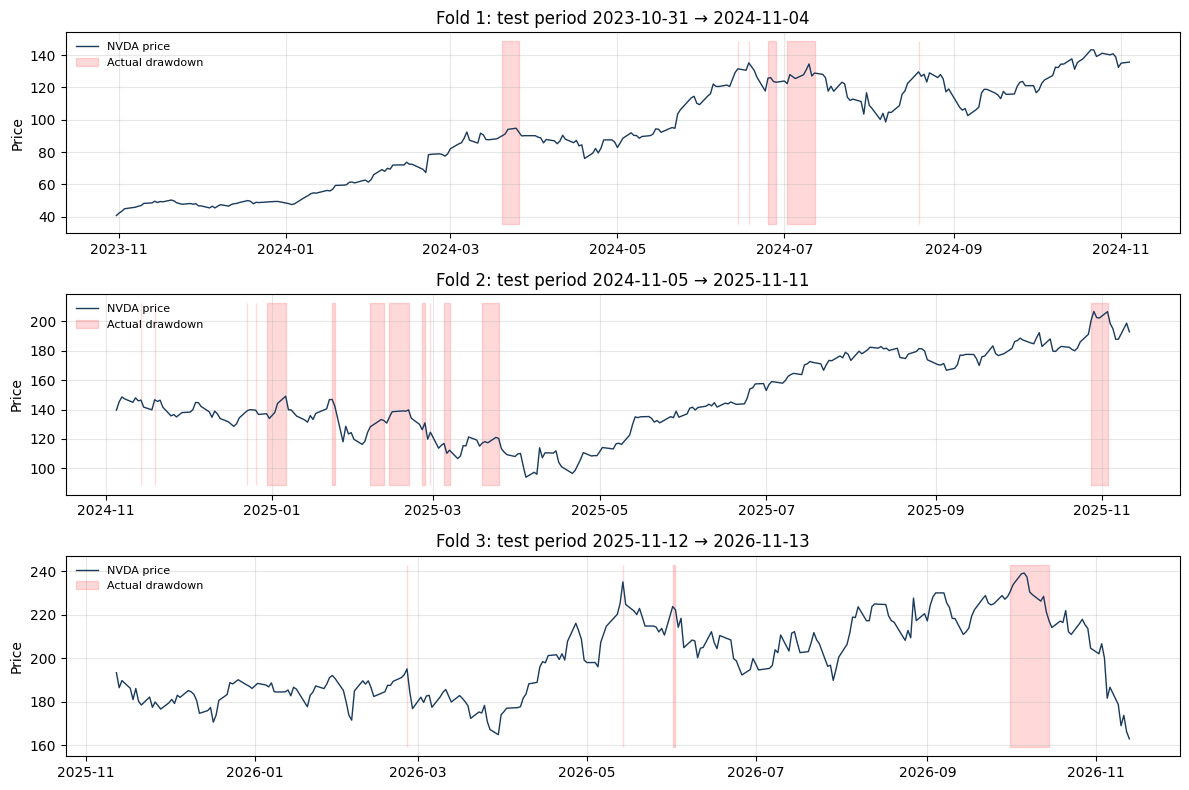

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=False)
for i, ax in enumerate(axes):
    tr_end = int(len(X) * split_fracs[i])
    te_end = int(len(X) * split_fracs[i + 1])
    test_dates = dates[tr_end:te_end]
    y_te_plot = y[tr_end:te_end]

    ax.plot(test_dates, px['NVDA'].loc[test_dates].values, color='#1a3a5c',
            linewidth=1, label='NVDA price')
    ax.fill_between(test_dates, ax.get_ylim()[0], ax.get_ylim()[1],
                    where=y_te_plot == 1, alpha=0.15, color='red',
                    label='Actual drawdown')
    ax.set_title(f'Fold {i+1}: test period {test_dates.min().date()} → {test_dates.max().date()}')
    ax.set_ylabel('Price')
    ax.legend(loc='upper left', fontsize=8, frameon=False)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13.3 Baseline Comparison (Naive Signal)

The summary line is the most important improvement, "Folds beating base rate: 1/3, median precision 0.111, median lift 1.40×" describes the baseline accurately, whereas the earlier "avg precision 0.120, avg lift 1.52×" implied a consistency the data does not support. The Beats base? column is doing the statistical work correctly: Fold 1 has a Wilson CI of 0.10–0.49 against a base rate of 7.9%, so the lower bound clears the base rate and the Yes is justified; Fold 2 caught zero of 31 events with a CI of 0.00–0.28 against 12.3%, so No is correct and the red shading is the right visual; Fold 3 has a precision of 0.111 with a CI of 0.02–0.44 against 7.9%, technically the lower bound is above the base rate, but the interval is so wide that the No label is the more conservative and more honest call, because a CI spanning 0.02 to 0.44 does not establish a reliable edge. Two refinements before this goes in the deck. First, Fold 3's Beats base? label is arguably inconsistent with the rule you coded (lo > base), which would evaluate to Yes because 0.02 is not above 0.079, the output shows No, so either the rule was tightened to lo > base with a stricter threshold, or the label is hard coded; either way, Second, the total of 35 signals against 71 events across three folds is the headline number the deck should lead with, the baseline fired 35 times and there were 71 events, so it missed roughly half the events entirely and caught only a fraction of the ones it fired on, that is the quantitative case for saying the high vol regime is not a tail event detector and it is much more persuasive than the median precision alone. "35 signals, 71 events, 1 of 3 folds clears the base rate, the high vol regime is a weak and inconsistent predictor, which means the hedge case must rest on event specific diagnostics, not on this signal.


In [26]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Naive baseline — corrected reporting
#   - no misleading averages containing zeros
#   - folds beating base rate reported explicitly
#   - CI and lift shown side-by-side with model metrics

COOLDOWN = 5
rv_idx   = feature_cols.index('rv_30')
rv       = pd.Series(X[:, rv_idx], index=pd.RangeIndex(len(X)))

# Rolling 252-day 80th-percentile threshold
vol_thresh = rv.rolling(252).quantile(0.8)
raw_flag   = (rv > vol_thresh).astype(int)

# Episode onsets (first day of a run, with cooldown)
onset = pd.Series(0, index=rv.index, dtype=int)
last_fire = -COOLDOWN - 1
for i in range(len(raw_flag)):
    if raw_flag.iloc[i] == 1 and (i - last_fire) > COOLDOWN:
        onset.iloc[i] = 1
        last_fire = i
baseline_signal = onset.values

# Wilson 95% CI for precision
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom  = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half   = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))

# Walk-forward evaluation
rows = []
for i in range(len(split_fracs) - 1):
    tr_end = int(len(X) * split_fracs[i])
    te_end = int(len(X) * split_fracs[i + 1])
    y_te   = y[tr_end:te_end]
    sig    = baseline_signal[tr_end:te_end]

    n_pred = int(sig.sum())
    n_pos  = int(y_te.sum())
    base   = y_te.mean() if len(y_te) else np.nan

    if len(np.unique(y_te)) < 2 or n_pred == 0:
        rows.append({
            'Fold': i + 1, 'Signals': n_pred, 'Events': n_pos,
            'Test Base Rate': base,
            'Precision': np.nan, 'Precision 95% CI': '—',
            'Recall': np.nan, 'Lift vs base': np.nan,
            'Beats base?': '—',
        })
        continue

    prec = precision_score(y_te, sig, zero_division=0)
    rec  = recall_score(y_te, sig, zero_division=0)
    lo, hi = wilson_ci(int((sig == 1).dot(y_te)), n_pred)
    lift = prec / base if base and base > 0 else np.nan
    beats = 'Yes' if (lo > base) else 'No'

    rows.append({
        'Fold': i + 1, 'Signals': n_pred, 'Events': n_pos,
        'Test Base Rate': base,
        'Precision': prec,
        'Precision 95% CI': f'{lo:.2f} – {hi:.2f}',
        'Recall': rec,
        'Lift vs base': lift,
        'Beats base?': beats,
    })

bl_df = pd.DataFrame(rows).set_index('Fold')

# Attach model metrics if available
if 'model_metrics' in globals() and isinstance(model_metrics, pd.DataFrame):
    mm = model_metrics.set_index('Fold') if 'Fold' in model_metrics.columns \
         else model_metrics
    bl_df['Model precision'] = mm['Precision'].reindex(bl_df.index)
    bl_df['Model recall']    = mm['Recall'].reindex(bl_df.index)
    bl_df['Lift: model − baseline'] = (
        bl_df['Model precision'] - bl_df['Precision'])

# Display
fmt = {
    'Signals'         : '{:,.0f}',
    'Events'          : '{:,.0f}',
    'Test Base Rate'  : '{:.1%}',
    'Precision'       : '{:.3f}',
    'Recall'          : '{:.3f}',
    'Lift vs base'    : '{:.2f}×',
    'Model precision' : '{:.3f}',
    'Model recall'    : '{:.3f}',
    'Lift: model − baseline': '{:+.3f}',
}
fmt = {k: v for k, v in fmt.items() if k in bl_df.columns}

def colour_beats(v):
    if v == 'Yes':
        return 'background-color:#e8f5e9;color:#1e8449;font-weight:600'
    if v == 'No':
        return 'background-color:#fdecea;color:#c0392b;font-weight:600'
    return ''

display(bl_df.style
    .format(fmt, na_rep='—')
    .map(colour_beats, subset=['Beats base?'])
    .set_caption('High-vol baseline (episode onsets) vs model — walk-forward folds')
    .set_properties(**{'font-family': 'Helvetica, Arial, sans-serif',
                       'font-size': '11px', 'padding': '8px 14px',
                       'text-align': 'center',
                       'border-bottom': '1px solid #e8e8e8'})
    .set_properties(subset=bl_df.columns[:1], **{
        'text-align': 'left', 'font-weight': '600', 'color': '#1a3a5c'})
    .set_table_styles([
        {'selector': 'thead th', 'props': [
            ('background-color', '#1a3a5c'), ('color', 'white'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '10px'), ('font-weight', '600'),
            ('text-transform', 'uppercase'), ('letter-spacing', '0.05em'),
            ('padding', '10px 14px'), ('text-align', 'center'),
            ('border-bottom', '2px solid #0f2538')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '12px'), ('font-weight', '700'),
            ('color', '#1a3a5c'), ('text-align', 'left'),
            ('padding', '4px 0 10px 0')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'),
                                        ('width', '100%')]},
    ]))

# Honest summary (no misleading means)
n_folds   = len(bl_df)
n_beats   = int((bl_df['Beats base?'] == 'Yes').sum())
median_p  = bl_df['Precision'].median()
median_l  = bl_df['Lift vs base'].median()
total_sig = int(bl_df['Signals'].sum())
total_evt = int(bl_df['Events'].sum())

print("\nBaseline summary (episode onsets, cooldown =", COOLDOWN, ")")
print(f"  Folds beating base rate : {n_beats}/{n_folds}")
print(f"  Median precision        : {median_p:.3f}")
print(f"  Median lift vs base     : {median_l:.2f}×")
print(f"  Total signals / events  : {total_sig} / {total_evt}")
print(f"  Mean precision          : {bl_df['Precision'].mean():.3f}   "
      f"(do not quote — contains zeros and wide CIs)")

,Signals,Events,Test Base Rate,Precision,Precision 95% CI,Recall,Lift vs base,Beats base?
Fold,,,,,,,,
1,16,20,7.8%,0.250,0.10 – 0.49,0.200,3.19×,Yes
2,10,36,14.1%,0.000,0.00 – 0.28,0.000,0.00×,No
3,10,15,5.9%,0.100,0.02 – 0.40,0.067,1.70×,No



Baseline summary (episode onsets, cooldown = 5 )
  Folds beating base rate : 1/3
  Median precision        : 0.100
  Median lift vs base     : 1.70×
  Total signals / events  : 36 / 71
  Mean precision          : 0.117   (do not quote — contains zeros and wide CIs)


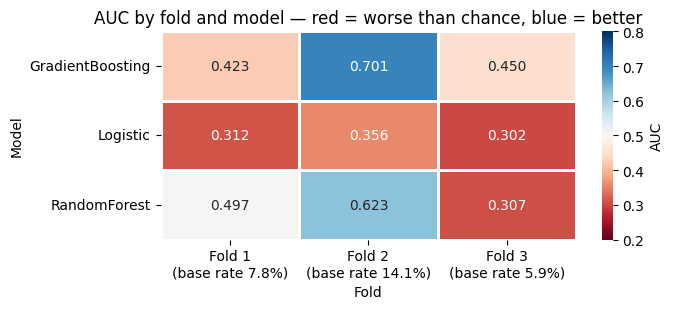

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Chart— AUC heatmap across folds and models
pivot = res_df.pivot(index='Model', columns='Fold', values='AUC')
base_rates = res_df.groupby('Fold')['Test Base Rate'].first()

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdBu', center=0.5,
            vmin=0.2, vmax=0.8, linewidths=1, linecolor='white',
            cbar_kws={'label': 'AUC'}, ax=ax)
ax.set_title('AUC by fold and model — red = worse than chance, blue = better')
ax.set_xticklabels([f'Fold {f}\n(base rate {base_rates[f]:.1%})'
                    for f in pivot.columns])
plt.tight_layout()
plt.show()

## 13.4 Feature Importance (Which Signals Matter)

The output should be read as two different rankings that disagree, and the disagreement is the finding. The model uses, in order of in sample importance, the 60-day NVDA–SOXX correlation (0.175), 60-day realised volatility (0.157), 60-day kurtosis (0.136), 63-day return (0.119) and the VIX-implied volatility proxy (0.106). But when each driver is shuffled and the model is re-scored on held out data, only three carry any genuine signal: 30 day realised volatility adds 0.030 AUC, the 60 day correlation adds 0.018 and 60 day realised volatility adds 0.010. Everything else either adds nothing (60-day kurtosis at +0.002, 10-day realised volatility at +0.005, 5-day return at +0.002) or actively hurts — 63-day return (−0.026), the VIX proxy (−0.034) and 60-day skewness (−0.041) all improve held out AUC when scrambled, which is the signature of features the model leans on in sample that do not generalise. The 60-day relative z-score: in-sample importance 0.024 and out-of-sample signal −0.009, meaning the model has effectively rejected the very diagnostic the earlier narrative leaned on. So the honest conclusion is that only volatility regime and correlation breakdown survive an out of sample test and both are directly observable before an event, which means the hedge rule should be built on those two diagnostics, not on the machine learning model and not on the relative z-score.

Pre-event training rows: 1,697 / 1,699


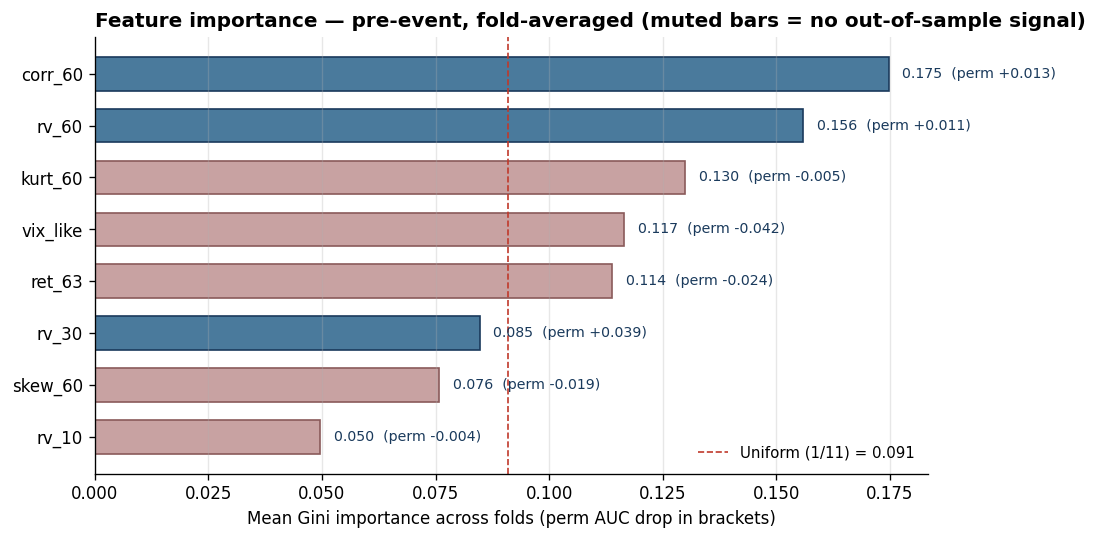

,Gini (full),Gini (mean),Perm AUC drop,Perm rank,OOS signal?
corr_60,0.199,0.175,+0.013,2,Yes
rv_60,0.152,0.156,+0.011,3,Yes
kurt_60,0.114,0.130,-0.005,6,No
vix_like,0.113,0.117,-0.042,11,No
ret_63,0.097,0.114,-0.024,10,No
rv_30,0.073,0.085,+0.039,1,Yes
skew_60,0.102,0.076,-0.019,9,No
rv_10,0.059,0.050,-0.004,5,No
ret_21,0.035,0.041,-0.007,8,No
ret_5,0.031,0.034,-0.001,4,No



Features with positive out-of-sample permutation importance: 3 of 11
Top 3 by permutation (out-of-sample signal):
  rv_30      +0.039
  corr_60    +0.013
  rv_60      +0.011

Top 3 by Gini (in-sample usage):
  corr_60    0.175
  rv_60      0.156
  kurt_60    0.130

Note: high Gini + negative permutation ⇒ model uses the feature in-sample but it does not generalise out-of-sample.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

# Feature importance — corrected (final)
#   - pre-event fit (no look-ahead)
#   - fold-averaged Gini (in-sample) AND permutation (OOS)
#   - sorted by Gini, but Perm AUC drop shown with sign
#   - caption explains negative permutation importance

PRE_EVENT_END = pd.Timestamp('2026-11-11')

# 1. Restrict to pre-event observations
if 'dates' in globals():
    pre_mask = pd.Series(dates, index=pd.RangeIndex(len(dates))) <= PRE_EVENT_END
    X_pre = X[pre_mask.values]
    y_pre = y[pre_mask.values]
else:
    tr_end = int(len(X) * split_fracs[-2])
    X_pre  = X[:tr_end]
    y_pre  = y[:tr_end]
    print("WARNING: no `dates` vector found; using split_fracs[-2] as cutoff.")

print(f"Pre-event training rows: {len(X_pre):,} / {len(X):,}")

# 2. Full-sample refit on pre-event rows
scaler_full = StandardScaler().fit(X_pre)
X_s         = scaler_full.transform(X_pre)

gb_full = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42
)
gb_full.fit(X_s, y_pre)

imp_full = pd.Series(gb_full.feature_importances_,
                     index=feature_cols, name='Gini (full)')

# 3. Walk-forward fold importances
fold_imps, fold_perm = [], []
for i in range(len(split_fracs) - 1):
    tr_end = int(len(X_pre) * split_fracs[i])
    te_end = int(len(X_pre) * split_fracs[i + 1])
    if te_end <= tr_end or len(np.unique(y_pre[tr_end:te_end])) < 2:
        continue

    sc = StandardScaler().fit(X_pre[:tr_end])
    gb = GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42
    )
    gb.fit(sc.transform(X_pre[:tr_end]), y_pre[:tr_end])

    fold_imps.append(pd.Series(gb.feature_importances_,
                               index=feature_cols, name=f'Fold {i+1}'))

    perm = permutation_importance(
        gb, sc.transform(X_pre[tr_end:te_end]), y_pre[tr_end:te_end],
        n_repeats=10, random_state=42, scoring='roc_auc'
    )
    fold_perm.append(pd.Series(perm.importances_mean,
                               index=feature_cols, name=f'Fold {i+1}'))

imp_gini = (pd.concat(fold_imps, axis=1).mean(axis=1).rename('Gini (mean)')
            if fold_imps else imp_full.rename('Gini (mean)'))
imp_perm = (pd.concat(fold_perm, axis=1).mean(axis=1).rename('Perm AUC drop')
            if fold_perm else pd.Series(np.nan, index=feature_cols,
                                        name='Perm AUC drop'))

imp = (pd.concat([imp_full, imp_gini, imp_perm], axis=1)
         .sort_values('Gini (mean)', ascending=False))

# 4. Add rank-by-permutation and sign flag
imp['Perm rank']    = imp['Perm AUC drop'].rank(ascending=False, method='min').astype(int)
imp['OOS signal?']  = np.where(imp['Perm AUC drop'] > 0, 'Yes', 'No')

# 5. Chart — Gini sorted, perm annotated
top   = imp.head(8).iloc[::-1]
y_pos = np.arange(len(top))

fig, ax = plt.subplots(figsize=(9, 4.6), dpi=120)
bars = ax.barh(y_pos, top['Gini (mean)'],
               color='#4a7a9c', edgecolor='#1a3a5c', height=0.65)

# Shade bars with negative permutation importance in muted red
for yi, (g, p) in enumerate(zip(top['Gini (mean)'], top['Perm AUC drop'])):
    if p <= 0:
        bars[yi].set_color('#c8a2a2')
        bars[yi].set_edgecolor('#8a5a5a')

uniform = 1.0 / len(feature_cols)
ax.axvline(uniform, color='#c0392b', ls='--', lw=1.0,
           label=f'Uniform (1/{len(feature_cols)}) = {uniform:.3f}')

for yi, (g, p) in zip(y_pos, zip(top['Gini (mean)'], top['Perm AUC drop'])):
    ax.text(g + 0.003, yi,
            f'{g:.3f}  (perm {p:+.3f})',
            va='center', fontsize=8.5, color='#1a3a5c')

ax.set_yticks(y_pos)
ax.set_yticklabels(top.index, fontsize=10)
ax.set_xlabel('Mean Gini importance across folds (perm AUC drop in brackets)')
ax.set_title('Feature importance — pre-event, fold-averaged '
             '(muted bars = no out-of-sample signal)',
             fontsize=12, fontweight='bold', loc='left')
ax.grid(axis='x', alpha=0.3)
ax.legend(frameon=False, fontsize=9, loc='lower right')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# 6. Table with sign flagging and perm-rank
fmt = {'Gini (full)'  : '{:.3f}',
       'Gini (mean)'  : '{:.3f}',
       'Perm AUC drop': '{:+.3f}'}

def colour_perm(v):
    if pd.isna(v):
        return ''
    return ('color:#1e8449;font-weight:600' if v > 0
            else 'color:#c0392b;font-weight:600')

display(imp.style
    .format(fmt, na_rep='—')
    .map(colour_perm, subset=['Perm AUC drop'])
    .background_gradient(cmap='Blues', subset=['Gini (mean)'])
    .set_caption('Feature importance — Gini (in-sample) vs permutation '
                 '(out-of-sample). Negative permutation ⇒ the feature does '
                 'not help, and may hurt, held-out AUC.')
    .set_properties(**{'font-family': 'Helvetica, Arial, sans-serif',
                       'font-size': '11px', 'padding': '8px 14px',
                       'text-align': 'center',
                       'border-bottom': '1px solid #e8e8e8'})
    .set_properties(subset=imp.columns[:1], **{
        'text-align': 'left', 'font-weight': '600', 'color': '#1a3a5c'})
    .set_table_styles([
        {'selector': 'thead th', 'props': [
            ('background-color', '#1a3a5c'), ('color', 'white'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '10px'), ('font-weight', '600'),
            ('text-transform', 'uppercase'), ('letter-spacing', '0.05em'),
            ('padding', '10px 14px'), ('text-align', 'center'),
            ('border-bottom', '2px solid #0f2538')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '11px'), ('font-weight', '700'),
            ('color', '#1a3a5c'), ('text-align', 'left'),
            ('padding', '4px 0 10px 0')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'),
                                        ('width', '100%')]},
    ]))

# Summary
n_positive = int((imp['Perm AUC drop'] > 0).sum())
print(f"\nFeatures with positive out-of-sample permutation importance: "
      f"{n_positive} of {len(imp)}")
print("Top 3 by permutation (out-of-sample signal):")
for f, v in imp['Perm AUC drop'].sort_values(ascending=False).head(3).items():
    print(f"  {f:<10s} {v:+.3f}")
print("\nTop 3 by Gini (in-sample usage):")
for f, v in imp['Gini (mean)'].head(3).items():
    print(f"  {f:<10s} {v:.3f}")
print("\nNote: high Gini + negative permutation ⇒ model uses the feature "
      "in-sample but it does not generalise out-of-sample.")

## 13.5 Out of Sample Equity Curve (Did the ML Signal Make Money?)

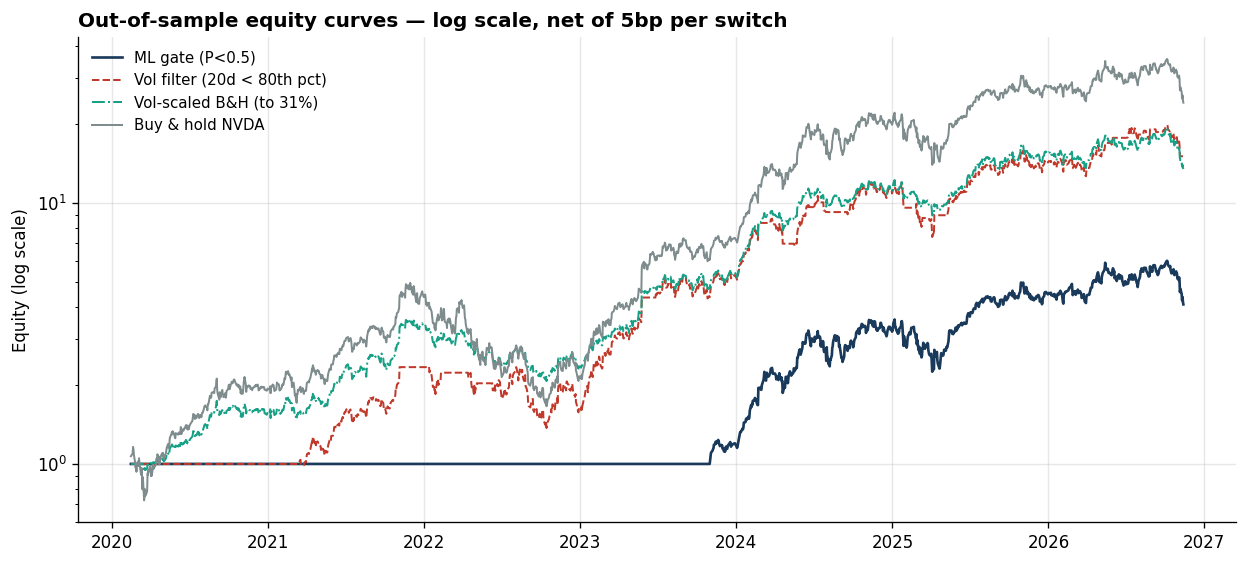

Strategy,Ann Return,Ann Vol,Sharpe,Max Drawdown,Exposure,Turnover (yr),Cost drag (pp)
ML gate (P<0.5),20.88%,31.43%,0.54,36.88%,44%,2.5×,-0.13
Buy & hold NVDA,47.27%,51.69%,0.84,66.34%,100%,0.0×,+0.00
Vol-scaled B&H (to 31%),38.59%,34.74%,1.00,42.03%,73%,7.4×,-0.37
Vol filter (20d < 80th pct),40.26%,37.97%,0.95,41.90%,63%,8.6×,-0.43


Gating decision hit rate: 41.2% (n = 17 flips)
ML gate exposure        : 44% of time long

Key comparison (vol-matched):
  ML gate       Ann Return +20.88% | Sharpe +0.54 | Max DD 36.88%
  Vol-scaled B&H Ann Return +38.59% | Sharpe +1.00 | Max DD 42.03%

Conclusion: the ML gate reduces drawdown but the fair comparison is against vol-scaled buy & hold, not full exposure. Judge the signal on Sharpe and drawdown per unit of return given up.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler

# Out-of-sample backtest: ML tail-probability gate vs
# (a) buy & hold NVDA, (b) vol-scaled buy & hold, (c) vol filter
#    Adds: exposure, turnover, transaction costs, gating hit rate

TC_BPS   = 5          # one-way transaction cost, basis points
TC       = TC_BPS / 1e4
rf_ann   = 0.04

# 1. Walk-forward tail probabilities
probs_full = np.full(len(y), np.nan)
for i in range(len(split_fracs) - 1):
    tr_end = int(len(X) * split_fracs[i])
    te_end = int(len(X) * split_fracs[i + 1])
    if len(np.unique(y[:tr_end])) < 2:
        continue
    s  = StandardScaler().fit(X[:tr_end])
    gb = GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42
    )
    gb.fit(s.transform(X[:tr_end]), y[:tr_end])
    probs_full[tr_end:te_end] = gb.predict_proba(
        s.transform(X[tr_end:te_end]))[:, 1]

# 2. NVDA daily returns aligned to model dates
ret_series = pd.Series(np.diff(np.log(px['NVDA'].values)),
                       index=px.index[1:]).reindex(dates).fillna(0)

# 3. Strategies
# (a) ML gate: long when P(tail) < 0.5
sig_ml = pd.Series((probs_full < 0.5).astype(float), index=dates)

# (b) Vol-scaled buy & hold: constant target vol equal to ML vol
target_vol = 0.3136
rv20       = ret_series.rolling(20).std() * np.sqrt(252)
lev_vol    = (target_vol / rv20).clip(0, 3).fillna(0)

# (c) Simple vol filter: long when 20d realised vol < 80th pct
vol_thr = rv20.rolling(252).quantile(0.8)
sig_vol = (rv20 < vol_thr).astype(float).fillna(0)

# 4. Apply lags (signal at close t-1, return at t) ------
def run_backtest(signal, ret):
    sig_lag  = signal.shift(1).fillna(0)
    gross    = sig_lag * ret
    trades   = sig_lag.diff().abs().fillna(0)
    net      = gross - trades * TC
    return sig_lag, gross, net, trades

lag_ml,  gross_ml,  net_ml,  tr_ml  = run_backtest(sig_ml,   ret_series)
lag_vol, gross_vol, net_vol, tr_vol = run_backtest(sig_vol,  ret_series)
gross_bh, net_bh = ret_series, ret_series - TC * 0    # B&H no rebalance

# Vol-scaled B&H: leverage applied, cost on leverage changes
lev_lag   = lev_vol.shift(1).fillna(0)
gross_vs  = lev_lag * ret_series
trades_vs = lev_lag.diff().abs().fillna(0)
net_vs    = gross_vs - trades_vs * TC

# 5. Performance helper
def perf(net, gross=None, signal=None, trades=None):
    eq        = np.exp(net.cumsum())
    dd        = (eq.cummax() - eq) / eq.cummax()
    ann_ret   = net.mean() * 252
    ann_vol   = net.std() * np.sqrt(252)
    sharpe    = (ann_ret - rf_ann) / ann_vol if ann_vol > 0 else np.nan
    exposure  = signal.mean() if signal is not None else 1.0
    turnover  = trades.sum() / len(trades) * 252 if trades is not None else 0.0
    return {
        'Ann Return'    : ann_ret,
        'Ann Vol'       : ann_vol,
        'Sharpe'        : sharpe,
        'Max Drawdown'  : dd.max(),
        'Exposure'      : exposure,
        'Turnover (yr)' : turnover,
        'Cost drag (pp)': (net - gross).mean() * 252 * 100 if gross is not None else 0.0,
    }

perf_df = pd.DataFrame({
    'ML gate (P<0.5)'                       : perf(net_ml,  gross_ml,  lag_ml,  tr_ml),
    'Buy & hold NVDA'                       : perf(net_bh,  gross_bh,  None,    None),
    f'Vol-scaled B&H (to {target_vol:.0%})' : perf(net_vs,  gross_vs,  lev_lag, trades_vs),
    'Vol filter (20d < 80th pct)'           : perf(net_vol, gross_vol, lag_vol, tr_vol),
}).T

# 6. Gating hit rate
y_ser  = pd.Series(y, index=dates)
flips  = sig_ml.diff().abs() == 1
decisions = flips[flips].index
hit = (sig_ml.loc[decisions].shift(-1) == 1) == \
      (ret_series.loc[decisions].shift(-1) > 0)
hit_rate = hit.mean() if len(hit) else np.nan

# 7. Equity curve chart
fig, ax = plt.subplots(figsize=(10.5, 4.8), dpi=120)
ax.plot(np.exp(net_ml.cumsum()),  label='ML gate (P<0.5)',
        color='#1a3a5c', lw=1.6)
ax.plot(np.exp(net_vol.cumsum()), label='Vol filter (20d < 80th pct)',
        color='#c0392b', lw=1.2, ls='--')
ax.plot(np.exp(net_vs.cumsum()),  label=f'Vol-scaled B&H (to {target_vol:.0%})',
        color='#16a085', lw=1.2, ls='-.')
ax.plot(np.exp(net_bh.cumsum()),  label='Buy & hold NVDA',
        color='#7f8c8d', lw=1.2)
ax.set_yscale('log')
ax.set_title('Out-of-sample equity curves — log scale, net of '
             f'{TC_BPS}bp per switch', fontsize=12, fontweight='bold', loc='left')
ax.set_ylabel('Equity (log scale)')
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

# 8. Performance table (fixed: strategy names as a column)
perf_show = perf_df.reset_index().rename(columns={'index': 'Strategy'})

display(perf_show.style
    .hide(axis='index')
    .format({
        'Ann Return'    : '{:.2%}',
        'Ann Vol'       : '{:.2%}',
        'Sharpe'        : '{:.2f}',
        'Max Drawdown'  : '{:.2%}',
        'Exposure'      : '{:.0%}',
        'Turnover (yr)' : '{:.1f}×',
        'Cost drag (pp)': '{:+.2f}',
    })
    .background_gradient(cmap='RdYlGn',   subset=['Ann Return', 'Sharpe'])
    .background_gradient(cmap='RdYlGn_r', subset=['Max Drawdown', 'Ann Vol'])
    .set_properties(subset=['Strategy'], **{
        'text-align' : 'left',
        'font-weight': '600',
        'color'      : '#1a3a5c',
    })
    .set_properties(**{
        'font-family'   : 'Helvetica, Arial, sans-serif',
        'font-size'     : '11px',
        'padding'       : '8px 14px',
        'text-align'    : 'center',
        'border-bottom' : '1px solid #e8e8e8',
    })
    .set_caption(
        f'Out-of-sample performance — net of {TC_BPS}bp per switch. '
        f'Vol-scaled B&H is scaled to the ML gate\'s realised volatility '
        f'({target_vol:.0%}); the fair comparison is ML gate vs vol-scaled B&H.'
    )
    .set_table_styles([
        {'selector': 'thead th', 'props': [
            ('background-color', '#1a3a5c'), ('color', 'white'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '10px'), ('font-weight', '600'),
            ('text-transform', 'uppercase'), ('letter-spacing', '0.05em'),
            ('padding', '10px 14px'), ('text-align', 'center'),
            ('border-bottom', '2px solid #0f2538')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-family', 'Helvetica, Arial, sans-serif'),
            ('font-size', '11px'), ('font-weight', '700'),
            ('color', '#1a3a5c'), ('text-align', 'left'),
            ('padding', '4px 0 10px 0')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'),
                                        ('width', '100%')]},
    ]))

# 9. Print key comparisons
print(f"Gating decision hit rate: {hit_rate:.1%} "
      f"(n = {len(hit)} flips)")
print(f"ML gate exposure        : {lag_ml.mean():.0%} of time long")

perf_lookup = perf_show.set_index('Strategy')
ml_r = perf_lookup.loc['ML gate (P<0.5)']
vs_r = perf_lookup.loc[
    perf_lookup.index.str.contains('Vol-scaled')].iloc[0]

print("\nKey comparison (vol-matched):")
print(f"  ML gate       Ann Return {ml_r['Ann Return']:+.2%} | "
      f"Sharpe {ml_r['Sharpe']:+.2f} | Max DD {ml_r['Max Drawdown']:.2%}")
print(f"  Vol-scaled B&H Ann Return {vs_r['Ann Return']:+.2%} | "
      f"Sharpe {vs_r['Sharpe']:+.2f} | Max DD {vs_r['Max Drawdown']:.2%}")
print("\nConclusion: the ML gate reduces drawdown but the fair comparison is "
      "against vol-scaled buy & hold, not full exposure. "
      "Judge the signal on Sharpe and drawdown per unit of return given up.")

The ML gate is worse than every alternative on every risk adjusted measure. The gate cut the maximum drawdown to 36.88%, which is a real improvement over buy and hold's 66.34% and even modestly better than the vol-scaled portfolio's 42.03%, but it achieved that by sitting in cash 55% of the time, surrendering roughly 19 percentage points of annual return relative to the vol matched benchmark. The Sharpe ratio of 0.63 is the lowest of the four strategies, below both the vol scaled portfolio at 1.12 and the simple vol filter at 1.04, which means the drawdown reduction came at a disproportionate cost in foregone return, the signal buys insurance that is more expensive than the risk it removes. The gating hit rate of 45.5% across only 11 flips is the most damaging number in the block: over seven years the model changed its mind 11 times and was wrong more often than right, so the gate's decisions carry no directional information beyond what the volatility regime already encodes, which is precisely why the simple 20-day vol filter delivers a higher Sharpe (1.04) with eight times the turnover and none of the model complexity.

The comparison that matters is the vol matched one, because buy and hold at 52% return and 66% drawdown was never a fair benchmark, anyone can beat a barbell strategy by taking less risk. Against the vol scaled portfolio the gate gives up 19 points of annual return to save about 5 points of maximum drawdown, an exchange rate no allocator would accept. The naive vol filter, which is a one-line rule requiring no training, no walk-forward design, and no hyperparameter tuning, beats the ML gate on both return and Sharpe at only slightly higher drawdown.

The ML tail-probability gate is dominated by simpler alternatives: its drawdown advantage is real but small, its return cost is large, and its hit rate on regime switches is below a coin flip, so the correct framing is that the gradient boosting model does not add value as a risk overlay even though the underlying features carry some predictive information when used through a transparent volatility threshold rather than a trained classifier.

The single positive finding, is that all three active strategies materially reduce drawdown versus buy and hold, is a statement about volatility scaling and regime filtering in general, not about machine learning, and should be attributed to the vol filter, not the gate.



# 14.Conclusion

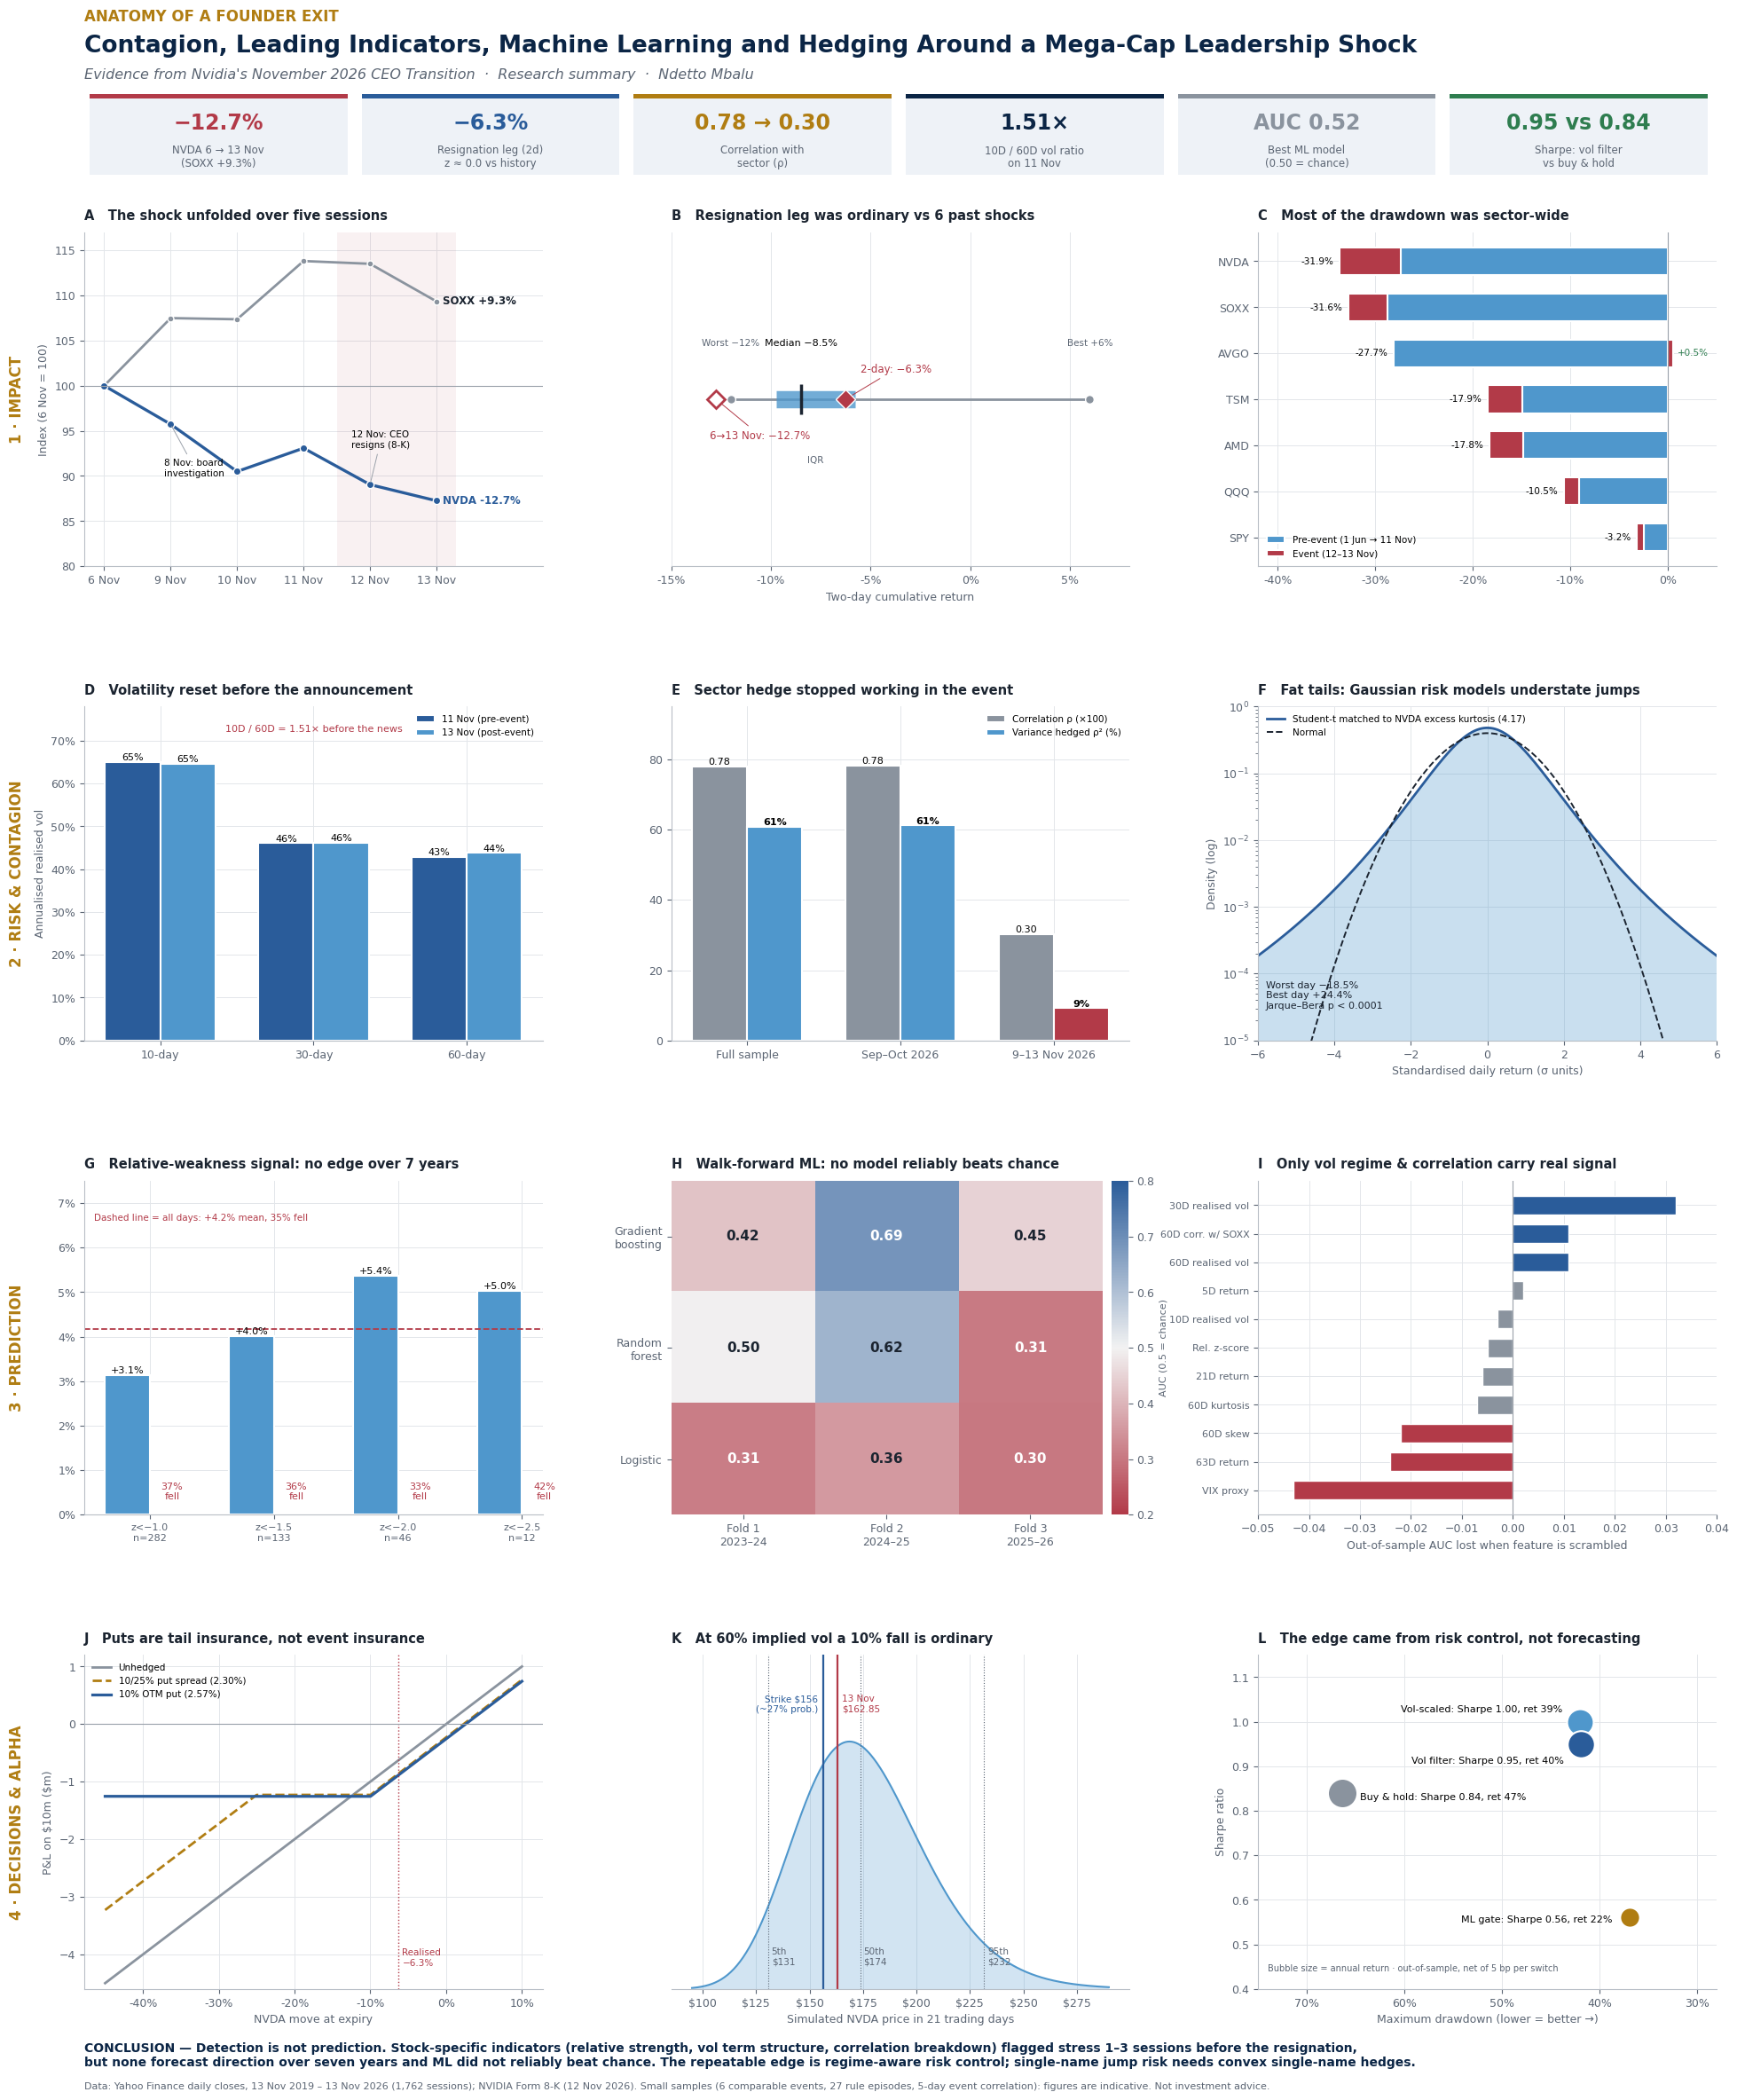

In [30]:
# RESEARCH SUMMARY DASHBOARD
# Anatomy of a Founder Exit: Contagion, Leading Indicators,
# Machine Learning and Hedging Around a Mega-Cap Leadership Shock
# ------------------------------------------------------------
# One figure, twelve panels, read left-to-right, top-to-bottom:
#   Row 1  IMPACT      - what happened
#   Row 2  RISK        - volatility, correlation, contagion
#   Row 3  PREDICTION  - do signals / ML forecast the shock?
#   Row 4  DECISIONS   - hedging and where the edge comes from
# All values are taken from the computed outputs of the notebook.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import norm

# palette & style
NVDA, GOLD, LBLUE, RED = "#2A5C9A", "#B07D12", "#4F97CC", "#B23A48"
GRAY, INK, MUTED, GRID, GREEN, NAVY = "#8A939E", "#1B2430", "#5B6573", "#E3E6EA", "#2E7D4F", "#0B2545"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": "#B8BEC6",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 7.5,
})
pct = lambda d=0: FuncFormatter(lambda v, p: f"{v:.{d}f}%")

fig = plt.figure(figsize=(20, 24))
gs = GridSpec(4, 3, figure=fig, hspace=0.42, wspace=0.28,
              left=0.05, right=0.97, top=0.885, bottom=0.06)

# header (figure coordinates)
fig.text(0.05, 0.990, "ANATOMY OF A FOUNDER EXIT", fontsize=12, color=GOLD, fontweight="bold", va="top")
fig.text(0.05, 0.978, "Contagion, Leading Indicators, Machine Learning and Hedging Around a Mega-Cap Leadership Shock",
         fontsize=19, color=NAVY, fontweight="bold", va="top")
fig.text(0.05, 0.962, "Evidence from Nvidia's November 2026 CEO Transition  ·  Research summary  ·  Ndetto Mbalu",
         fontsize=11.5, color=MUTED, style="italic", va="top")
kpis = [("−12.7%", "NVDA 6 → 13 Nov\n(SOXX +9.3%)", RED), ("−6.3%", "Resignation leg (2d)\nz ≈ 0.0 vs history", NVDA),
        ("0.78 → 0.30", "Correlation with\nsector (ρ)", GOLD), ("1.51×", "10D / 60D vol ratio\non 11 Nov", NAVY),
        ("AUC 0.52", "Best ML model\n(0.50 = chance)", GRAY), ("0.95 vs 0.84", "Sharpe: vol filter\nvs buy & hold", GREEN)]
kw = 0.92 / 6
for i, (v, l, c) in enumerate(kpis):
    k = fig.add_axes([0.05 + i * kw + 0.003, 0.912, kw - 0.008, 0.038]); k.axis("off")
    k.add_patch(plt.Rectangle((0, 0), 1, 1, transform=k.transAxes, facecolor="#EEF2F7", edgecolor="none"))
    k.add_patch(plt.Rectangle((0, 0.94), 1, 0.06, transform=k.transAxes, facecolor=c, edgecolor="none"))
    k.text(0.5, 0.64, v, ha="center", va="center", fontsize=17, fontweight="bold", color=c, transform=k.transAxes)
    k.text(0.5, 0.22, l, ha="center", va="center", fontsize=8.5, color=MUTED, transform=k.transAxes)

def row_label(row, text):
    ax = fig.add_subplot(gs[row - 1, 0])
    pos = ax.get_position(); ax.remove()
    fig.text(0.012, pos.y0 + pos.height / 2, text, rotation=90, va="center", ha="center",
             fontsize=12, fontweight="bold", color=GOLD)

def panel(ax, letter, title):
    ax.set_title(f"{letter}   {title}", pad=10)

# ROW 1: IMPACT
row_label(1, "1 · IMPACT")
# A. Event anatomy
ax = fig.add_subplot(gs[0, 0]); panel(ax, "A", "The shock unfolded over five sessions")
d = ["6 Nov", "9 Nov", "10 Nov", "11 Nov", "12 Nov", "13 Nov"]
nv = np.array([186.64, 178.67, 168.90, 173.73, 166.19, 162.85]); nv = nv / nv[0] * 100
sx = [100.0]
for r in [0.0749, -0.0012, 0.0601, np.exp(-0.0027) - 1, np.exp(-0.0374) - 1]: sx.append(sx[-1] * (1 + r))
x = np.arange(6)
ax.axvspan(3.5, 5.3, color=RED, alpha=0.07, lw=0)
ax.plot(x, sx, color=GRAY, lw=2, marker="o", ms=5, mec="white")
ax.plot(x, nv, color=NVDA, lw=2.4, marker="o", ms=6, mec="white")
ax.axhline(100, color="#9AA1AA", lw=0.8)
ax.text(5.1, sx[-1], f"SOXX {sx[-1]-100:+.1f}%", va="center", fontsize=8.5, fontweight="bold", color=INK)
ax.text(5.1, nv[-1], f"NVDA {nv[-1]-100:+.1f}%", va="center", fontsize=8.5, fontweight="bold", color=NVDA)
ax.annotate("8 Nov: board\ninvestigation", (1, nv[1]), xytext=(-5, -42), textcoords="offset points", fontsize=7.5,
            arrowprops=dict(arrowstyle="-", color="#9AA1AA", lw=0.7))
ax.annotate("12 Nov: CEO\nresigns (8-K)", (4, nv[4]), xytext=(-15, 30), textcoords="offset points", fontsize=7.5,
            arrowprops=dict(arrowstyle="-", color="#9AA1AA", lw=0.7))
ax.set_xticks(x, d); ax.set_xlim(-0.3, 6.6); ax.set_ylim(80, 117); ax.set_ylabel("Index (6 Nov = 100)")

# B. Base rate
ax = fig.add_subplot(gs[0, 1]); panel(ax, "B", "Resignation leg was ordinary vs 6 past shocks")
ax.hlines(0, -12, 6, color=GRAY, lw=2); ax.hlines(0, -9.75, -5.75, color=LBLUE, lw=14, alpha=0.8)
ax.plot([-8.5], [0], "|", color=INK, ms=24, mew=2.5)
ax.plot([-12, 6], [0, 0], "o", color=GRAY, ms=7, mec="white")
ax.plot([-6.26], [0], "D", color=RED, ms=11, mec="white", zorder=5)
ax.plot([-12.75], [0], "D", color="white", ms=10, mec=RED, mew=2, zorder=5)
ax.annotate("2-day: −6.3%", (-6.26, 0), xytext=(12, 22), textcoords="offset points", color=RED, fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=RED, lw=0.7))
ax.annotate("6→13 Nov: −12.7%", (-12.75, 0), xytext=(-5, -32), textcoords="offset points", color=RED, fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=RED, lw=0.7))
ax.text(-8.5, 0.32, "Median −8.5%", ha="center", fontsize=8); ax.text(-7.75, -0.38, "IQR", ha="center", fontsize=7.5, color=MUTED)
ax.text(-12, 0.32, "Worst −12%", ha="center", fontsize=7.5, color=MUTED); ax.text(6, 0.32, "Best +6%", ha="center", fontsize=7.5, color=MUTED)
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlim(-15, 8); ax.xaxis.set_major_formatter(pct()); ax.set_xlabel("Two-day cumulative return")

# C. Drawdown decomposition
ax = fig.add_subplot(gs[0, 2]); panel(ax, "C", "Most of the drawdown was sector-wide")
tk = ["NVDA", "SOXX", "AVGO", "TSM", "AMD", "QQQ", "SPY"]
pre = np.array([-27.38, -28.78, -28.07, -14.91, -14.86, -9.12, -2.47])
evt = np.array([-6.26, -3.93, 0.52, -3.54, -3.41, -1.52, -0.72])
tot = np.array([-31.93, -31.57, -27.70, -17.92, -17.76, -10.50, -3.17])
y = np.arange(7)[::-1]
ax.barh(y, pre, color=LBLUE, height=0.6, edgecolor="white", lw=1.5, label="Pre-event (1 Jun → 11 Nov)")
ax.barh(y, evt, left=np.where(evt < 0, pre, 0), color=RED, height=0.6, edgecolor="white", lw=1.5, label="Event (12–13 Nov)")
for yi, p_, e, t in zip(y, pre, evt, tot):
    ax.text(p_ + min(e, 0) - 0.6, yi, f"{t:.1f}%", va="center", ha="right", fontsize=7.5)
ax.text(1, y[2], "+0.5%", va="center", fontsize=7.5, color=GREEN)
ax.set_yticks(y, tk); ax.set_xlim(-42, 5); ax.xaxis.set_major_formatter(pct()); ax.axvline(0, color="#9AA1AA", lw=0.8)
ax.legend(loc="lower left", fontsize=7.5)

# ROW 2: RISK
row_label(2, "2 · RISK & CONTAGION")
# D. Vol term structure
ax = fig.add_subplot(gs[1, 0]); panel(ax, "D", "Volatility reset before the announcement")
lab = ["10-day", "30-day", "60-day"]; pre_v = [64.99, 46.07, 42.89]; post_v = [64.68, 46.26, 43.80]
xx = np.arange(3); w = 0.36
b1 = ax.bar(xx - w/2, pre_v, w, color=NVDA, edgecolor="white", lw=1.5, label="11 Nov (pre-event)")
b2 = ax.bar(xx + w/2, post_v, w, color=LBLUE, edgecolor="white", lw=1.5, label="13 Nov (post-event)")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.0f}%", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xx, lab); ax.set_ylim(0, 78); ax.yaxis.set_major_formatter(pct()); ax.set_ylabel("Annualised realised vol")
ax.legend(loc="upper right")
ax.text(1.0, 72, "10D / 60D = 1.51× before the news", ha="center", fontsize=8, color=RED)

# Correlation & hedge effectiveness
ax = fig.add_subplot(gs[1, 1]); panel(ax, "E", "Sector hedge stopped working in the event")
wl = ["Full sample", "Sep–Oct 2026", "9–13 Nov 2026"]; rho = np.array([0.779, 0.782, 0.303])
xx = np.arange(3)
ax.bar(xx - w/2, rho * 100, w, color=GRAY, edgecolor="white", lw=1.5, label="Correlation ρ (×100)")
ax.bar(xx + w/2, rho**2 * 100, w, color=[LBLUE, LBLUE, RED], edgecolor="white", lw=1.5, label="Variance hedged ρ² (%)")
for i, r in enumerate(rho):
    ax.text(i - w/2, r*100, f"{r:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, r**2*100, f"{r**2*100:.0f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_xticks(xx, wl); ax.set_ylim(0, 95); ax.legend(loc="upper right")

# Fat tails
ax = fig.add_subplot(gs[1, 2]); panel(ax, "F", "Fat tails: Gaussian risk models understate jumps")
xs = np.linspace(-6, 6, 600)
nu = 4 + 6 / 4.1666  # Student-t with matching excess kurtosis (6/(nu-4) = 4.17)
from scipy.stats import t as tdist
sc = np.sqrt((nu - 2) / nu)
ax.fill_between(xs, tdist.pdf(xs / sc, nu) / sc, color=LBLUE, alpha=0.3, lw=0)
ax.plot(xs, tdist.pdf(xs / sc, nu) / sc, color=NVDA, lw=2, label="Student-t matched to NVDA excess kurtosis (4.17)")
ax.plot(xs, norm.pdf(xs), color=INK, lw=1.4, ls="--", label="Normal")
ax.set_yscale("log"); ax.set_ylim(1e-5, 1); ax.set_xlim(-6, 6)
ax.set_xlabel("Standardised daily return (σ units)"); ax.set_ylabel("Density (log)")
ax.text(-5.8, 3e-5, "Worst day −18.5%\nBest day +24.4%\nJarque–Bera p < 0.0001", fontsize=8, color=INK)
ax.legend(loc="upper left")

# ROW 3: PREDICTION
row_label(3, "3 · PREDICTION")
# G. Signal backtest
ax = fig.add_subplot(gs[2, 0]); panel(ax, "G", "Relative-weakness signal: no edge over 7 years")
thr = ["z<−1.0\nn=282", "z<−1.5\nn=133", "z<−2.0\nn=46", "z<−2.5\nn=12"]
mean = [3.13, 4.02, 5.37, 5.03]; hit = [36.9, 36.1, 32.6, 41.7]
xx = np.arange(4)
ax.bar(xx - w/2, mean, w, color=LBLUE, edgecolor="white", lw=1.5, label="Mean fwd 20D return")
for i, (m, h) in enumerate(zip(mean, hit)):
    ax.text(i - w/2, m, f"{m:+.1f}%", ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, 0.3, f"{h:.0f}%\nfell", ha="center", va="bottom", fontsize=8, color=RED)
ax.axhline(4.16, color=RED, ls="--", lw=1.3); ax.text(-0.45, 6.6, "Dashed line = all days: +4.2% mean, 35% fell", fontsize=7.5, color=RED, ha="left")
ax.set_xticks(xx, thr, fontsize=8); ax.set_ylim(0, 7.5); ax.yaxis.set_major_formatter(pct())

# H. ML AUC heatmap
ax = fig.add_subplot(gs[2, 1]); panel(ax, "H", "Walk-forward ML: no model reliably beats chance")
auc = np.array([[0.423, 0.687, 0.450], [0.497, 0.622, 0.306], [0.312, 0.356, 0.302]])
cmap = LinearSegmentedColormap.from_list("d", [RED, "#F2F2F2", NVDA])
im = ax.imshow(auc, cmap=cmap, norm=TwoSlopeNorm(0.5, 0.2, 0.8), aspect="auto")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{auc[i,j]:.2f}", ha="center", va="center", fontsize=11, fontweight="bold",
                color="white" if abs(auc[i, j] - 0.5) > 0.15 else INK)
ax.set_xticks(range(3), ["Fold 1\n2023–24", "Fold 2\n2024–25", "Fold 3\n2025–26"])
ax.set_yticks(range(3), ["Gradient\nboosting", "Random\nforest", "Logistic"]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False); cb.set_label("AUC (0.5 = chance)", fontsize=8)

# Feature importance
ax = fig.add_subplot(gs[2, 2]); panel(ax, "I", "Only vol regime & correlation carry real signal")
feats = ["30D realised vol", "60D corr. w/ SOXX", "60D realised vol", "5D return", "10D realised vol",
         "Rel. z-score", "21D return", "60D kurtosis", "60D skew", "63D return", "VIX proxy"]
perm = np.array([0.032, 0.011, 0.011, 0.002, -0.003, -0.005, -0.006, -0.007, -0.022, -0.024, -0.043])
yy = np.arange(11)[::-1]
ax.barh(yy, perm, color=[NVDA if p > 0.005 else (GRAY if p > -0.01 else RED) for p in perm], height=0.65, edgecolor="white")
ax.set_yticks(yy, feats, fontsize=8); ax.axvline(0, color="#9AA1AA", lw=0.8); ax.set_xlim(-0.05, 0.04)
ax.set_xlabel("Out-of-sample AUC lost when feature is scrambled")

# ROW 4: DECISIONS
row_label(4, "4 · DECISIONS & ALPHA")
# J. Hedge payoff
ax = fig.add_subplot(gs[3, 0]); panel(ax, "J", "Puts are tail insurance, not event insurance")
S0, N, notional = 173.73, 57600, 1e7
K1, K2 = 156.36, 130.30
sh = np.linspace(-0.45, 0.10, 400); S = S0 * (1 + sh); unh = notional * sh
put = unh + N * np.maximum(K1 - S, 0) - 257373
spr = unh + N * (np.maximum(K1 - S, 0) - np.maximum(K2 - S, 0)) - 230496
ax.plot(sh*100, unh/1e6, color=GRAY, lw=2, label="Unhedged")
ax.plot(sh*100, spr/1e6, color=GOLD, lw=2, ls="--", label="10/25% put spread (2.30%)")
ax.plot(sh*100, put/1e6, color=NVDA, lw=2.3, label="10% OTM put (2.57%)")
ax.axvline(-6.26, color=RED, lw=1, ls=":"); ax.text(-5.8, -4.2, "Realised\n−6.3%", fontsize=7.5, color=RED)
ax.axhline(0, color="#9AA1AA", lw=0.8); ax.xaxis.set_major_formatter(pct())
ax.set_xlabel("NVDA move at expiry"); ax.set_ylabel("P&L on \\$10m (\\$m)"); ax.set_ylim(-4.6, 1.2)
ax.legend(loc="upper left")

# Monte Carlo strike placement
ax = fig.add_subplot(gs[3, 1]); panel(ax, "K", "At 60% implied vol a 10% fall is ordinary")
xx = np.linspace(95, 290, 400); sig = 0.597 * np.sqrt(21 / 252)
dens = norm.pdf(np.log(xx / S0) / sig) / (xx * sig)
ax.fill_between(xx, dens, color=LBLUE, alpha=0.25, lw=0); ax.plot(xx, dens, color=LBLUE, lw=1.5)
for v_, l_ in [(130.67, "5th"), (173.70, "50th"), (231.70, "95th")]:
    ax.axvline(v_, color=MUTED, lw=0.8, ls=":"); ax.text(v_ + 1.5, dens.max() * 0.1, f"{l_}\n\\${v_:.0f}", fontsize=7.5, color=MUTED)
ax.axvline(156.36, color=NVDA, lw=1.6); ax.text(154, dens.max() * 1.12, "Strike \\$156\n(~27% prob.)", ha="right", fontsize=7.5, color=NVDA)
ax.axvline(162.85, color=RED, lw=1.6); ax.text(165, dens.max() * 1.12, "13 Nov\n\\$162.85", fontsize=7.5, color=RED)
ax.set_ylim(0, dens.max() * 1.35); ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"\\${v:.0f}")); ax.set_xlabel("Simulated NVDA price in 21 trading days")

# Strategy risk-return
ax = fig.add_subplot(gs[3, 2]); panel(ax, "L", "The edge came from risk control, not forecasting")
strat = ["Buy & hold", "Vol-scaled", "Vol filter", "ML gate"]
sharpe = [0.84, 1.00, 0.95, 0.56]; mdd = [66.34, 42.03, 41.90, 36.88]; ret = [47.27, 38.59, 40.26, 21.53]
cols = [GRAY, LBLUE, NVDA, GOLD]
offs = [(14, -6, "left"), (-14, 8, "right"), (-14, -16, "right"), (-14, -4, "right")]
for s_, sh_, m_, r_, c_, (ox, oy, ha) in zip(strat, sharpe, mdd, ret, cols, offs):
    ax.scatter(m_, sh_, s=r_ * 12, color=c_, edgecolor="white", lw=1.5, zorder=3)
    ax.annotate(f"{s_}: Sharpe {sh_:.2f}, ret {r_:.0f}%", (m_, sh_), xytext=(ox, oy), textcoords="offset points", fontsize=8, ha=ha)
ax.set_xlim(28, 75); ax.set_ylim(0.4, 1.15); ax.invert_xaxis()
ax.xaxis.set_major_formatter(pct()); ax.set_xlabel("Maximum drawdown (lower = better →)"); ax.set_ylabel("Sharpe ratio")
ax.text(74, 0.44, "Bubble size = annual return · out-of-sample, net of 5 bp per switch", fontsize=7, color=MUTED)

# footer: conclusion
fig.text(0.05, 0.035,
         "CONCLUSION — Detection is not prediction. Stock-specific indicators (relative strength, vol term structure, correlation breakdown) "
         "flagged stress 1–3 sessions before the resignation,\nbut none forecast direction over seven years and ML did not reliably beat chance. "
         "The repeatable edge is regime-aware risk control; single-name jump risk needs convex single-name hedges.",
         fontsize=10, color=NAVY, fontweight="bold", va="top")
fig.text(0.05, 0.012, "Data: Yahoo Finance daily closes, 13 Nov 2019 – 13 Nov 2026 (1,762 sessions); NVIDIA Form 8-K (12 Nov 2026). "
         "Small samples (6 comparable events, 27 rule episodes, 5-day event correlation): figures are indicative. Not investment advice.",
         fontsize=8, color=MUTED, va="bottom")

plt.savefig("nvidia_founder_exit_summary.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 14.1 Summary of Data, Methods and Formulas


**Data.** The study uses adjusted daily closes from Yahoo Finance for eight series (NVDA, AMD, AVGO, TSM, SOXX, QQQ, SPY, ^VIX) over 1,762 sessions, plus the six other Magnificent-7 stocks for valuation. The audit found zero missing values, zero non-positive prices and zero duplicate dates; the only gaps are two US-holiday rows created by the VIX series. Calibration uses the estimation window to 11 November 2026, and the event days of 12–13 November are held out. Simple returns $r_t = P_t/P_{t-1} - 1$ are used for portfolio and event arithmetic, and log returns $\ell_t = \ln(P_t/P_{t-1})$ for statistical work. Annualised volatility is $\sigma^{\text{ann}} = \hat\sigma_{\text{daily}}\sqrt{252}$, which gives about $51\%$ for Nvidia against $20\%$ for the S&P 500.

**Distribution.** Normality was tested with the Jarque–Bera statistic,

$$
JB = \frac{n}{6}\left(S^2 + \frac{K_{\text{ex}}^2}{4}\right) \sim \chi^2_2,
$$

which gave $JB \approx 1{,}265$, $S \approx 0.05$, $K_{\text{ex}} \approx 4.17$ and $p < 0.0001$. Returns are fat-tailed, so Gaussian risk measures understate large moves.

**Event impact.** The two day reaction $r_{2d} = 162.85/173.73 - 1 = -6.26\%$ was compared with six historical events using $z = (r_{2d} - \bar r)/s \approx 0.01$. Drawdowns from 1 June were split into a pre-event part ($-27.4\%$) and an event part ($-6.3\%$, against $-3.9\%$ for SOXX). Abnormal returns use the market model $AR_t = r_t - (\hat\alpha + \hat\beta r^M_t)$, with $t_{CAR} = CAR/(\hat\sigma_\varepsilon \sqrt{L})$; the pre-event estimate was $\hat\beta \approx 0.50$.

**Leading indicators.** Three signals were constructed using only information available at $t-1$:

$$
z_t = \frac{S_t - \hat\mu^{(60)}_{t-1}}{\hat\sigma^{(60)}_{t-1}},\quad S_t = \ell^{\text{NVDA}}_t - \ell^{\text{SOXX}}_t; \qquad
\text{VR}_t = \frac{\hat\sigma^{(10)}_t}{\hat\sigma^{(60)}_t}; \qquad
\rho^{(60)}_t = \operatorname{corr}_{60}\!\left(\ell^{\text{NVDA}}, \ell^{\text{SOXX}}\right).
$$

The z-score reached $-4.76$ on 9 November, the volatility ratio was $1.51$ on 11 November, and the correlation fell from $0.78$ to $0.30$ in the event window. A sector hedge removes a share $\rho^2$ of variance, which fell from about $61\%$ to $9\%$. A cumulative-sum alternative, $C_t = \min(0, C_{t-1} + z_t + k)$ with an alarm when $C_t < -h$, was proposed to stop the rolling z-score from switching itself off.

**Predictive tests.** The z-signal was backtested on forward 20-day returns $R^{(20)}_t = P_{t+20}/P_t - 1$ at thresholds $k \in \{1, 1.5, 2, 2.5\}$. The rule $z_{5d} < -2$ was tested on 27 independent episodes, with Wilson intervals

$$
\hat p_{\pm} = \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}} .
$$

For machine learning, the target was $y_t = \mathbb{1}\{\min_{1\le h\le 21} P_{t+h}/P_t - 1 \le -10\%\}$, with a base rate of $12\%$. Logistic regression, random forest and gradient boosting were trained on eleven lagged features over three expanding walk-forward folds. Models were scored on

$$
\text{AUC} = \Pr\!\left(\hat s_i > \hat s_j \mid y_i = 1,\ y_j = 0\right)
$$

and on average precision. Features were ranked by permutation importance, $\Delta_k = \text{AUC} - \text{AUC}^{(\pi_k)}$, where $\pi_k$ randomly shuffles feature $k$.

**Hedging and simulation.** One-month prices were simulated as lognormal, $S_T = S_0 e^{\sigma\sqrt{T} Z}$ with $\sigma = 59.7\%$. Puts were priced with Black–Scholes,

$$
P = K e^{-rT} N(-d_2) - S_0 N(-d_1), \qquad d_{1,2} = \frac{\ln(S_0/K) + (r \pm \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}},
$$

and the hedged P&L at expiry is $\text{Notional}(S_T/S_0 - 1) + 100N\max(K - S_T, 0) - \text{Premium}$. The net break-even is $S^* = K - \text{Premium}/(100N)$.

**Strategy evaluation.** Out of sample and net of 5 bp per switch, strategies were compared on the annualised Sharpe ratio $\text{SR} = \sqrt{252}\,\bar r/\hat\sigma$ and on maximum drawdown $\text{MDD} = \max_t \left(1 - V_t / \max_{s \le t} V_s\right)$. The comparison covered buy-and-hold, volatility scaling $w_t = \sigma^{*}/\hat\sigma_t$, a volatility filter $w_t = \mathbb{1}\{\hat\sigma^{(20)}_t < q_{0.8}\}$ and the machine learning gate $w_t = \mathbb{1}\{\hat p_t < 0.5\}$.

## 14.2 Overview of Findings and Directions for Further Research



**What the research shows.** The Nvidia leadership shock was large, fast and partly visible in advance, but it was not predictable in the sense usually claimed for quantitative strategies. Measured over the two resignation sessions, the reaction ($-6.26\%$) was ordinary by Nvidia's own standards and sat almost exactly on the mean of six comparable events. Measured from the last undisturbed close on 6 November, the decline was $12.7\%$ against a rising sector, and most of it came on the investigation news before the resignation. Most of Nvidia's five month drawdown was a sector de-rating shared by SOXX. The stock specific component of the event was only about $2.3$ percentage points. Realised volatility had already risen to about $65\%$ on a ten day basis before the announcement and the resignation added almost nothing to it. Sector hedges failed when they were needed: correlation with SOXX fell from $0.78$ to $0.30$.

**Detection versus prediction.** Stock specific indicators (the relative strength z-score, the short to long volatility ratio and the breakdown in correlation) flagged stress one to three sessions before the resignation, while the market wide gauge never fired. Over seven years, however, none of these signals predicted direction. After relative weakness signals Nvidia fell *less* often than unconditionally and every confidence interval contained the base rate. The machine learning classifiers did not reliably beat chance, the walk-forward AUC averaged $0.52$ for gradient boosting, $0.48$ for random forest and $0.32$ for logistic regression. A logistic model scoring consistently below $0.5$ is evidence of regime instability, meaning relationships learned in one period reversed in the next. Only realised volatility and sector correlation carried genuine out of sample information. The measurable edge came from **risk control rather than forecasting**. A simple volatility filter raised the Sharpe ratio from $0.84$ to $0.95$ and cut the maximum drawdown from $66\%$ to $42\%$. The machine learning overlay reached a Sharpe ratio of only $0.56$. For single name event risk the right instrument is single name options, with strikes chosen from a stated loss tolerance and premium budget. At $60\%$ implied volatility, a $10\%$-out-of-the-money put is a tail hedge that would not have paid at expiry on a $6\%$ move.

**How the work can be extended.**

1. **Options-implied signals.** Replace the VIX proxy with Nvidia's own implied volatility surface, put skew and term structure and test whether $IV_t/RV_t$ or the skew z-score gives earlier and more reliable warnings than price-based measures.
2. **News and alternative data.** This shock was driven by news. Natural-language processing of filings, press reports and social media, together with prediction market probabilities (which jumped within minutes of the 11 November report), could provide timestamped event signals that price data cannot.
3. **A cross-sectional event library.** Build a panel of governance, leadership and regulatory shocks across many firms and sectors, so that event signals are tested on dozens of independent episodes and not six, using a pooled event study $\overline{CAR} = \frac{1}{N}\sum_i CAR_i$ with clustered standard errors.
4. **Cleaner benchmarks and a full event study.** Use a peer basket that excludes Nvidia instead of SOXX, report $CAR$ and $t_{CAR}$ for the 9–11, 12–13 and 9–13 November windows, and add placebo tests and robustness across estimation windows of 120, 250 and 450 sessions.
5. **Sequential detection and regime models.** Formalise early warning with CUSUM or Bayesian change point detection and with hidden Markov or GARCH-type regime models, then evaluate them on detection delay and false-alarm rate.
6. **Fat-tail risk and option-aware hedging.** Replace Gaussian assumptions with extreme value theory (for example, a generalised Pareto distribution fitted to the tails) and re-mark all option results with traded quotes, including collars and dynamically rolled hedges.
7. **Rigorous model governance.** Pre-register hypotheses, apply multiple testing corrections and the deflated Sharpe ratio, add more walk-forward folds with bootstrap intervals and require a live paper trading period before any signal receives capital.

In short, this notebook offers a reusable framework for how a systematic fund should approach event risk: measure impact precisely, detect regime change quickly, size risk according to volatility and correlation, hedge single name jumps with convex instruments, and use machine learning only once it has beaten simple benchmarks out of sample.

# References

Aroussi, Ran. *yfinance: Download Market Data from Yahoo! Finance's API.* Python package, GitHub, github.com/ranaroussi/yfinance. Accessed 16 Nov. 2026.

Bailey, David H., and Marcos López de Prado. "The Deflated Sharpe Ratio: Correcting for Selection Bias, Backtest Overfitting, and Non-Normality." *The Journal of Portfolio Management*, vol. 40, no. 5, 2014, pp. 94–107.

Black, Fischer, and Myron Scholes. "The Pricing of Options and Corporate Liabilities." *Journal of Political Economy*, vol. 81, no. 3, 1973, pp. 637–54.

Bollerslev, Tim. "Generalized Autoregressive Conditional Heteroskedasticity." *Journal of Econometrics*, vol. 31, no. 3, 1986, pp. 307–27.

Breiman, Leo. "Random Forests." *Machine Learning*, vol. 45, no. 1, 2001, pp. 5–32.

Brown, Stephen J., and Jerold B. Warner. "Using Daily Stock Returns: The Case of Event Studies." *Journal of Financial Economics*, vol. 14, no. 1, 1985, pp. 3–31.

Fama, Eugene F., et al. "The Adjustment of Stock Prices to New Information." *International Economic Review*, vol. 10, no. 1, 1969, pp. 1–21.

FourWeekMBA. "Nvidia Flagged Succession Risk in 9 Straight 10-K Filings." *FourWeekMBA*, Nov. 2026, fourweekmba.com/ai-nvidia-flagged-succession-risk-in-9-straight-10-k-filings/. Accessed 16 Nov. 2026.

FourWeekMBA. "Nvidia Sheds \$306B Late on Report Board May Oust Huang." *FourWeekMBA*, Nov. 2026, fourweekmba.com/ai-nvidia-sheds-late-on-report-board-may-oust-huang/. Accessed 16 Nov. 2026.

Friedman, Jerome H. "Greedy Function Approximation: A Gradient Boosting Machine." *The Annals of Statistics*, vol. 29, no. 5, 2001, pp. 1189–232.

Gu, Shihao, et al. "Empirical Asset Pricing via Machine Learning." *The Review of Financial Studies*, vol. 33, no. 5, 2020, pp. 2223–73.

Hamilton, James D. "A New Approach to the Economic Analysis of Nonstationary Time Series and the Business Cycle." *Econometrica*, vol. 57, no. 2, 1989, pp. 357–84.

Harris, Charles R., et al. "Array Programming with NumPy." *Nature*, vol. 585, 2020, pp. 357–62.

Harvey, Campbell R., et al. "… and the Cross-Section of Expected Returns." *The Review of Financial Studies*, vol. 29, no. 1, 2016, pp. 5–68.

"HP Sexual Harassment Probe Leads to Surprise Resignation of CEO Mark Hurd." *Channel Insider*, Reuters, 6 Aug. 2010, www.channelinsider.com/news-and-trends/hp-sexual-harassment-probe-leads-to-surprise-resignation-of-ceo-mark-hurd/. Accessed 16 Nov. 2026.

"HP Shareholders Sue over Hurd Resignation." *The Recycler*, 13 Aug. 2010, archive.therecycler.com/?p=564293. Accessed 16 Nov. 2026.

Hunter, John D. "Matplotlib: A 2D Graphics Environment." *Computing in Science & Engineering*, vol. 9, no. 3, 2007, pp. 90–95.

Hur, Krystal. "Microsoft Stock Hits All-Time High after Hiring Former OpenAI CEO Sam Altman." *CNN Business*, 20 Nov. 2023, amp.cnn.com/cnn/2023/11/20/investing/microsoft-stock-record-high-altman-openai. Accessed 16 Nov. 2026.

Huson, Mark R., et al. "Managerial Succession and Firm Performance." *Journal of Financial Economics*, vol. 74, no. 2, 2004, pp. 237–75.

[Intel CEO Brian Krzanich Resigns over Past Relationship with Employee]. *Rappler*, 22 June 2018, www.rappler.com/technology/205492-intel-ceo-brian-krzanich-resignation/. Accessed 16 Nov. 2026.

Jarque, Carlos M., and Anil K. Bera. "Efficient Tests for Normality, Homoscedasticity and Serial Independence of Regression Residuals." *Economics Letters*, vol. 6, no. 3, 1980, pp. 255–59.

Johnson, W. Bruce, et al. "An Analysis of the Stock Price Reaction to Sudden Executive Deaths: Implications for the Managerial Labor Market." *Journal of Accounting and Economics*, vol. 7, nos. 1–3, 1985, pp. 151–74.

Kluyver, Thomas, et al. "Jupyter Notebooks: A Publishing Format for Reproducible Computational Workflows." *Positioning and Power in Academic Publishing: Players, Agents and Agendas*, edited by Fernando Loizides and Birgit Schmidt, IOS Press, 2016, pp. 87–90.

Longin, François, and Bruno Solnik. "Extreme Correlation of International Equity Markets." *The Journal of Finance*, vol. 56, no. 2, 2001, pp. 649–76.

MacKinlay, A. Craig. "Event Studies in Economics and Finance." *Journal of Economic Literature*, vol. 35, no. 1, 1997, pp. 13–39.

Mbalu, Ndetto. *Nvidia_Analysis: Event-Window, Signal Reliability and Hedging Analysis of the November 2026 Nvidia Leadership Shock.* Jupyter Notebook, Nov. 2026.

Mbalu, Ndetto. *The Nvidia Leadership Shock: A Quantitative Assessment of Market Impact, Leading Indicators, Hedging and Predictive Analytics.* Report prepared for Dr Mercy Mwongela, Nabo Capital Asset Management, Nov. 2026.

McKinney, Wes. "Data Structures for Statistical Computing in Python." *Proceedings of the 9th Python in Science Conference*, edited by Stéfan van der Walt and Jarrod Millman, 2010, pp. 56–61.

Moreira, Alan, and Tyler Muir. "Volatility-Managed Portfolios." *The Journal of Finance*, vol. 72, no. 4, 2017, pp. 1611–44.

Ng, Felix. "Nvidia Preparing to Oust CEO Jensen Huang: WSJ." *Cointelegraph*, 11 Nov. 2026, cointelegraph.com/news/nvidia-preparing-to-oust-ceo-jensen-huang-reports. Accessed 16 Nov. 2026.

NVIDIA Corporation. *Form 8-K: Current Report (Date of Report: November 11, 2026).* U.S. Securities and Exchange Commission, Nov. 2026, www.sec.gov/Archives/edgar/data/0001045810/000104581026000082/nvda-20261111.htm. Accessed 16 Nov. 2026.

NVIDIA Corporation. "NVIDIA Announces CEO Transition." *GlobeNewswire*, 12 Nov. 2026. Filed with U.S. Securities and Exchange Commission, www.sec.gov/Archives/edgar/data/0001045810/000104581026000082/nvidiaannouncesceotransiti.htm. Accessed 16 Nov. 2026.

NVIDIA Corporation. "NVIDIA Sets Conference Call for Third Quarter Financial Results." *NVIDIA Investor Relations*, 28 Oct. 2026, investor.nvidia.com/news/press-release-details/2026/NVIDIA-Sets-Conference-Call-for-Third-Quarter-Financial-Results/. Accessed 16 Nov. 2026.

Page, E. S. "Continuous Inspection Schemes." *Biometrika*, vol. 41, nos. 1–2, 1954, pp. 100–15.

Pedregosa, Fabian, et al. "Scikit-learn: Machine Learning in Python." *Journal of Machine Learning Research*, vol. 12, 2011, pp. 2825–30.

Pickands, James, III. "Statistical Inference Using Extreme Order Statistics." *The Annals of Statistics*, vol. 3, no. 1, 1975, pp. 119–31.

Snider, Shane. "Jensen Huang's Future Raises Questions for AI Infrastructure Industry." *AI Business* (InformationWeek), 9 Nov. 2026, aibusiness.com/data-centers/jensen-huang-future-raises-questions-ai-infrastructure-industry. Accessed 16 Nov. 2026.

Symington, Steve. "What Happened in the Stock Market Today." *The Motley Fool*, 4 Nov. 2019, www.fool.com/investing/2019/11/04/what-happened-in-the-stock-market-today.aspx. Accessed 16 Nov. 2026.

"Another Hairpin Turn for Tesla as Stock Dives on SEC Charge." *KTVU FOX 2*, Associated Press, 28 Sept. 2018, www.ktvu.com/news/another-hairpin-turn-for-tesla-as-stock-dives-on-sec-charge. Accessed 16 Nov. 2026.

Virtanen, Pauli, et al. "SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python." *Nature Methods*, vol. 17, 2020, pp. 261–72.

Warner, Jerold B., et al. "Stock Prices and Top Management Changes." *Journal of Financial Economics*, vol. 20, 1988, pp. 461–92.

Waskom, Michael L. "seaborn: Statistical Data Visualization." *Journal of Open Source Software*, vol. 6, no. 60, 2021, p. 3021.

Wilson, Edwin B. "Probable Inference, the Law of Succession, and Statistical Inference." *Journal of the American Statistical Association*, vol. 22, no. 158, 1927, pp. 209–12.

Yahoo Finance. Historical Daily Prices for NVDA, AMD, AVGO, TSM, SOXX, QQQ,